## Test Plots 

In [1]:
from pathlib import Path
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event


# ----------------------------
# Config (EDIT THIS)
# ----------------------------
ROOT = Path("../../tb_logs/23_jan")  # <-- change this
POLICIES = ["aggressive", "idle", "dqn", "random"]#,"qrdqn"]
POWERS = [5, 10, 15, 20]

# Jam detection
JAM_THRESHOLD = 0.999   # you can tune; 0.995 or 0.99 might be better depending on your metric
TOLERANCE_STEPS = 5     # merge_asof tolerance


# ----------------------------
# Helpers
# ----------------------------
def read_scalar_from_event(event_file: Path, tag: str) -> pd.DataFrame:
    """Return DataFrame(step, value) for a scalar tag from a tfevents file."""
    rows = []
    for raw in tf_record.tf_record_iterator(str(event_file)):
        ev = Event.FromString(raw)
        if not ev.summary:
            continue
        step = int(ev.step)
        for v in ev.summary.value:
            if v.tag == tag and v.HasField("simple_value"):
                rows.append({"step": step, "value": float(v.simple_value)})
    if not rows:
        return pd.DataFrame(columns=["step", "value"])
    return pd.DataFrame(rows).sort_values("step").reset_index(drop=True)


def find_event_file(policy_dir: Path, test_dir_name: str) -> Path | None:
    """
    policy_dir/
      test_dir_name/
        run_dir/
          events.out.tfevents....
    Returns first (largest) event file found.
    """
    test_dir = policy_dir / test_dir_name
    if not test_dir.exists():
        return None

    run_dirs = [p for p in test_dir.iterdir() if p.is_dir()]
    if not run_dirs:
        return None

    # In your structure there is typically 1 run folder
    # but we search them all to be safe.
    candidates = []
    for rd in run_dirs:
        candidates.extend(list(rd.glob("events.out.tfevents.*")))

    if not candidates:
        return None

    # pick the biggest file (usually the full one)
    candidates.sort(key=lambda p: p.stat().st_size, reverse=True)
    return candidates[0]


def merge_latency_prb(lat_df: pd.DataFrame, prb_df: pd.DataFrame) -> pd.DataFrame:
    """Align latency and effective_ratio by nearest step."""
    lat_df = lat_df.rename(columns={"value": "latency_sec"}).sort_values("step")
    prb_df = prb_df.rename(columns={"value": "effective_prb_ratio"}).sort_values("step")

    df = pd.merge_asof(
        lat_df, prb_df,
        on="step",
        direction="nearest",
        tolerance=TOLERANCE_STEPS
    ).dropna().reset_index(drop=True)

    df["latency_ms"] = df["latency_sec"] * 1000.0  # seconds -> ms (correct if latency is in seconds)
    df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
    return df


def mean_latency_during_jam(event_file: Path) -> float:
    """Compute mean URLLC latency (ms) during jammed samples."""
    lat = read_scalar_from_event(event_file, "latency/urllc")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if lat.empty or prb.empty:
        return np.nan

    df = merge_latency_prb(lat, prb)
    jam_df = df[df["jammed"]]
    if jam_df.empty:
        return np.nan
    print("lent(jam(file)):", len(jam_df) )
    return float(jam_df["latency_ms"].mean())



def mean_latency_overall(event_file: Path) -> float:
    """Mean URLLC latency (ms) across all samples (jam + no-jam)."""
    lat = read_scalar_from_event(event_file, "latency/urllc")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if lat.empty or prb.empty:
        return np.nan
    df = merge_latency_prb(lat, prb)
    if df.empty:
        return np.nan
    return float(df["latency_ms"].mean())


def mean_latency_no_jam(event_file: Path) -> float:
    """Mean URLLC latency (ms) during non-jammed samples only."""
    lat = read_scalar_from_event(event_file, "latency/urllc")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if lat.empty or prb.empty:
        return np.nan
    df = merge_latency_prb(lat, prb)
    nojam_df = df[~df["jammed"]]
    if nojam_df.empty:
        return np.nan
    return float(nojam_df["latency_ms"].mean())


def merge_throughput_prb(thr_df: pd.DataFrame, prb_df: pd.DataFrame) -> pd.DataFrame:
    """Align eMBB throughput and effective_ratio by nearest step."""
    thr_df = thr_df.rename(columns={"value": "embb_mbps"}).sort_values("step")
    prb_df = prb_df.rename(columns={"value": "effective_prb_ratio"}).sort_values("step")

    df = pd.merge_asof(
        thr_df, prb_df,
        on="step",
        direction="nearest",
        tolerance=TOLERANCE_STEPS
    ).dropna().reset_index(drop=True)

    df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
    return df


def mean_embb_throughput_during_jam(event_file: Path) -> float:
    """Compute mean eMBB throughput (Mbps) during jammed samples."""
    thr = read_scalar_from_event(event_file, "throughput/embb_mbps")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if thr.empty or prb.empty:
        return np.nan

    df = merge_throughput_prb(thr, prb)
    jam_df = df[df["jammed"]]
    if jam_df.empty:
        return np.nan
    return float(jam_df["embb_mbps"].mean())


def mean_reserve_used_prb_during_jam(event_file: Path) -> float:
    """
    Mean reserve used PRBs (obs/reserve_used_prb) during jammed samples.
    """
    rsv = read_scalar_from_event(event_file, "obs/reserve_used_prb")
    prb = read_scalar_from_event(event_file, "prb/effective_ratio")
    if rsv.empty or prb.empty:
        return np.nan

    rsv = rsv.rename(columns={"value": "reserve_used_prb"}).sort_values("step")
    prb = prb.rename(columns={"value": "effective_prb_ratio"}).sort_values("step")

    df = pd.merge_asof(
        rsv, prb,
        on="step",
        direction="nearest",
        tolerance=TOLERANCE_STEPS
    ).dropna().reset_index(drop=True)

    df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
    jam_df = df[df["jammed"]]
    if jam_df.empty:
        return np.nan
    return float(jam_df["reserve_used_prb"].mean())



2026-01-24 20:11:18.752749: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-24 20:11:18.785802: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-24 20:11:19.503530: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
rows = []
rows_lat = []
rows_thr = []
rows_prb = []
for policy in POLICIES:
    policy_dir = ROOT / policy
    for pwr in POWERS:
        test_name = f"gym_from_testing_config_1ms_10s_8UE_jam_fixed_{pwr}"
        ev_file = find_event_file(policy_dir, test_name)

        if ev_file is None:
            rows.append({
                "policy": policy,
                "jam_prb": pwr,
                "lat_mean_all_ms": np.nan,
                "lat_mean_jam_ms": np.nan,
                "lat_mean_nojam_ms": np.nan,
                "event_file": None
            })
            rows_lat.append({"policy": policy, "jam_prb": pwr, "mean_latency_ms": np.nan, "event_file": None})
            rows_thr.append({"policy": policy, "jam_prb": pwr, "mean_embb_mbps": np.nan, "event_file": None})
            rows_prb.append({"policy": policy, "jam_prb": pwr, "reserve_used_prb_mean": np.nan})
            continue

        rows.append({
            "policy": policy,
            "jam_prb": pwr,
            "lat_mean_all_ms": mean_latency_overall(ev_file),
            "lat_mean_jam_ms": mean_latency_during_jam(ev_file),
            "lat_mean_nojam_ms": mean_latency_no_jam(ev_file),
            "event_file": str(ev_file)
        })
        m1 = mean_latency_during_jam(ev_file)
        rows_lat.append({"policy": policy, "jam_prb": pwr, "mean_latency_ms": m1, "event_file": str(ev_file)})
        m2 = mean_embb_throughput_during_jam(ev_file)
        rows_thr.append({"policy": policy, "jam_prb": pwr, "mean_embb_mbps": m2, "event_file": str(ev_file)})
        m3 = mean_reserve_used_prb_during_jam(ev_file)
        rows_prb.append({"policy": policy, "jam_prb": pwr, "reserve_used_prb_mean": m3})




df_lat = pd.DataFrame(rows_lat)
df_prb = pd.DataFrame(rows_prb)
df_thr = pd.DataFrame(rows_thr)
df = pd.DataFrame(rows)


Instructions for updating:
Use eager execution and: 
`tf.data.TFRecordDataset(path)`
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950


In [3]:
# Give each policy a unique linestyle+marker.
# (Colors are left to matplotlib’s default cycle.)
STYLE = {
    "aggressive": dict(linestyle="-",  marker="o"),
    "idle":       dict(linestyle="--", marker="s"),
    "dqn":        dict(linestyle="-.", marker="^"),
    "random":     dict(linestyle=":",  marker="D"),
    "qrdqn":      dict(linestyle=(0, (3, 1, 1, 1)), marker="v"),  # optional
}

DEFAULT_STYLE = dict(linestyle="-", marker="o")


In [4]:
def find_event_file_direct(dir_with_events: Path) -> Path | None:
    """Find the biggest tfevents file directly inside this directory."""
    if not dir_with_events.exists():
        return None
    candidates = list(dir_with_events.glob("events.out.tfevents.*"))
    if not candidates:
        return None
    candidates.sort(key=lambda p: p.stat().st_size, reverse=True)
    return candidates[0]

def mean_embb_throughput_overall(event_file: Path) -> float:
    thr = read_scalar_from_event(event_file, "throughput/embb_mbps")
    if thr.empty:
        return np.nan
    return float(thr["value"].mean())

def mean_reserve_used_prb_overall(event_file: Path) -> float:
    rsv = read_scalar_from_event(event_file, "obs/reserve_used_prb")
    if rsv.empty:
        return np.nan
    return float(rsv["value"].mean())

# --- Baseline (idle no-jam) ---
idle_dir = ROOT / "idle__20260120_092923__res18_off0_const0_per2500_dur1250/"
#baseline_test_name = "gym_from_testing_config_1ms_10s_8UE_jam_fixed_baseline_0"
idle_baseline_ev = find_event_file_direct(idle_dir)

baseline_lat_ms = np.nan
baseline_thr_mbps = np.nan
baseline_rsv_prb = np.nan

if idle_baseline_ev is not None:
    baseline_lat_ms = mean_latency_overall(idle_baseline_ev)  # or mean_latency_no_jam(idle_baseline_ev)
    baseline_thr_mbps = mean_embb_throughput_overall(idle_baseline_ev)
    baseline_rsv_prb = mean_reserve_used_prb_overall(idle_baseline_ev)


In [5]:
#print("baseline_test_name =", baseline_test_name)
print("idle_dir =", idle_dir)
print("idle_baseline_ev =", idle_baseline_ev)


idle_dir = ../../tb_logs/23_jan/idle__20260120_092923__res18_off0_const0_per2500_dur1250
idle_baseline_ev = None


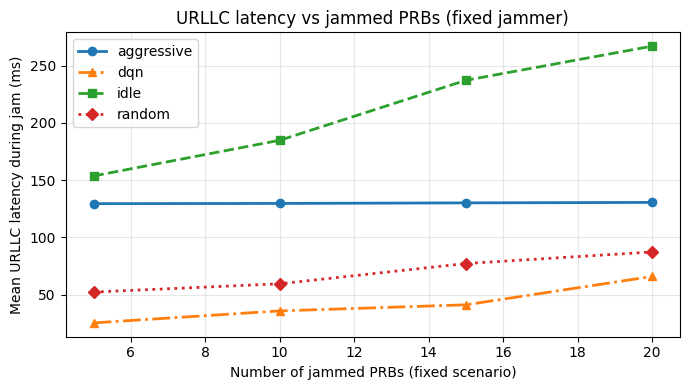

In [6]:
plt.figure(figsize=(7, 4))

for policy, g in df_lat.groupby("policy"):
    g = g.sort_values("jam_prb")
    st = STYLE.get(policy, DEFAULT_STYLE)
    plt.plot(
        g["jam_prb"], g["mean_latency_ms"],
        label=policy,
        linewidth=2,
        markersize=6,
        **st
    )

# baseline horizontal line
if np.isfinite(baseline_lat_ms):
    plt.axhline(
        baseline_lat_ms,
        linestyle="--",
        linewidth=2,
        label=f"baseline idle-nojam ({baseline_lat_ms:.2f} ms)"
    )

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean URLLC latency during jam (ms)")
plt.title("URLLC latency vs jammed PRBs (fixed jammer)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("urllc_latency_vs_jammed_prbs.png", dpi=300, bbox_inches="tight")
plt.show()


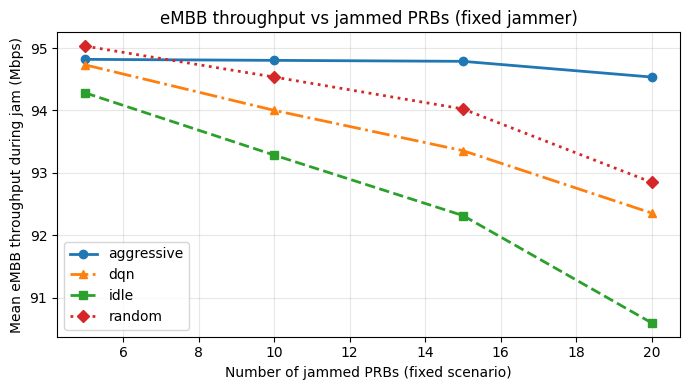

In [7]:
plt.figure(figsize=(7, 4))

for policy, g in df_thr.groupby("policy"):
    g = g.sort_values("jam_prb")
    st = STYLE.get(policy, DEFAULT_STYLE)
    plt.plot(
        g["jam_prb"], g["mean_embb_mbps"],
        label=policy,
        linewidth=2,
        markersize=6,
        **st
    )

if np.isfinite(baseline_thr_mbps):
    plt.axhline(
        baseline_thr_mbps,
        linestyle="--",
        linewidth=2,
        label=f"baseline idle-nojam ({baseline_thr_mbps:.2f} Mbps)"
    )

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean eMBB throughput during jam (Mbps)")
plt.title("eMBB throughput vs jammed PRBs (fixed jammer)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("embb_throughput_vs_jammed_prbs.png", dpi=300, bbox_inches="tight")
plt.show()


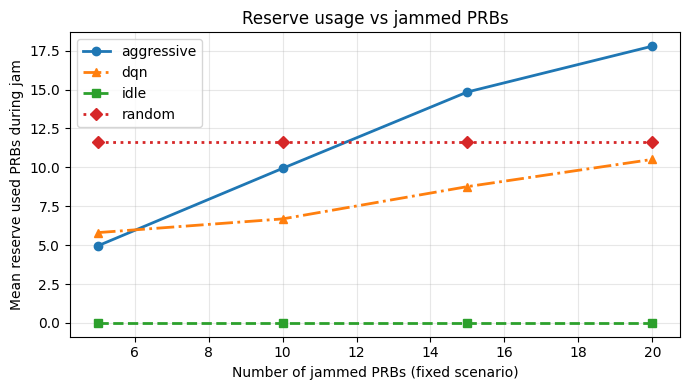

In [8]:
plt.figure(figsize=(7, 4))

for policy, g in df_prb.groupby("policy"):
    g = g.sort_values("jam_prb")
    st = STYLE.get(policy, DEFAULT_STYLE)
    plt.plot(
        g["jam_prb"], g["reserve_used_prb_mean"],
        label=policy,
        linewidth=2,
        markersize=6,
        **st
    )

if np.isfinite(baseline_rsv_prb):
    plt.axhline(
        baseline_rsv_prb,
        linestyle="--",
        linewidth=2,
        label=f"baseline idle-nojam ({baseline_rsv_prb:.2f} PRBs)"
    )

plt.xlabel("Number of jammed PRBs (fixed scenario)")
plt.ylabel("Mean reserve used PRBs during jam")
plt.title("Reserve usage vs jammed PRBs")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("reserve_usage_vs_jammed_prbs.png", dpi=300, bbox_inches="tight")
plt.show()


In [15]:
EPS = 1e-9

def mean_scalar(event_file: Path, tag: str, scale: float = 1.0) -> float:
    df = read_scalar_from_event(event_file, tag)
    if df.empty:
        return np.nan
    return float(df["value"].mean() * scale)

def find_event_file_direct(dir_with_events: Path) -> Path | None:
    if not dir_with_events.exists():
        return None
    candidates = list(dir_with_events.glob("events.out.tfevents.*"))
    if not candidates:
        return None
    candidates.sort(key=lambda p: p.stat().st_size, reverse=True)
    return candidates[0]


In [24]:
eff_rows = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    for pwr in POWERS:
        test_name = f"gym_from_testing_config_1ms_10s_8UE_jam_fixed_{pwr}"
        ev_file = find_event_file(policy_dir, test_name)

        if ev_file is None:
            print(f"[MISS] {policy:10s} pwr={pwr} -> event file NOT found at {policy_dir/test_name}")
            eff_rows.append({
                "policy": policy, "jam_prb": pwr,
                "thr_mbps": np.nan, "prb_used": np.nan, "lat_ms": np.nan,
                "thr_per_prb": np.nan, "invlat_per_prb": np.nan,
                "event_file": None
            })
            continue

        m_lat = mean_latency_during_jam(ev_file)              # ms
        m_thr = mean_embb_throughput_during_jam(ev_file)      # Mbps
        m_prb = mean_reserve_used_prb_during_jam(ev_file)     # PRBs

        # # efficiency (raw; may be inf/nan if prb_used ~ 0)
        # thr_per_prb = m_thr / m_prb if (np.isfinite(m_thr) and np.isfinite(m_prb) and m_prb > 0) else np.nan
        # invlat_per_prb = (1.0 / m_lat) / m_prb if (np.isfinite(m_lat) and m_lat > 0 and np.isfinite(m_prb) and m_prb > 0) else np.nan

        EPS = 1e-9
        PRB_MIN = 1e-3  # below this, reserve-efficiency is undefined

        thr_per_prb = np.nan
        invlat_per_prb = np.nan

        if np.isfinite(m_thr) and np.isfinite(m_prb) and m_prb > PRB_MIN:
            thr_per_prb = m_thr / (m_prb + EPS)

        if np.isfinite(m_lat) and m_lat > 0 and np.isfinite(m_prb) and m_prb > PRB_MIN:
            invlat_per_prb = (1.0 / m_lat) / (m_prb + EPS)

        eff_rows.append({
            "policy": policy, "jam_prb": pwr,
            "thr_mbps": m_thr, "prb_used": m_prb, "lat_ms": m_lat,
            "thr_per_prb": thr_per_prb,
            "invlat_per_prb": invlat_per_prb,
            "event_file": str(ev_file)
        })

df_eff = pd.DataFrame(eff_rows)

print("\nCounts per policy:")
print(df_eff.groupby("policy")["jam_prb"].count())

print("\nHow many event files were found per policy?")
print(df_eff["event_file"].notna().groupby(df_eff["policy"]).sum())

print("\nPreview:")
print(df_eff.head(20))


lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950
lent(jam(file)): 24950

Counts per policy:
policy
aggressive    4
dqn           4
idle          4
random        4
Name: jam_prb, dtype: int64

How many event files were found per policy?
policy
aggressive    4
dqn           4
idle          4
random        4
Name: event_file, dtype: int64

Preview:
        policy  jam_prb   thr_mbps   prb_used      lat_ms  thr_per_prb  \
0   aggressive        5  94.818603   4.951904  129.402536    19.147909   
1   aggressive       10  94.802386   9.935872  129.595947     9.541426   
2   aggressive       15  94.786921  14.847695  130.083542     6.383948   
3   aggressive       20  94.534907  17.791583  130.489663   

In [25]:
# ---- General baseline folder (directly under ROOT) ----
GENERAL_BASELINE_DIRNAME = "idle__20260120_092923__res18_off0_const0_per2500_dur1250"
general_baseline_dir = ROOT / GENERAL_BASELINE_DIRNAME
general_baseline_ev = find_event_file_direct(general_baseline_dir)

print("general_baseline_ev =", general_baseline_ev)

base_thr = np.nan
base_lat_ms = np.nan
base_prb = np.nan

base_thr_per_prb = np.nan
base_invlat_per_prb = np.nan

if general_baseline_ev is not None:
    base_thr    = mean_scalar(general_baseline_ev, "throughput/embb_mbps", scale=1.0)
    base_lat_ms = mean_scalar(general_baseline_ev, "latency/urllc", scale=1000.0)  # sec->ms
    base_prb    = mean_scalar(general_baseline_ev, "obs/reserve_used_prb", scale=1.0)

    # efficiencies (safe divide)
    if np.isfinite(base_thr) and np.isfinite(base_prb) and base_prb > EPS:
        base_thr_per_prb = base_thr / base_prb
    else:
        print(f"[WARN] baseline thr/prb not finite (thr={base_thr}, prb={base_prb}).")

    if np.isfinite(base_lat_ms) and base_lat_ms > EPS and np.isfinite(base_prb) and base_prb > EPS:
        base_invlat_per_prb = (1.0 / base_lat_ms) / base_prb  # 1/ms/PRB
    else:
        print(f"[WARN] baseline (1/lat)/prb not finite (lat_ms={base_lat_ms}, prb={base_prb}).")

print("baseline: thr=", base_thr, "lat_ms=", base_lat_ms, "prb=", base_prb)
print("baseline eff: thr_per_prb=", base_thr_per_prb, "invlat_per_prb=", base_invlat_per_prb)


general_baseline_ev = None
baseline: thr= nan lat_ms= nan prb= nan
baseline eff: thr_per_prb= nan invlat_per_prb= nan


In [26]:
def plot_eff(df_eff: pd.DataFrame, ycol: str, ylabel: str, title: str,
             baseline_y: float | None = None, baseline_label: str = "baseline"):
    plt.figure(figsize=(7, 4))
    for policy, g in df_eff.groupby("policy"):
        g = g.sort_values("jam_prb")
        st = STYLE.get(policy, dict(linestyle="-", marker="o"))
        plt.plot(
            g["jam_prb"], g[ycol],
            label=policy,
            linewidth=2,
            markersize=6,
            **st
        )

    if baseline_y is not None and np.isfinite(baseline_y):
        plt.axhline(
            baseline_y,
            linestyle="--",
            linewidth=2,
            color="black",
            alpha=0.7,
            label=baseline_label
        )
    elif baseline_y is not None:
        print(f"[WARN] Not plotting {baseline_label}: baseline value is NaN/inf.")

    plt.xlabel("Number of jammed PRBs (fixed scenario)")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(title+".png", dpi=300, bbox_inches="tight")
    plt.show()


[WARN] Not plotting general baseline: baseline value is NaN/inf.


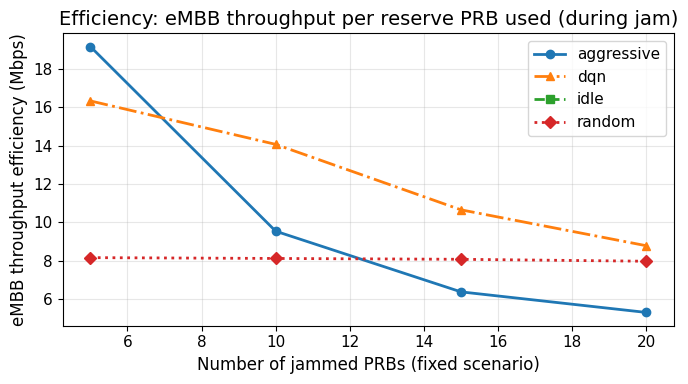

[WARN] Not plotting general baseline: baseline value is NaN/inf.


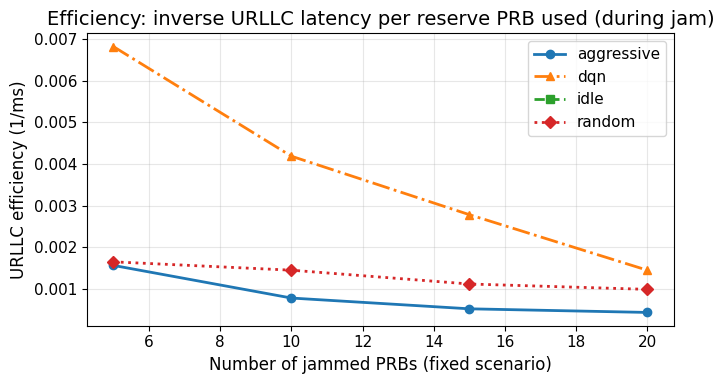

In [28]:
plot_eff(
    df_eff,
    ycol="thr_per_prb",
    ylabel="eMBB throughput efficiency (Mbps)",
    title="Efficiency: eMBB throughput per reserve PRB used (during jam)",
    baseline_y=base_thr_per_prb,
    baseline_label=f"general baseline ({base_thr_per_prb:.3f} Mbps/PRB)" if np.isfinite(base_thr_per_prb) else "general baseline"
)

plot_eff(
    df_eff,
    ycol="invlat_per_prb",
    ylabel="URLLC efficiency (1/ms)",
    title="Efficiency: inverse URLLC latency per reserve PRB used (during jam)",
    baseline_y=base_invlat_per_prb,
    baseline_label=f"general baseline ({base_invlat_per_prb:.6f} 1/ms/PRB)" if np.isfinite(base_invlat_per_prb) else "general baseline"
)


In [14]:
print(df_eff[["policy", "jam_prb", "thr_mbps", "prb_used", "thr_per_prb"]])


        policy  jam_prb   thr_mbps   prb_used  thr_per_prb
0   aggressive        5  94.818603   4.951904    19.147909
1   aggressive       10  94.802386   9.935872     9.541426
2   aggressive       15  94.786921  14.847695     6.383948
3   aggressive       20  94.534907  17.791583     5.313462
4         idle        5  94.280645   0.000000          NaN
5         idle       10  93.284532   0.000000          NaN
6         idle       15  92.315348   0.000000          NaN
7         idle       20  90.594324   0.000000          NaN
8          dqn        5  94.729615   5.803848    16.321864
9          dqn       10  94.001308   6.685491    14.060494
10         dqn       15  93.355165   8.762164    10.654350
11         dqn       20  92.354689  10.511543     8.786026
12      random        5  95.029930  11.638076     8.165433
13      random       10  94.535195  11.638076     8.122923
14      random       15  94.023732  11.638076     8.078975
15      random       20  92.847678  11.638076     7.9779

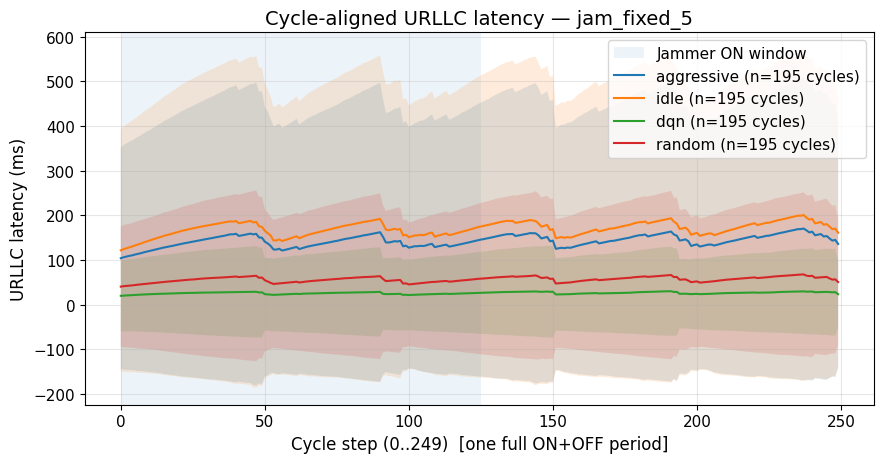

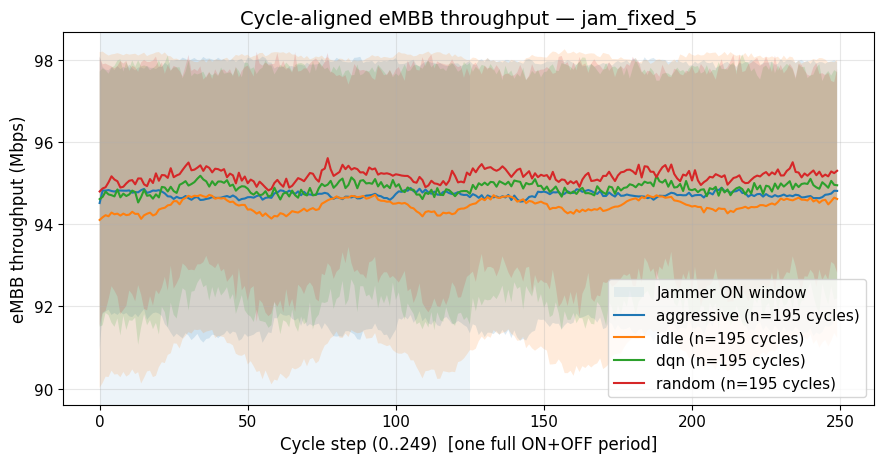

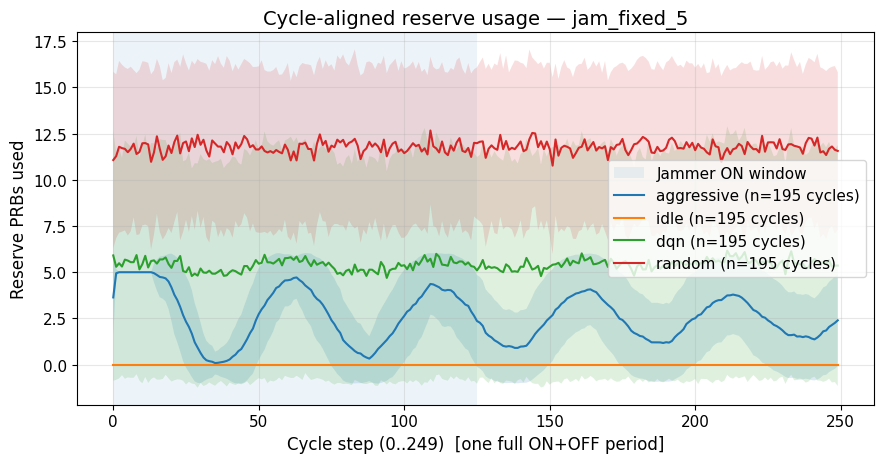

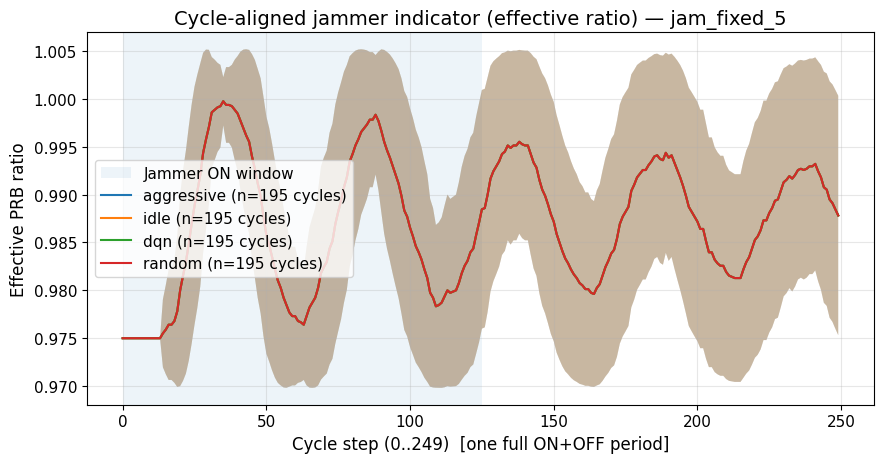

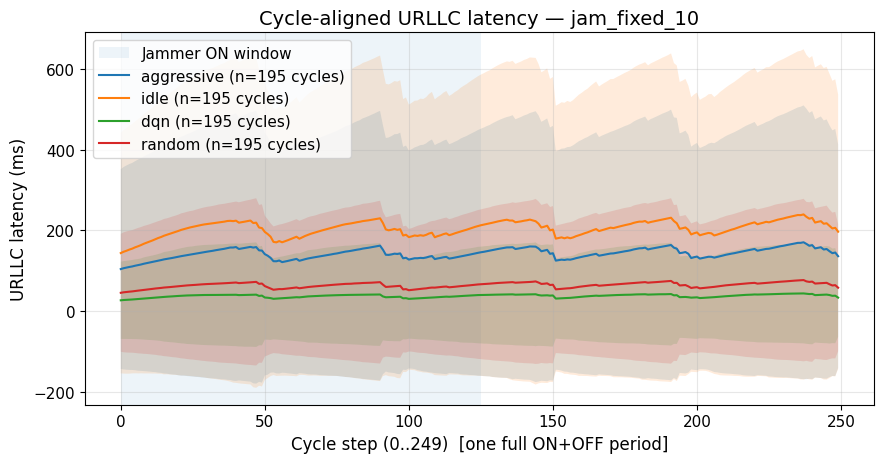

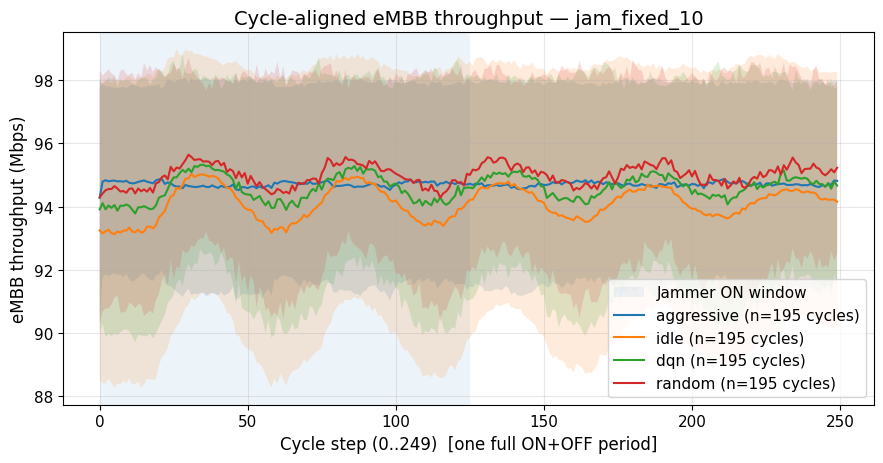

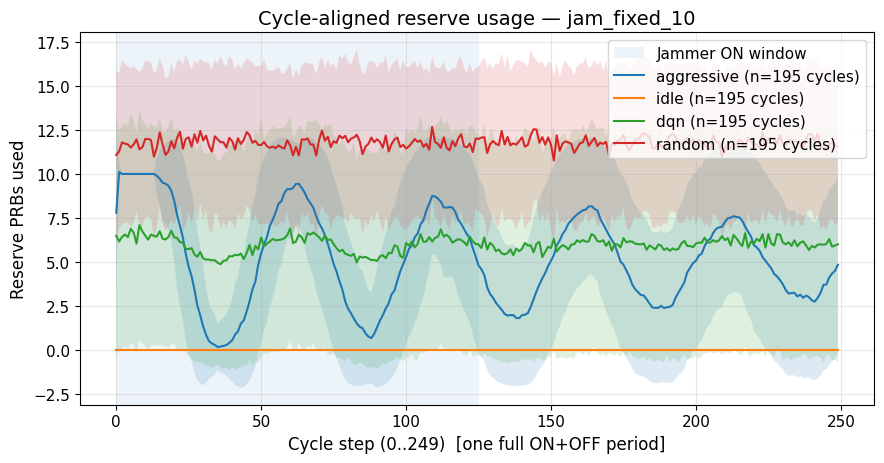

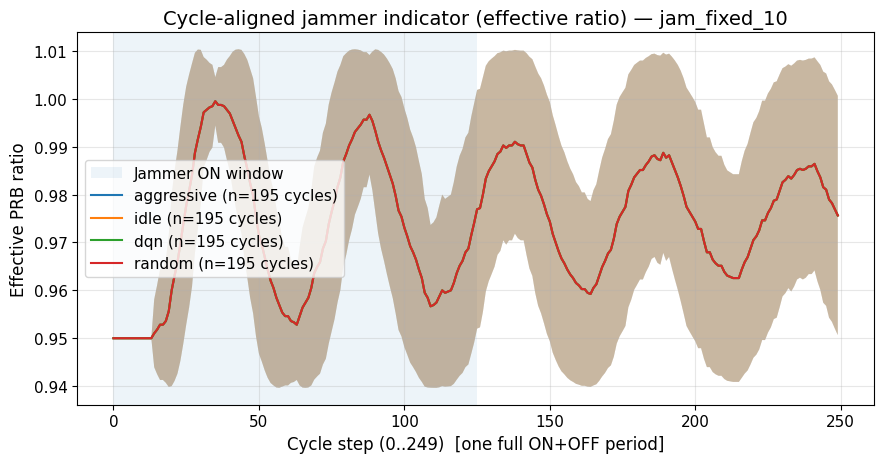

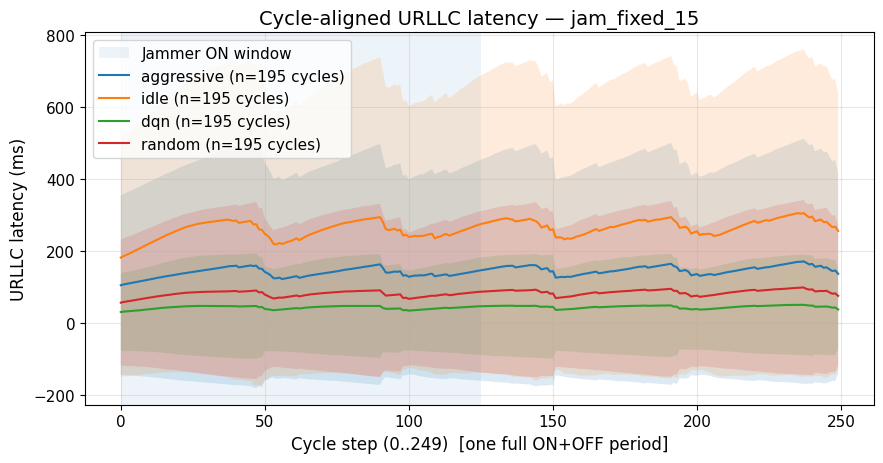

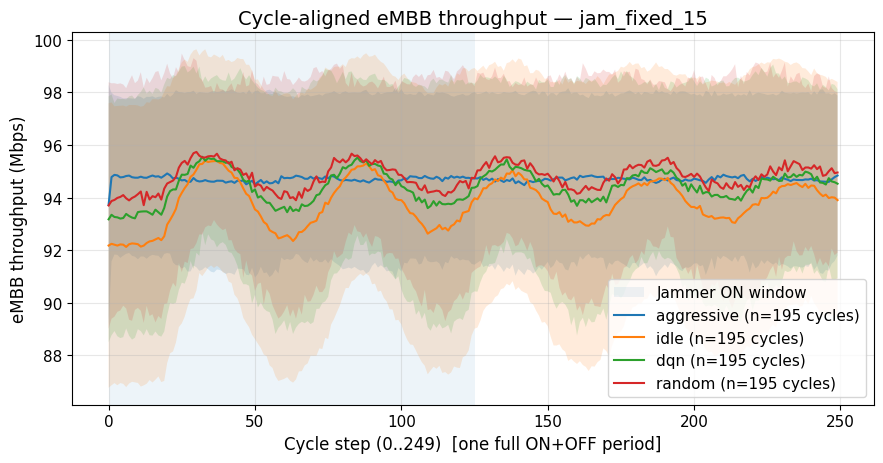

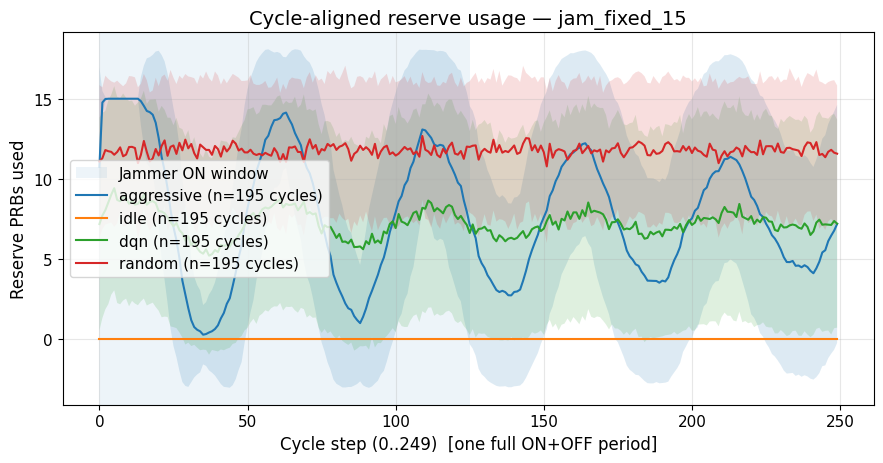

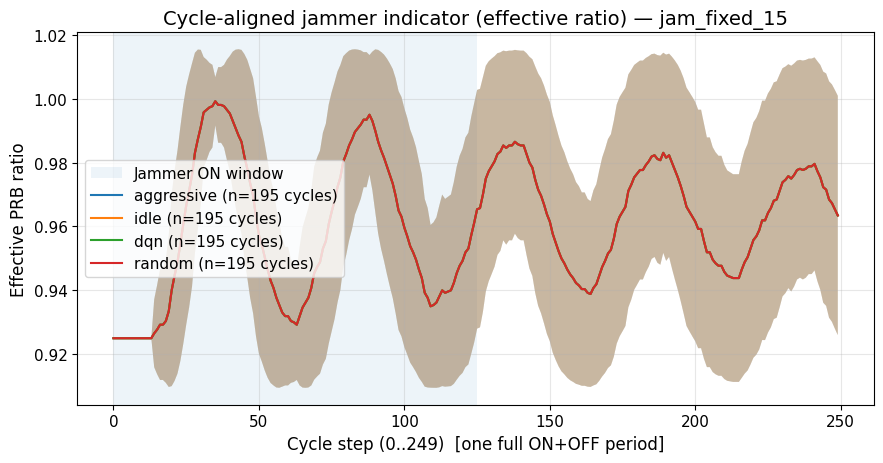

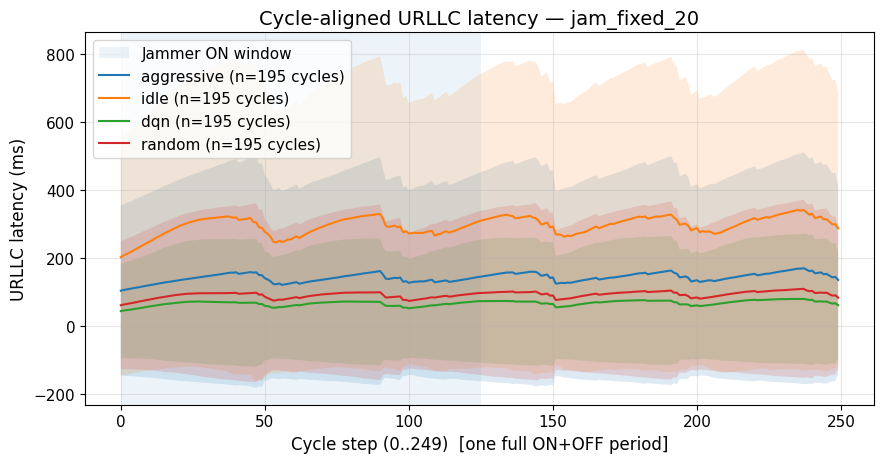

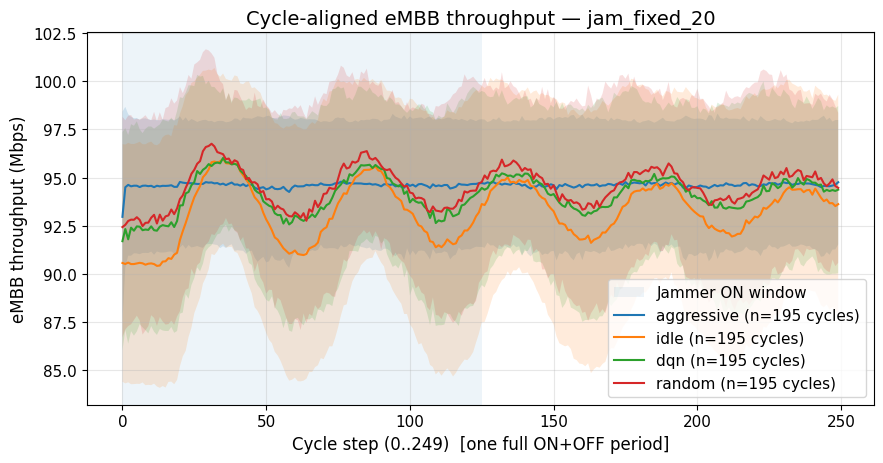

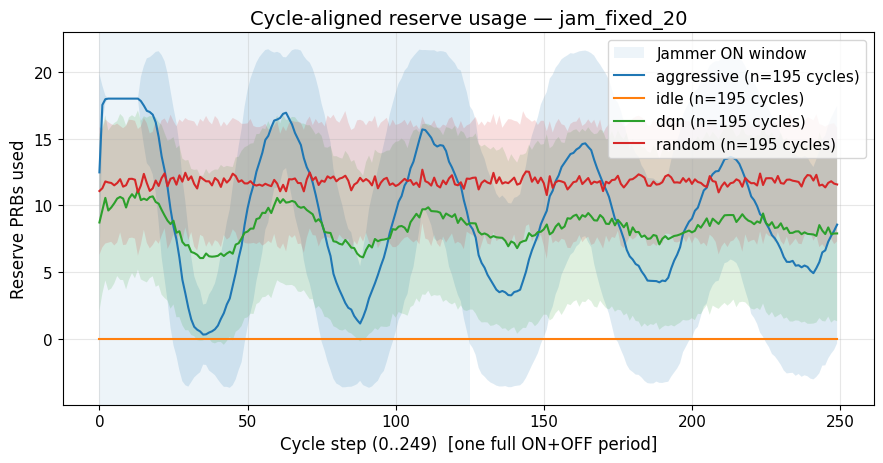

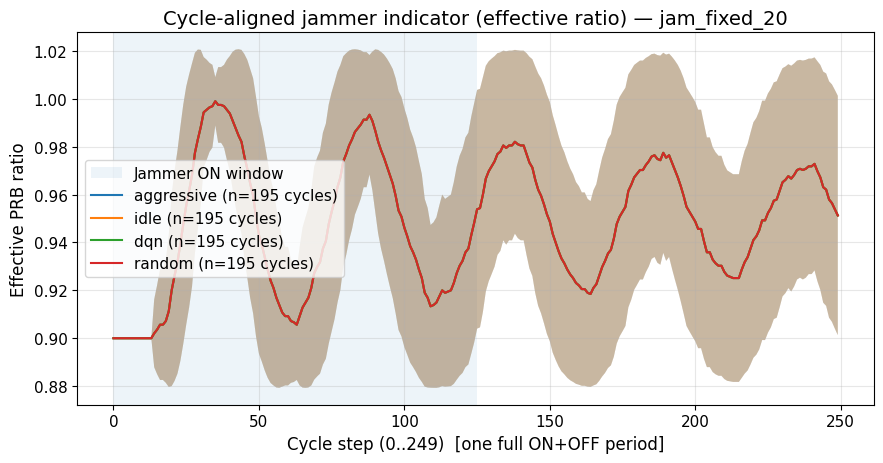

In [50]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# ----------------------------
# EDIT THESE
# ----------------------------
TB_ROOT   = Path("../../tb_logs/23_jan")
POLICIES  = ["aggressive", "idle", "dqn", "random"]
SEVERITY  = [5, 10, 15, 20]  # jam_fixed_5/10/15/20

EFF_TAG   = "prb/effective_ratio"
LAT_TAG   = "latency/urllc"          # seconds -> convert to ms
THR_TAG   = "throughput/embb_mbps"
RES_TAG   = "obs/reserve_used_prb"

JAM_THRESH = 0.999

# Your sim config (typical in your project)
EP_LEN_SIM = 10000        # sim steps per episode
EP_LEN_DEC = 1000         # decision steps per episode (TB "step" is usually decision steps)
SIM_PER_DEC = EP_LEN_SIM / EP_LEN_DEC  # usually 10

JAM_PERIOD_SIM = 2500     # sim steps (ON+OFF)
JAM_ON_SIM     = 1250     # sim steps (ON only)

# Convert to TB step units (decision steps)
JAM_PERIOD = int(round(JAM_PERIOD_SIM / SIM_PER_DEC))  # e.g., 250
JAM_ON     = int(round(JAM_ON_SIM / SIM_PER_DEC))      # e.g., 125

# Folder matching (adjust if your structure differs)
FIXED_FOLDER_REGEX = re.compile(r"jam_fixed_(\d+)$", re.IGNORECASE)

# ----------------------------
# Helpers
# ----------------------------
def load_scalar_df(event_file: Path, tags):
    ea = EventAccumulator(str(event_file))
    ea.Reload()
    out = {}
    for tag in tags:
        if tag not in ea.Tags().get("scalars", []):
            out[tag] = pd.DataFrame(columns=["step", "value"])
            continue
        evs = ea.Scalars(tag)
        out[tag] = pd.DataFrame({"step":[e.step for e in evs], "value":[e.value for e in evs]})
    return out

def find_event_file(run_dir: Path):
    # pick the first events file (or newest). Adjust if needed.
    evs = sorted(run_dir.rglob("events.out.tfevents.*"))
    return evs[-1] if evs else None

def detect_jam_starts(eff: np.ndarray, thresh: float):
    jam = eff < thresh
    starts = np.where((jam[1:] == True) & (jam[:-1] == False))[0] + 1
    return starts

def extract_cycles(series: np.ndarray, starts: np.ndarray, cycle_len: int):
    cycles = []
    n = len(series)
    for s in starts:
        e = s + cycle_len
        if e <= n:
            cycles.append(series[s:e])
    return np.array(cycles) if cycles else np.empty((0, cycle_len))

def mean_std_band(cycles_2d: np.ndarray):
    if cycles_2d.size == 0:
        return None, None
    return cycles_2d.mean(axis=0), cycles_2d.std(axis=0)

# ----------------------------
# Main: build cycle-aligned averages per (severity, policy)
# ----------------------------
results = {}  # results[(sev, policy)] = dict(metric -> (mean, std))

for sev in SEVERITY:
    for pol in POLICIES:
        # Find run folder for this policy + severity
        # Assumption: TB_ROOT/<policy>/.../gym_from_testing_..._jam_fixed_<sev>
        # If your structure is different, just set run_dir manually.
        cand = []
        for d in TB_ROOT.rglob("*"):
            if d.is_dir() and d.name.lower().endswith(f"jam_fixed_{sev}") and pol.lower() in str(d).lower():
                cand.append(d)
        run_dir = sorted(cand, key=lambda x: len(str(x)))[0] if cand else None

        if run_dir is None:
            print(f"[WARN] No run_dir found for policy={pol}, sev={sev}")
            continue

        event_file = find_event_file(run_dir)
        if event_file is None:
            print(f"[WARN] No event file for {run_dir}")
            continue

        dfs = load_scalar_df(event_file, [EFF_TAG, LAT_TAG, THR_TAG, RES_TAG])

        # Merge on step (outer), then forward-fill within gaps
        df = dfs[EFF_TAG].rename(columns={"value": EFF_TAG})
        for tag in [LAT_TAG, THR_TAG, RES_TAG]:
            df = df.merge(dfs[tag].rename(columns={"value": tag}), on="step", how="outer")

        df = df.sort_values("step").reset_index(drop=True).ffill()

        eff = df[EFF_TAG].to_numpy(dtype=float)

        # pick a representative metric sampling (same length)
        lat = df[LAT_TAG].to_numpy(dtype=float) * 1000.0  # ms
        thr = df[THR_TAG].to_numpy(dtype=float)
        res = df[RES_TAG].to_numpy(dtype=float)

        starts = detect_jam_starts(eff, JAM_THRESH)

        eff_cycles = extract_cycles(eff, starts, JAM_PERIOD)
        lat_cycles = extract_cycles(lat, starts, JAM_PERIOD)
        thr_cycles = extract_cycles(thr, starts, JAM_PERIOD)
        res_cycles = extract_cycles(res, starts, JAM_PERIOD)

        results[(sev, pol)] = {}
        for name, cyc in [("eff", eff_cycles), ("lat_ms", lat_cycles), ("thr_mbps", thr_cycles), ("reserve_prb", res_cycles)]:
            m, s = mean_std_band(cyc)
            results[(sev, pol)][name] = (m, s, cyc.shape[0])  # include num cycles

# ----------------------------
# Plotter: one figure per severity, overlay policies
# ----------------------------
def plot_cycle_metric(sev, metric_key, ylabel, title):
    x = np.arange(JAM_PERIOD)

    plt.figure(figsize=(9, 4.8))

    # Optional: show jammer ON region
    plt.axvspan(0, JAM_ON, alpha=0.08, label="Jammer ON window")

    for pol in POLICIES:
        key = (sev, pol)
        if key not in results or results[key][metric_key][0] is None:
            continue
        mean, std, ncyc = results[key][metric_key]
        plt.plot(x, mean, label=f"{pol} (n={ncyc} cycles)")
        plt.fill_between(x, mean-std, mean+std, alpha=0.15)

    plt.xlabel(f"Cycle step (0..{JAM_PERIOD-1})  [one full ON+OFF period]")
    plt.ylabel(ylabel)
    plt.title(f"{title} — jam_fixed_{sev}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

for sev in SEVERITY:
    plot_cycle_metric(sev, "lat_ms", "URLLC latency (ms)", "Cycle-aligned URLLC latency")
    plot_cycle_metric(sev, "thr_mbps", "eMBB throughput (Mbps)", "Cycle-aligned eMBB throughput")
    plot_cycle_metric(sev, "reserve_prb", "Reserve PRBs used", "Cycle-aligned reserve usage")
    plot_cycle_metric(sev, "eff", "Effective PRB ratio", "Cycle-aligned jammer indicator (effective ratio)")


2026-01-25 20:01:21.686922: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-25 20:01:21.719401: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-25 20:01:22.435075: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


[INFO] Detected TB step scale = decision
[INFO] Using JAM_PERIOD=250, JAM_ON=125 in TB steps


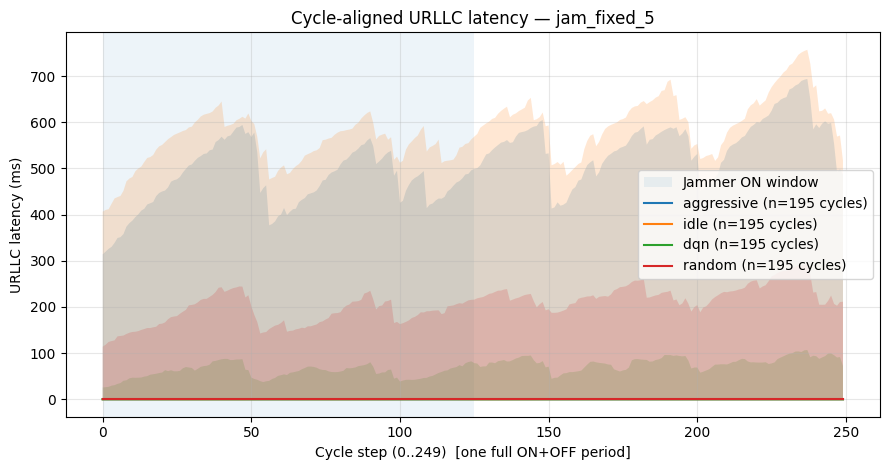

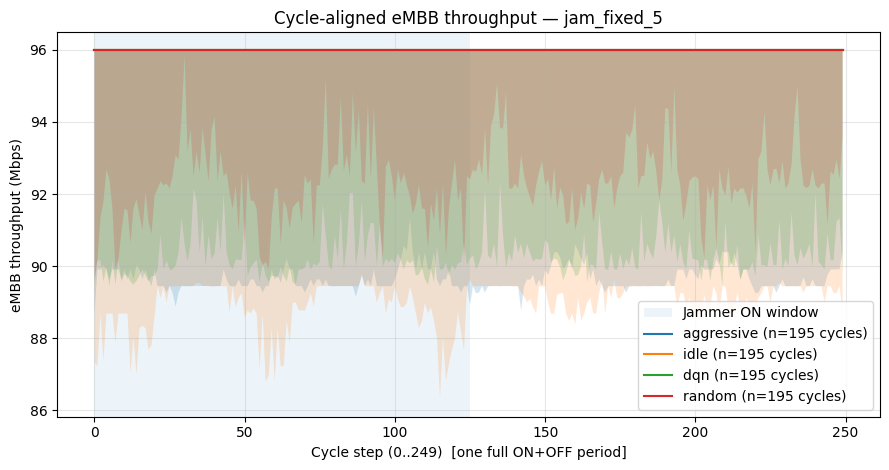

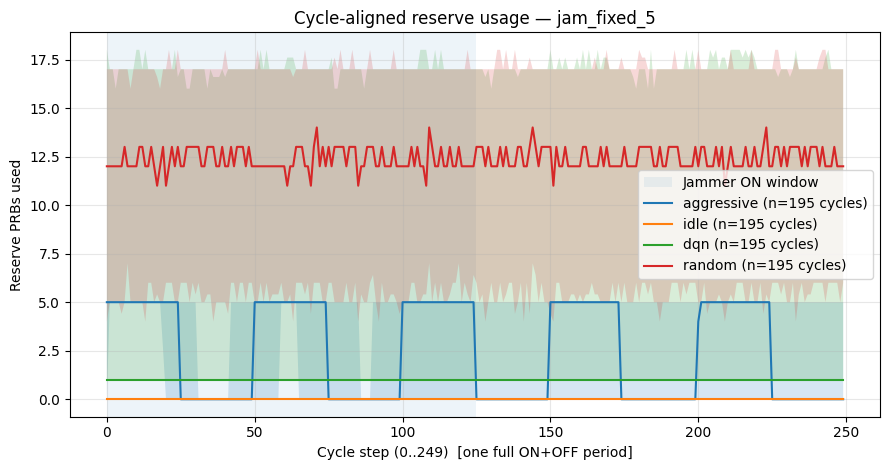

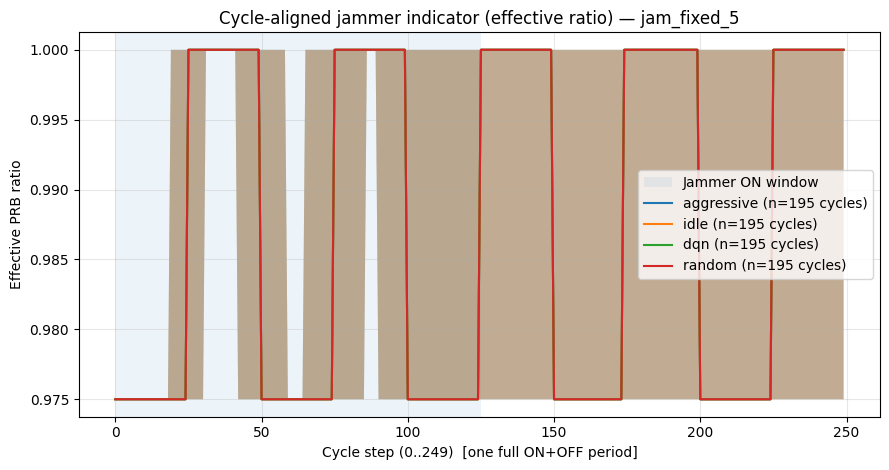

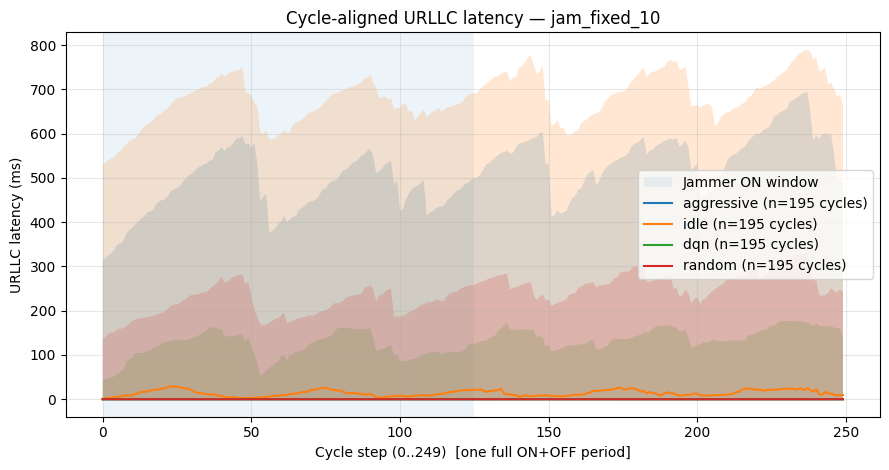

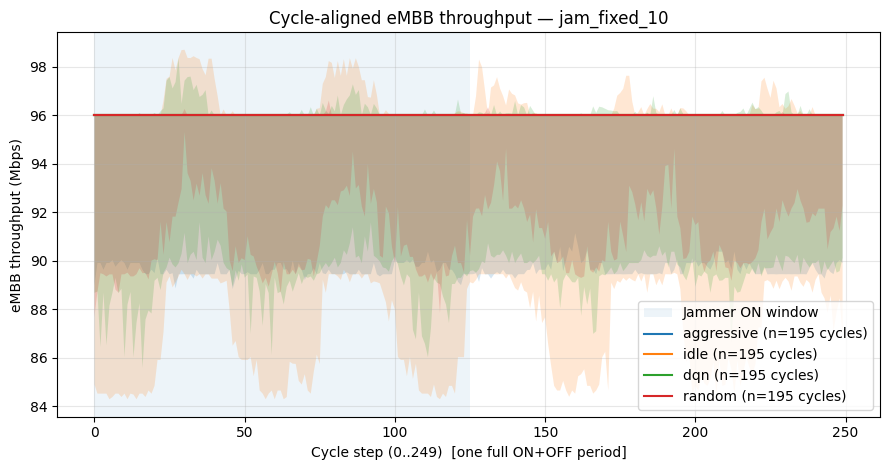

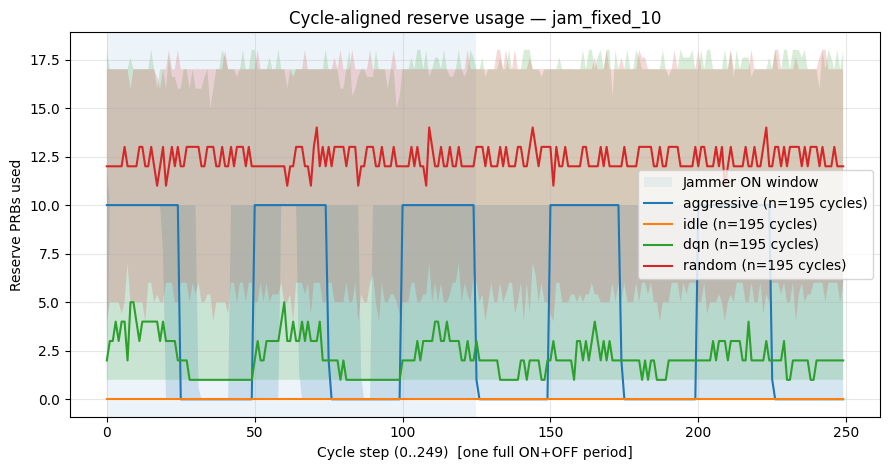

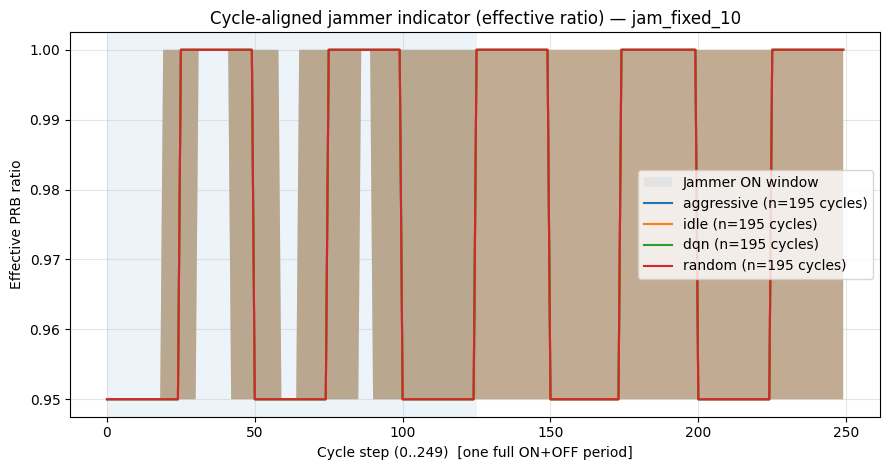

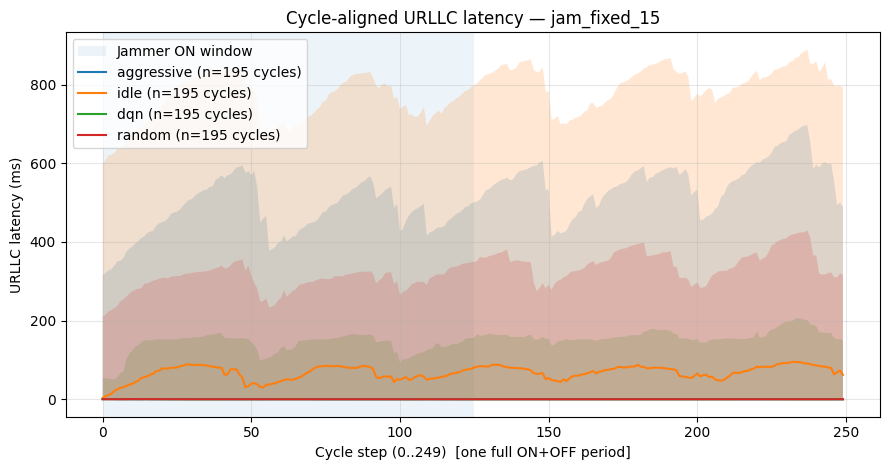

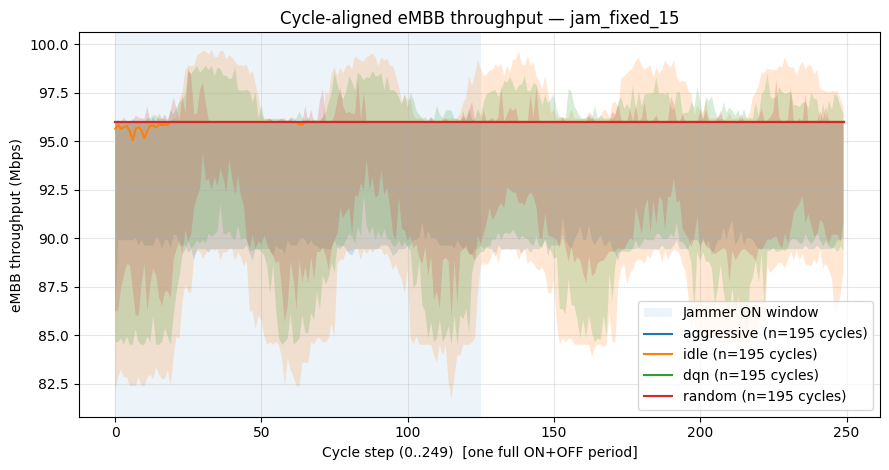

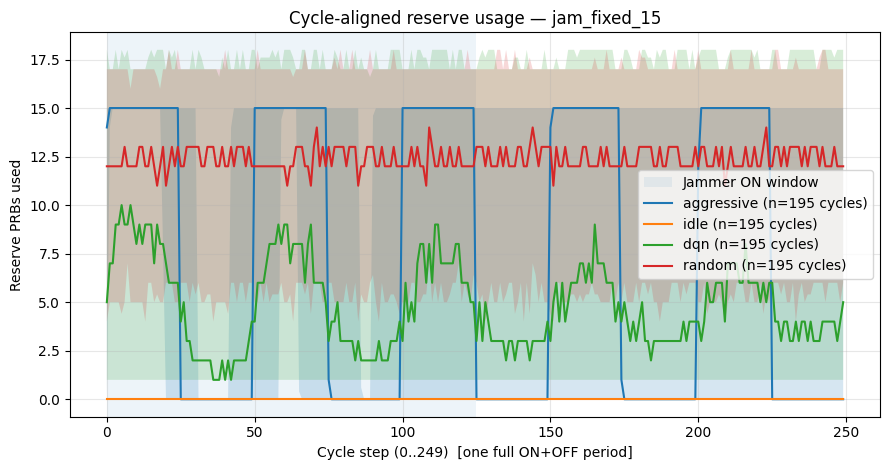

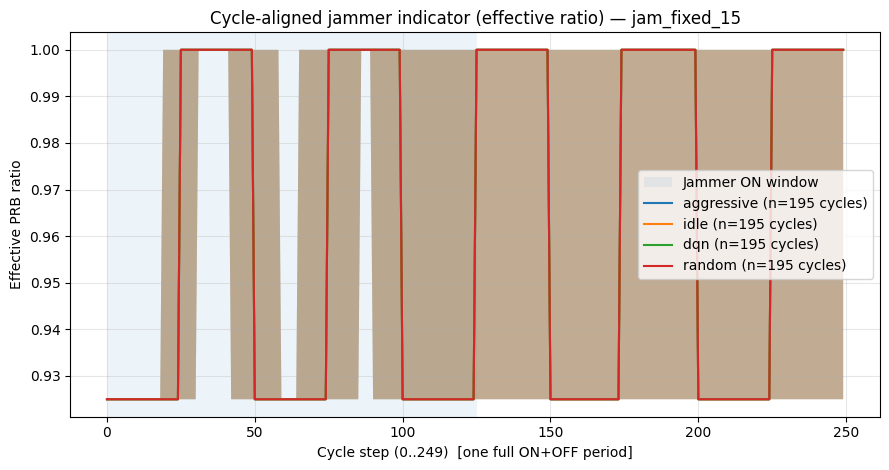

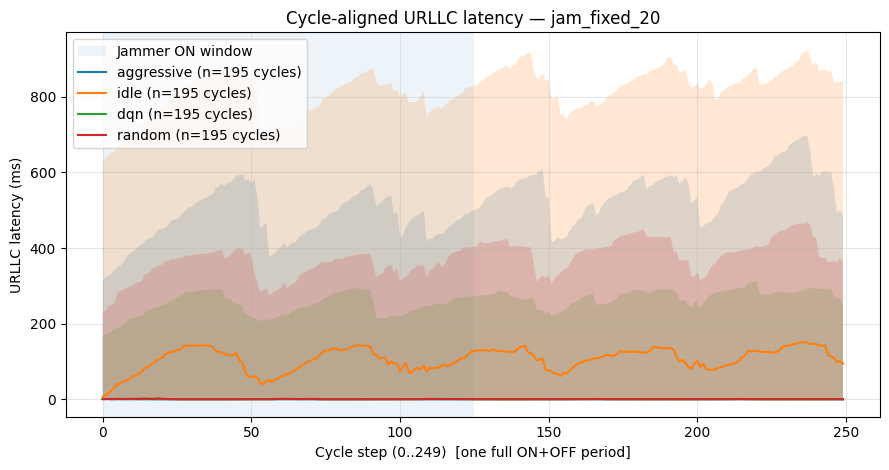

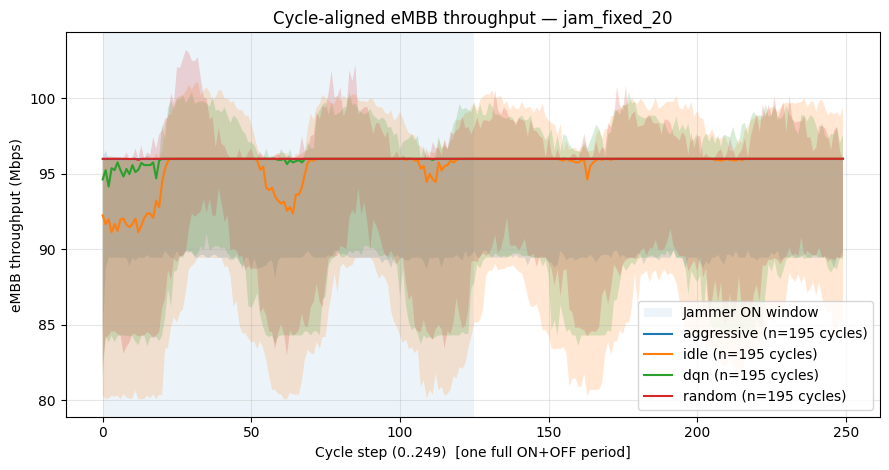

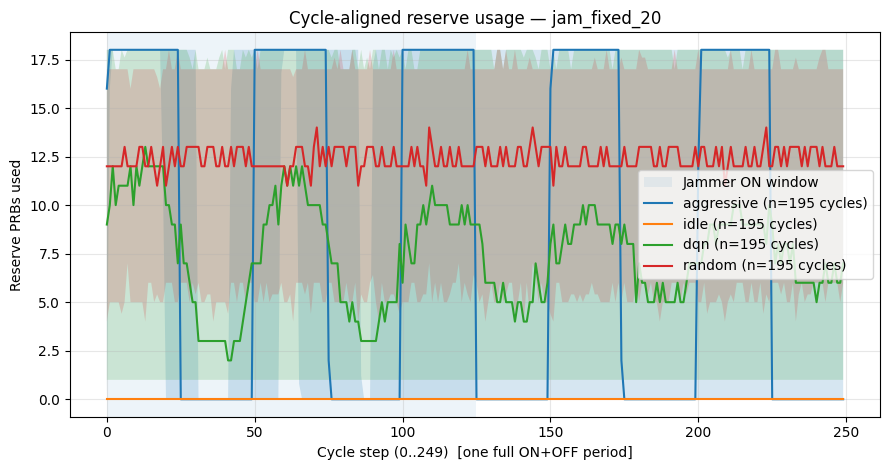

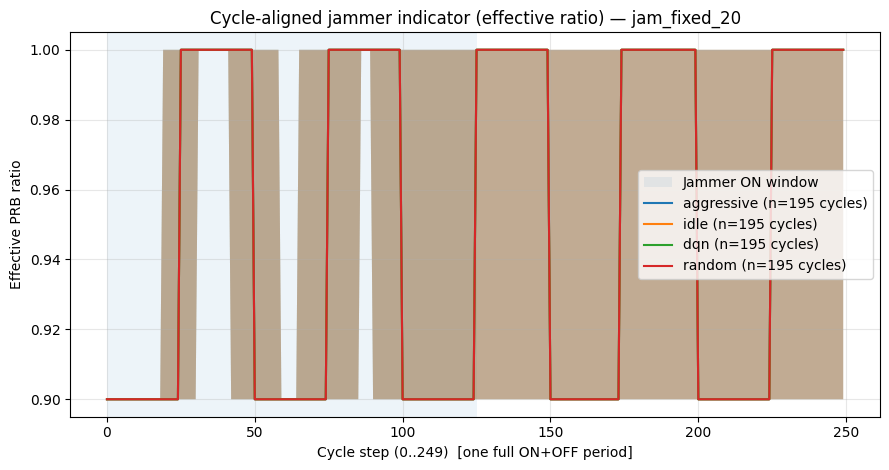

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# ----------------------------
# EDIT THESE
# ----------------------------
TB_ROOT   = Path("../../tb_logs/23_jan")
POLICIES  = ["aggressive", "idle", "dqn", "random"]
SEVERITY  = [5, 10, 15, 20]  # jam_fixed_5/10/15/20

EFF_TAG   = "prb/effective_ratio"
LAT_TAG   = "latency/urllc"          # seconds -> convert to ms
THR_TAG   = "throughput/embb_mbps"
RES_TAG   = "obs/reserve_used_prb"

JAM_THRESH = 0.999

# Your jammer config (SIMULATION steps)
JAM_PERIOD_SIM = 2500     # ON+OFF
JAM_ON_SIM     = 1250     # ON only

# Folder matching
FIXED_FOLDER_REGEX = re.compile(r"jam_fixed_(\d+)$", re.IGNORECASE)

# ----------------------------
# Helpers
# ----------------------------
def load_scalar_df(event_file: Path, tags):
    ea = EventAccumulator(str(event_file))
    ea.Reload()
    out = {}
    scalar_tags = set(ea.Tags().get("scalars", []))
    for tag in tags:
        if tag not in scalar_tags:
            out[tag] = pd.DataFrame(columns=["step", "value"])
            continue
        evs = ea.Scalars(tag)
        out[tag] = pd.DataFrame({"step":[e.step for e in evs], "value":[e.value for e in evs]})
    return out

def find_event_file(run_dir: Path):
    evs = sorted(run_dir.rglob("events.out.tfevents.*"))
    return evs[-1] if evs else None

def detect_jam_starts(eff: np.ndarray, thresh: float):
    jam = eff < thresh
    starts = np.where((jam[1:] == True) & (jam[:-1] == False))[0] + 1
    return starts

def extract_cycles(series: np.ndarray, starts: np.ndarray, cycle_len: int):
    cycles = []
    n = len(series)
    for s in starts:
        e = s + cycle_len
        if e <= n:
            cycles.append(series[s:e])
    return np.array(cycles) if cycles else np.empty((0, cycle_len))

def robust_band(cycles_2d: np.ndarray, qlo=0.10, qhi=0.90):
    """
    Better than mean±std for paper plots.
    Returns median + quantile band.
    """
    if cycles_2d.size == 0:
        return None, None, None
    med = np.median(cycles_2d, axis=0)
    lo  = np.quantile(cycles_2d, qlo, axis=0)
    hi  = np.quantile(cycles_2d, qhi, axis=0)
    return med, lo, hi

def infer_step_scale(df_steps: np.ndarray):
    """
    Heuristic: if we see ~10000 points per episode and step jumps like sim steps,
    treat TB steps as simulation steps.
    Your log showed 10000 points per episode and jam period ~2500 in TB steps => SIM.
    """
    # If step differences are mostly 1, it's sim-step logging.
    diffs = np.diff(df_steps)
    frac_ones = np.mean(diffs == 1) if len(diffs) else 0.0
    return "sim" if frac_ones > 0.5 else "decision"

# ----------------------------
# Main: build cycle-aligned averages per (severity, policy)
# ----------------------------
results = {}  # results[(sev, policy)] = dict(metric -> (med, lo, hi, ncycles))

# We will decide JAM_PERIOD/JAM_ON based on what the first run indicates.
STEP_SCALE = None
JAM_PERIOD = None
JAM_ON = None

for sev in SEVERITY:
    for pol in POLICIES:
        # Find run folder for this policy + severity
        cand = []
        for d in TB_ROOT.rglob("*"):
            if d.is_dir() and d.name.lower().endswith(f"jam_fixed_{sev}") and pol.lower() in str(d).lower():
                cand.append(d)
        run_dir = sorted(cand, key=lambda x: len(str(x)))[0] if cand else None
        if run_dir is None:
            print(f"[WARN] No run_dir found for policy={pol}, sev={sev}")
            continue

        event_file = find_event_file(run_dir)
        if event_file is None:
            print(f"[WARN] No event file for {run_dir}")
            continue

        dfs = load_scalar_df(event_file, [EFF_TAG, LAT_TAG, THR_TAG, RES_TAG])

        # Merge on step (outer), then forward-fill
        df = dfs[EFF_TAG].rename(columns={"value": EFF_TAG})
        for tag in [LAT_TAG, THR_TAG, RES_TAG]:
            df = df.merge(dfs[tag].rename(columns={"value": tag}), on="step", how="outer")
        df = df.sort_values("step").reset_index(drop=True).ffill()

        steps = df["step"].to_numpy(dtype=int)

        # Decide step scale once (using first available run)
        if STEP_SCALE is None:
            STEP_SCALE = infer_step_scale(steps)
            if STEP_SCALE == "sim":
                JAM_PERIOD = JAM_PERIOD_SIM
                JAM_ON     = JAM_ON_SIM
            else:
                # If truly decision-step logs, you'd need your SIM_PER_DEC factor
                # (keeping this for completeness)
                EP_LEN_SIM = 10000
                EP_LEN_DEC = 1000
                SIM_PER_DEC = EP_LEN_SIM / EP_LEN_DEC  # 10
                JAM_PERIOD = int(round(JAM_PERIOD_SIM / SIM_PER_DEC))
                JAM_ON     = int(round(JAM_ON_SIM / SIM_PER_DEC))
            print(f"[INFO] Detected TB step scale = {STEP_SCALE}")
            print(f"[INFO] Using JAM_PERIOD={JAM_PERIOD}, JAM_ON={JAM_ON} in TB steps")

        eff = df[EFF_TAG].to_numpy(dtype=float)
        lat = df[LAT_TAG].to_numpy(dtype=float) * 1000.0  # ms
        thr = df[THR_TAG].to_numpy(dtype=float)
        res = df[RES_TAG].to_numpy(dtype=float)

        starts = detect_jam_starts(eff, JAM_THRESH)

        eff_cycles = extract_cycles(eff, starts, JAM_PERIOD)
        lat_cycles = extract_cycles(lat, starts, JAM_PERIOD)
        thr_cycles = extract_cycles(thr, starts, JAM_PERIOD)
        res_cycles = extract_cycles(res, starts, JAM_PERIOD)

        results[(sev, pol)] = {}
        for name, cyc in [("eff", eff_cycles), ("lat_ms", lat_cycles), ("thr_mbps", thr_cycles), ("reserve_prb", res_cycles)]:
            med, lo, hi = robust_band(cyc, 0.10, 0.90)
            results[(sev, pol)][name] = (med, lo, hi, cyc.shape[0])

# ----------------------------
# Plotter
# ----------------------------
def plot_cycle_metric(sev, metric_key, ylabel, title, clip_floor=None):
    x = np.arange(JAM_PERIOD)

    plt.figure(figsize=(9, 4.8))
    plt.axvspan(0, JAM_ON, alpha=0.08, label="Jammer ON window")

    for pol in POLICIES:
        key = (sev, pol)
        if key not in results:
            continue
        med, lo, hi, ncyc = results[key][metric_key]
        if med is None:
            continue

        if clip_floor is not None:
            lo = np.maximum(lo, clip_floor)
            hi = np.maximum(hi, clip_floor)
            med = np.maximum(med, clip_floor)

        plt.plot(x, med, label=f"{pol} (n={ncyc} cycles)")
        plt.fill_between(x, lo, hi, alpha=0.18)

    plt.xlabel(f"Cycle step (0..{JAM_PERIOD-1})  [one full ON+OFF period]")
    plt.ylabel(ylabel)
    plt.title(f"{title} — jam_fixed_{sev}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

for sev in SEVERITY:
    plot_cycle_metric(sev, "lat_ms", "URLLC latency (ms)", "Cycle-aligned URLLC latency", clip_floor=0.0)
    plot_cycle_metric(sev, "thr_mbps", "eMBB throughput (Mbps)", "Cycle-aligned eMBB throughput")
    plot_cycle_metric(sev, "reserve_prb", "Reserve PRBs used", "Cycle-aligned reserve usage", clip_floor=0.0)
    plot_cycle_metric(sev, "eff", "Effective PRB ratio", "Cycle-aligned jammer indicator (effective ratio)")


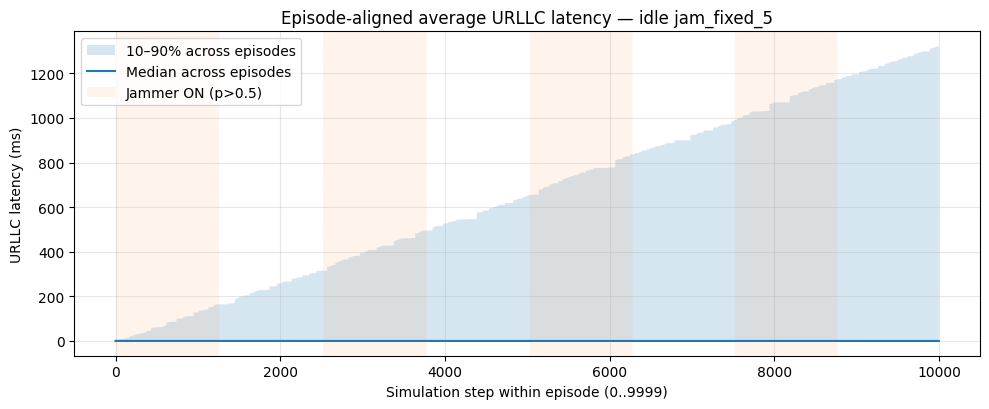

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

TB_ROOT   = Path("../../tb_logs/23_jan")
POLICY    = "idle"
SEV       = 5

EFF_TAG   = "prb/effective_ratio"
LAT_TAG   = "latency/urllc"
THR_TAG   = "throughput/embb_mbps"
RES_TAG   = "obs/reserve_used_prb"

EP_LEN_SIM = 10000
JAM_THRESH = 0.999

# --- find event file ---
run_dir = next(d for d in TB_ROOT.rglob("*") if d.is_dir() and d.name.lower().endswith(f"jam_fixed_{SEV}") and POLICY in str(d).lower())
event_file = sorted(run_dir.rglob("events.out.tfevents.*"))[-1]

ea = EventAccumulator(str(event_file))
ea.Reload()

def get_series(tag):
    evs = ea.Scalars(tag)
    df = pd.DataFrame({"step":[e.step for e in evs], "val":[e.value for e in evs]}).sort_values("step")
    df = df.drop_duplicates("step", keep="last").reset_index(drop=True)
    return df

# load + merge
df = get_series(EFF_TAG).rename(columns={"val":EFF_TAG})
for tag in [LAT_TAG, THR_TAG, RES_TAG]:
    df = df.merge(get_series(tag).rename(columns={"val":tag}), on="step", how="outer")
df = df.sort_values("step").ffill().reset_index(drop=True)

# convert units
df[LAT_TAG] = df[LAT_TAG] * 1000.0  # ms

# assign episode + within-episode time
df["ep"] = (df["step"] // EP_LEN_SIM).astype(int)
df["t"]  = (df["step"] %  EP_LEN_SIM).astype(int)

def episode_matrix(col):
    # build matrix [num_eps, EP_LEN_SIM]
    num_eps = df["ep"].max() + 1
    M = np.full((num_eps, EP_LEN_SIM), np.nan, dtype=float)
    sub = df[["ep","t",col]].dropna()
    M[sub["ep"].to_numpy(), sub["t"].to_numpy()] = sub[col].to_numpy()
    # fill missing within each episode (rare)
    M = pd.DataFrame(M).ffill(axis=1).bfill(axis=1).to_numpy()
    return M

# build matrices
lat_M = episode_matrix(LAT_TAG)
thr_M = episode_matrix(THR_TAG)
res_M = episode_matrix(RES_TAG)
eff_M = episode_matrix(EFF_TAG)

# robust average (median + 10-90 band)
def median_band(M):
    med = np.nanmedian(M, axis=0)
    lo  = np.nanquantile(M, 0.10, axis=0)
    hi  = np.nanquantile(M, 0.90, axis=0)
    return med, lo, hi

lat_med, lat_lo, lat_hi = median_band(lat_M)
thr_med, thr_lo, thr_hi = median_band(thr_M)

def mean_band(M):
    mean = np.nanmean(M, axis=0)
    std  = np.nanstd(M, axis=0)
    return mean, std

lat_mean, lat_std = mean_band(lat_M)
thr_mean, thr_std = mean_band(thr_M)


# jam probability shading over the episode timeline
p_jam = np.nanmean(eff_M < JAM_THRESH, axis=0)

# ---- plot latency (episode-average) ----
x = np.arange(EP_LEN_SIM)

plt.figure(figsize=(10,4.2))
plt.fill_between(x, lat_lo, lat_hi, alpha=0.18, label="10–90% across episodes")
plt.plot(x, lat_med, label="Median across episodes")

# shade where jammer is usually ON
plt.fill_between(x, 0, 1, where=(p_jam > 0.5), transform=plt.gca().get_xaxis_transform(),
                 alpha=0.08, label="Jammer ON (p>0.5)")

plt.title(f"Episode-aligned average URLLC latency — {POLICY} jam_fixed_{SEV}")
plt.xlabel("Simulation step within episode (0..9999)")
plt.ylabel("URLLC latency (ms)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


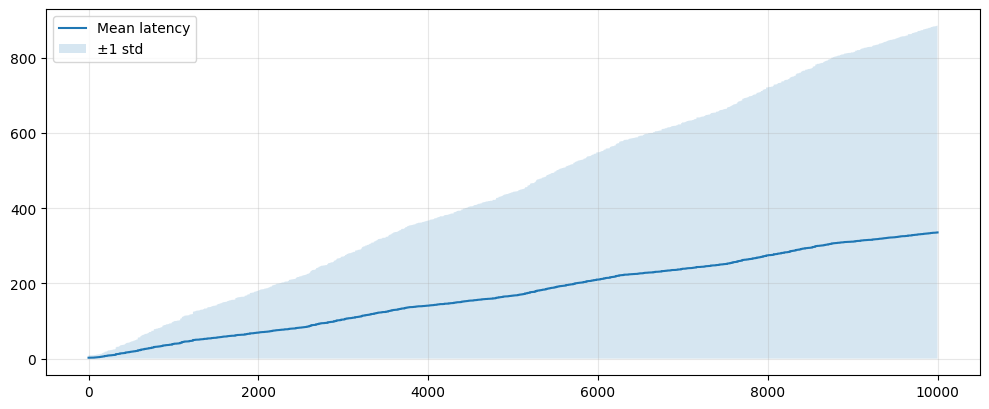

In [4]:
x = np.arange(EP_LEN_SIM)

plt.figure(figsize=(10,4.2))
plt.plot(x, lat_mean, label="Mean latency")
plt.fill_between(x, np.maximum(lat_mean-lat_std, 0), lat_mean+lat_std, alpha=0.18, label="±1 std")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


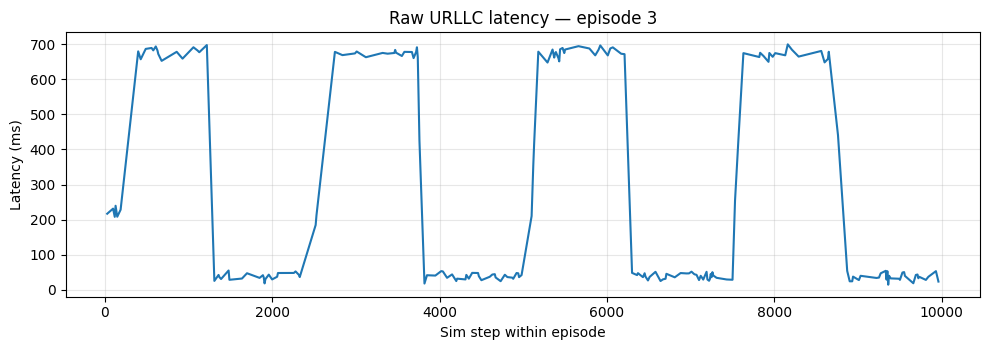

In [18]:
ep_id = 3  # pick 0..49
sub = df[df["ep"] == ep_id].sort_values("t")

plt.figure(figsize=(10,3.6))
plt.plot(sub["t"], sub[LAT_TAG]*1000.0)
plt.title(f"Raw URLLC latency — episode {ep_id}")
plt.xlabel("Sim step within episode")
plt.ylabel("Latency (ms)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


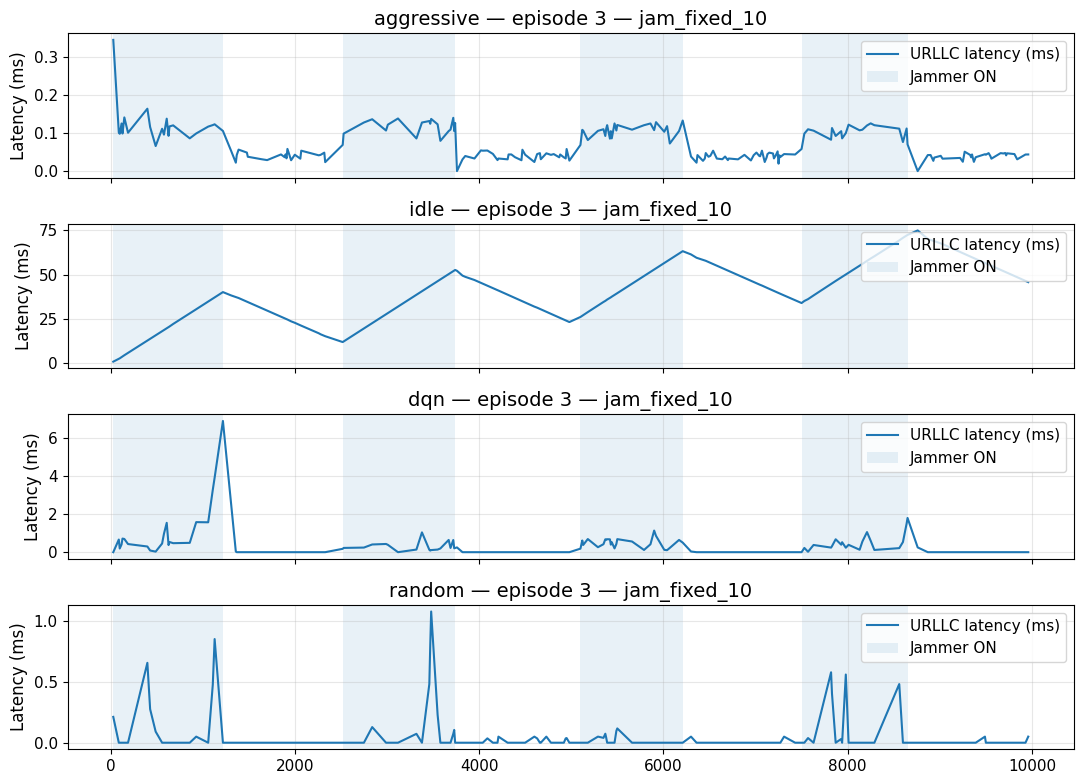

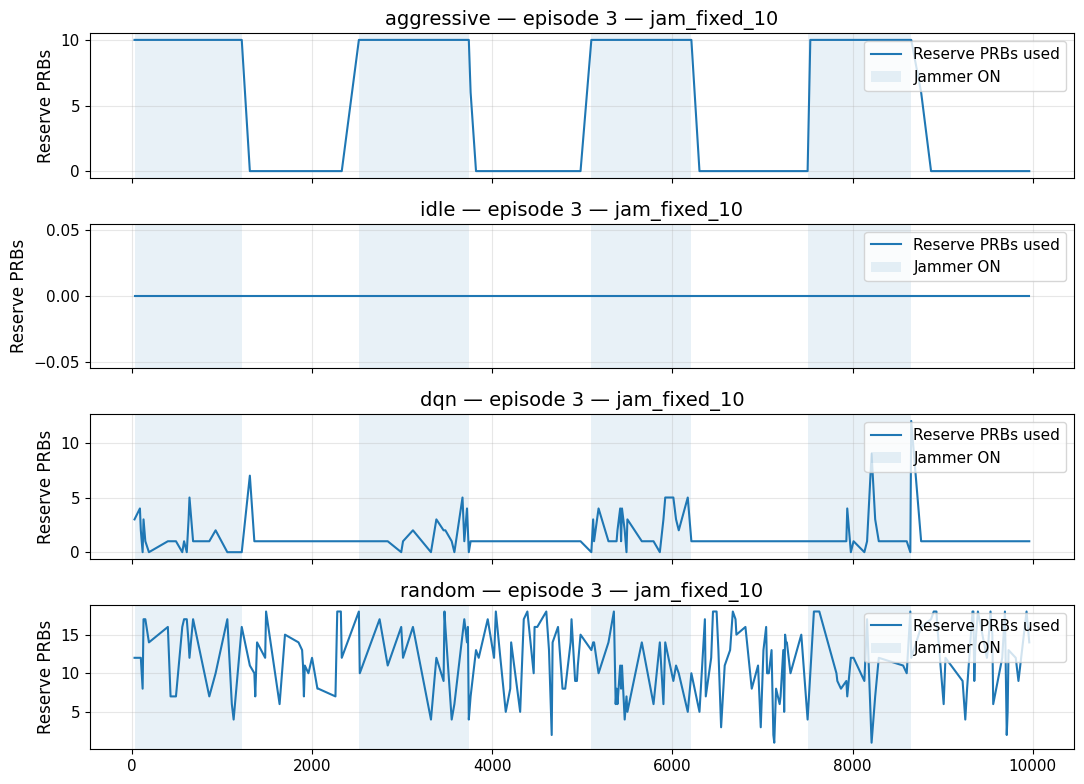

In [31]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

TB_ROOT   = Path("../../tb_logs/23_jan")
POLICIES  = ["aggressive", "idle", "dqn", "random"]
SEV       = 10
EP_ID     = 3

EFF_TAG   = "prb/effective_ratio"
LAT_TAG   = "latency/urllc"          # seconds
THR_TAG   = "throughput/embb_mbps"
RES_TAG   = "obs/reserve_used_prb"

EP_LEN_SIM = 10000
JAM_THRESH = 0.999

def find_run_dir(policy, sev):
    cand = []
    for d in TB_ROOT.rglob("*"):
        if d.is_dir() and d.name.lower().endswith(f"jam_fixed_{sev}") and policy.lower() in str(d).lower():
            cand.append(d)
    return sorted(cand, key=lambda x: len(str(x)))[0] if cand else None

def find_event_file(run_dir: Path):
    evs = sorted(run_dir.rglob("events.out.tfevents.*"))
    return evs[-1] if evs else None

def load_tag(ea, tag):
    evs = ea.Scalars(tag)
    df = pd.DataFrame({"step":[e.step for e in evs], "val":[e.value for e in evs]}).sort_values("step")
    df = df.drop_duplicates("step", keep="last").reset_index(drop=True)
    return df

def load_merged_df(event_file):
    ea = EventAccumulator(str(event_file))
    ea.Reload()
    tags = set(ea.Tags().get("scalars", []))
    need = [EFF_TAG, LAT_TAG, THR_TAG, RES_TAG]
    for t in need:
        if t not in tags:
            raise ValueError(f"Missing tag {t} in {event_file}")

    df = load_tag(ea, EFF_TAG).rename(columns={"val":EFF_TAG})
    for t in [LAT_TAG, THR_TAG, RES_TAG]:
        df = df.merge(load_tag(ea, t).rename(columns={"val":t}), on="step", how="outer")
    df = df.sort_values("step").ffill().reset_index(drop=True)

    # episode index + within-episode time (since TB step is sim-step)
    df["ep"] = (df["step"] // EP_LEN_SIM).astype(int)
    df["t"]  = (df["step"] %  EP_LEN_SIM).astype(int)

    # units
    df["lat_ms"] = df[LAT_TAG] * 1000.0
    return df

# --- plot: one subplot per policy (latency + jammer shading) ---
fig, axes = plt.subplots(len(POLICIES), 1, figsize=(11, 8), sharex=True)

for ax, pol in zip(axes, POLICIES):
    run_dir = find_run_dir(pol, SEV)
    if run_dir is None:
        ax.set_title(f"{pol}: [run not found]")
        ax.axis("off")
        continue

    event_file = find_event_file(run_dir)
    df = load_merged_df(event_file)

    sub = df[df["ep"] == EP_ID].sort_values("t")
    if sub.empty:
        ax.set_title(f"{pol}: episode {EP_ID} not found")
        continue

    # jam shading based on effective_ratio for THIS episode
    jam = sub[EFF_TAG].to_numpy() < JAM_THRESH
    x = sub["t"].to_numpy()

    ax.plot(x, sub["lat_ms"].to_numpy(), label="URLLC latency (ms)")
    ax.fill_between(x, 0, 1, where=jam, transform=ax.get_xaxis_transform(),
                    alpha=0.10, label="Jammer ON")

    ax.set_title(f"{pol} — episode {EP_ID} — jam_fixed_{SEV}")
    ax.set_ylabel("Latency (ms)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

#axes[-1].set_xlabel("Simulation step within episode (0..9999)")
plt.tight_layout()
plt.savefig(f"latency-{pol} — episode {EP_ID} — jam_fixed_{SEV}.png", dpi=300, bbox_inches="tight")
plt.show()

# --- plot: one subplot per policy (reserve_used_prb + jammer shading) ---
fig, axes = plt.subplots(len(POLICIES), 1, figsize=(11, 8), sharex=True)

for ax, pol in zip(axes, POLICIES):
    run_dir = find_run_dir(pol, SEV)
    if run_dir is None:
        ax.set_title(f"{pol}: [run not found]")
        ax.axis("off")
        continue

    event_file = find_event_file(run_dir)
    df = load_merged_df(event_file)

    sub = df[df["ep"] == EP_ID].sort_values("t")
    if sub.empty:
        ax.set_title(f"{pol}: episode {EP_ID} not found")
        continue

    jam = sub[EFF_TAG].to_numpy() < JAM_THRESH
    x   = sub["t"].to_numpy()

    # ---- PRB usage plot ----
    ax.plot(x, sub[RES_TAG].to_numpy(), label="Reserve PRBs used")
    ax.fill_between(x, 0, 1, where=jam, transform=ax.get_xaxis_transform(),
                    alpha=0.10, label="Jammer ON")

    ax.set_title(f"{pol} — episode {EP_ID} — jam_fixed_{SEV}")
    ax.set_ylabel("Reserve PRBs")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

#axes[-1].set_xlabel("Simulation step within episode (0..9999)")
plt.tight_layout()
plt.savefig(f"PRB-{pol} — episode {EP_ID} — jam_fixed_{SEV}.png", dpi=300, bbox_inches="tight")
plt.show()


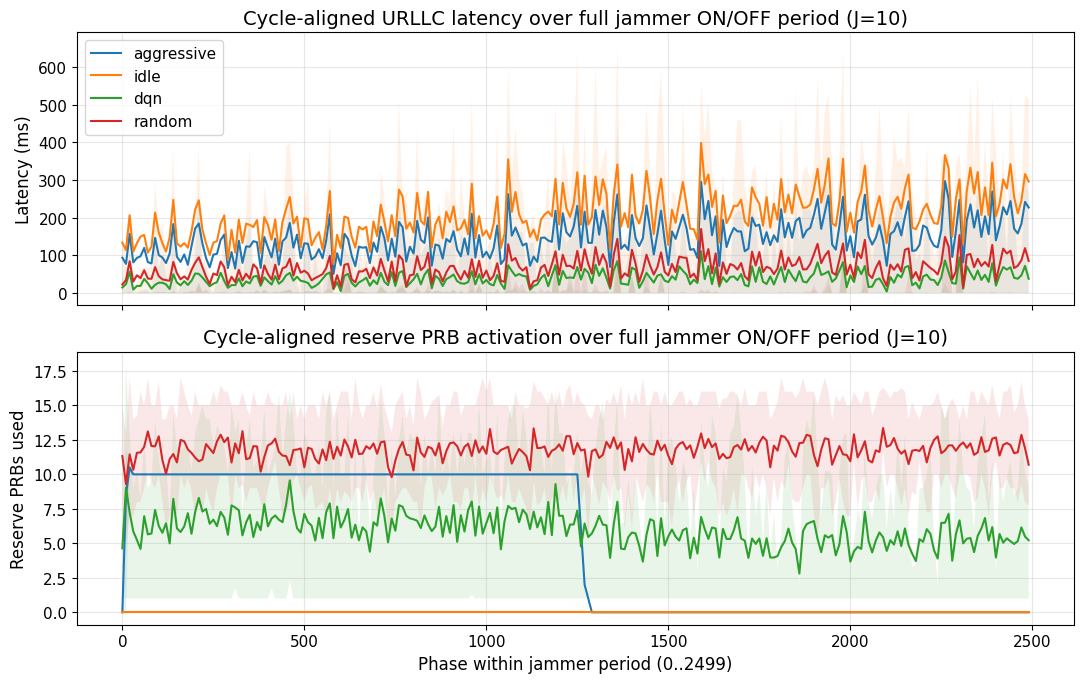

In [29]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

TB_ROOT   = Path("../../tb_logs/23_jan")
POLICIES  = ["aggressive", "idle", "dqn", "random"]
SEV       = 10

EFF_TAG   = "prb/effective_ratio"
LAT_TAG   = "latency/urllc"          # seconds
THR_TAG   = "throughput/embb_mbps"
RES_TAG   = "obs/reserve_used_prb"

EP_LEN_SIM = 10000
JAM_THRESH = 0.999

# If you know them (typical in your setup):
PERIOD = 2500        # total cycle length (ON+OFF) in sim steps
# TON  = 1250        # optional (for shading expected ON); otherwise use eff_ratio mask

def find_run_dir(policy, sev):
    cand = []
    for d in TB_ROOT.rglob("*"):
        if d.is_dir() and d.name.lower().endswith(f"jam_fixed_{sev}") and policy.lower() in str(d).lower():
            cand.append(d)
    return sorted(cand, key=lambda x: len(str(x)))[0] if cand else None

def find_event_file(run_dir: Path):
    evs = sorted(run_dir.rglob("events.out.tfevents.*"))
    return evs[-1] if evs else None

def load_tag(ea, tag):
    evs = ea.Scalars(tag)
    df = pd.DataFrame({"step":[e.step for e in evs], "val":[e.value for e in evs]}).sort_values("step")
    df = df.drop_duplicates("step", keep="last").reset_index(drop=True)
    return df

def load_merged_df(event_file):
    ea = EventAccumulator(str(event_file))
    ea.Reload()
    tags = set(ea.Tags().get("scalars", []))
    need = [EFF_TAG, LAT_TAG, THR_TAG, RES_TAG]
    for t in need:
        if t not in tags:
            raise ValueError(f"Missing tag {t} in {event_file}")

    df = load_tag(ea, EFF_TAG).rename(columns={"val":EFF_TAG})
    for t in [LAT_TAG, THR_TAG, RES_TAG]:
        df = df.merge(load_tag(ea, t).rename(columns={"val":t}), on="step", how="outer")
    df = df.sort_values("step").ffill().reset_index(drop=True)

    df["ep"] = (df["step"] // EP_LEN_SIM).astype(int)
    df["t"]  = (df["step"] %  EP_LEN_SIM).astype(int)

    df["lat_ms"] = df[LAT_TAG] * 1000.0
    df["jam_on"] = df[EFF_TAG] < JAM_THRESH

    # cycle phase within each episode
    df["phase"] = (df["t"] % PERIOD).astype(int)
    df["cycle"] = (df["t"] // PERIOD).astype(int)   # 0..3 when PERIOD=2500 and EP_LEN_SIM=10000
    return df

def cycle_aligned_mean(df, value_col):
    # average over all (ep, cycle) and across the 50 episodes
    g = df.groupby("phase")[value_col]
    mean = g.mean()
    q25  = g.quantile(0.25)
    q75  = g.quantile(0.75)
    return mean, q25, q75

# --- collect + plot ---
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

for pol in POLICIES:
    run_dir = find_run_dir(pol, SEV)
    if run_dir is None:
        continue
    ev = find_event_file(run_dir)
    df = load_merged_df(ev)

    # keep only valid cycles (optional): cycle in {0,1,2,3}
    df = df[df["cycle"].between(0, 3)]

    lat_mean, lat_q25, lat_q75 = cycle_aligned_mean(df, "lat_ms")
    res_mean, res_q25, res_q75 = cycle_aligned_mean(df, RES_TAG)

    x = lat_mean.index.to_numpy()
    axes[0].plot(x, lat_mean.to_numpy(), label=pol)
    axes[0].fill_between(x, lat_q25.to_numpy(), lat_q75.to_numpy(), alpha=0.10)

    axes[1].plot(x, res_mean.to_numpy(), label=pol)
    axes[1].fill_between(x, res_q25.to_numpy(), res_q75.to_numpy(), alpha=0.10)

# shade jammer-ON “empirical” region using majority vote across policies (optional)
# simplest: shade where phase is mostly jam_on in *one* reference policy (e.g., idle)
# If you prefer, compute a jam_on_mean = df.groupby("phase")["jam_on"].mean() and shade >0.5.

axes[0].set_title(f"Cycle-aligned URLLC latency over full jammer ON/OFF period (J={SEV})")
axes[0].set_ylabel("Latency (ms)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].set_title(f"Cycle-aligned reserve PRB activation over full jammer ON/OFF period (J={SEV})")
axes[1].set_ylabel("Reserve PRBs used")
axes[1].set_xlabel(f"Phase within jammer period (0..{PERIOD-1})")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


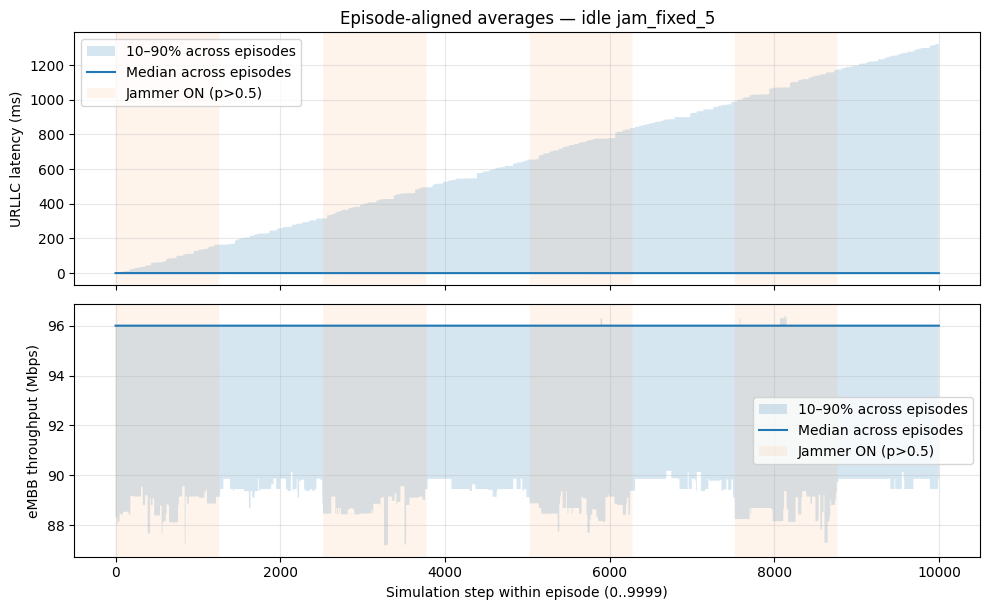

In [2]:
x = np.arange(EP_LEN_SIM)

fig, axes = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True)

# -------------------------
# 1) Latency
# -------------------------
ax = axes[0]
ax.fill_between(x, lat_lo, lat_hi, alpha=0.18, label="10–90% across episodes")
ax.plot(x, lat_med, label="Median across episodes")

# shade jammer ON (probabilistic)
ax.fill_between(
    x, 0, 1, where=(p_jam > 0.5),
    transform=ax.get_xaxis_transform(),
    alpha=0.08, label="Jammer ON (p>0.5)"
)

ax.set_title(f"Episode-aligned averages — {POLICY} jam_fixed_{SEV}")
ax.set_ylabel("URLLC latency (ms)")
ax.grid(True, alpha=0.3)
ax.legend(loc="best")

# -------------------------
# 2) Throughput
# -------------------------
ax = axes[1]
ax.fill_between(x, thr_lo, thr_hi, alpha=0.18, label="10–90% across episodes")
ax.plot(x, thr_med, label="Median across episodes")

ax.fill_between(
    x, 0, 1, where=(p_jam > 0.5),
    transform=ax.get_xaxis_transform(),
    alpha=0.08, label="Jammer ON (p>0.5)"
)

ax.set_ylabel("eMBB throughput (Mbps)")
ax.set_xlabel("Simulation step within episode (0..9999)")
ax.grid(True, alpha=0.3)
ax.legend(loc="best")

plt.tight_layout()
plt.show()


Available scalar tags (first 30):
['reward/total', 'action/index', 'action/sum', 'throughput/embb_mbps', 'throughput/urllc_mbps', 'latency/urllc', 'queues/embb_bytes', 'queues/urllc_bytes', 'prb/reserve_fraction', 'prb/effective_ratio', 'obs/embb_demand_prb', 'obs/urllc_demand_prb', 'obs/embb_throughput', 'obs/urllc_throughput', 'obs/embb_queue', 'obs/urllc_queue', 'obs/embb_base_prb', 'obs/urllc_base_prb', 'obs/embb_base_achievable_throughput', 'obs/urllc_base_achievable_throughput', 'obs/reserve_used_prb', 'obs/effective_max_prb', 'state/embb_demand_norm', 'state/urllc_demand_norm', 'state/embb_prb_norm', 'state/urllc_prb_norm', 'state/embb_base_prb_norm', 'state/urllc_base_prb_norm', 'state/embb_queue_norm', 'state/urllc_queue_norm']

--- Step scale sanity ---
num points = 10000
step min=60, max=499990
If max step ~1000 per episode => decision-step logging; ~10000 => sim-step logging.

--- Jam starts ---
Detected 199 jam starts.
First 10 start steps: [ 2530  5000  7530 10010 12500 1

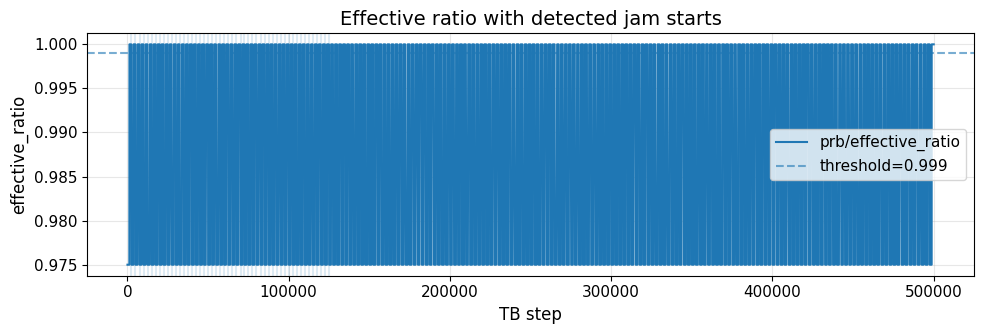

In [51]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# -----------------------------
# EDIT ONE OF THESE
# -----------------------------
# Option A: give the exact event file
EVENT_FILE = Path("../../tb_logs/23_jan/idle/gym_from_testing_config_1ms_10s_8UE_jam_fixed_5/idle__20260122_140448__res18_off0_const0_per-1_dur0/events.out.tfevents.1769108688.elahe-LEGION-T7-34IAS10.1102698.0")  # <-- EDIT

# Option B (alternative): point to a run dir and auto-pick newest event file
# RUN_DIR = Path("../../tb_logs/23_jan/aggressive/.../gym_from_testing_config_1ms_10s_8UE_jam_fixed_5")
# EVENT_FILE = sorted(RUN_DIR.rglob("events.out.tfevents.*"))[-1]

EFF_TAG = "prb/effective_ratio"
JAM_THRESH = 0.999

# -----------------------------
# Load scalar
# -----------------------------
ea = EventAccumulator(str(EVENT_FILE))
ea.Reload()

print("Available scalar tags (first 30):")
scalars = ea.Tags().get("scalars", [])
print(scalars[:30])
assert EFF_TAG in scalars, f"Tag '{EFF_TAG}' not found. Pick from the printed tags."

eff_events = ea.Scalars(EFF_TAG)
df = pd.DataFrame({
    "step": [e.step for e in eff_events],
    "eff":  [e.value for e in eff_events],
}).sort_values("step").reset_index(drop=True)

# If steps are duplicated, keep last
df = df.drop_duplicates(subset=["step"], keep="last").reset_index(drop=True)

eff = df["eff"].to_numpy(dtype=float)
steps = df["step"].to_numpy(dtype=int)

print("\n--- Step scale sanity ---")
print(f"num points = {len(df)}")
print(f"step min={steps.min()}, max={steps.max()}")
print("If max step ~1000 per episode => decision-step logging; ~10000 => sim-step logging.")

# -----------------------------
# Jam detection: starts + durations
# -----------------------------
jam = eff < JAM_THRESH
starts_idx = np.where((jam[1:] == True) & (jam[:-1] == False))[0] + 1  # indices in df
starts_step = steps[starts_idx]

print("\n--- Jam starts ---")
print(f"Detected {len(starts_step)} jam starts.")
print("First 10 start steps:", starts_step[:10])

# Period estimate (in TB step units)
if len(starts_step) >= 2:
    diffs = np.diff(starts_step)
    print("\n--- Jam period estimate ---")
    print(f"diffs (first 10): {diffs[:10]}")
    print(f"min/median/max period (TB steps): {diffs.min()} / {int(np.median(diffs))} / {diffs.max()}")
else:
    diffs = np.array([])

# ON duration estimate: lengths of contiguous jam segments
# Find all jam segments (start_idx, end_idx exclusive)
edges = np.diff(jam.astype(int))
seg_starts = np.where(edges == 1)[0] + 1
seg_ends   = np.where(edges == -1)[0] + 1

# Handle jam starting at beginning or ending at end
if jam[0]:
    seg_starts = np.r_[0, seg_starts]
if jam[-1]:
    seg_ends = np.r_[seg_ends, len(jam)]

on_lengths = (steps[seg_ends - 1] - steps[seg_starts]) + 1  # in TB steps (approx)
# Note: this assumes steps are mostly consecutive; good enough for period inference.

print("\n--- Jam ON duration estimate ---")
if len(on_lengths) > 0:
    print(f"segments detected: {len(on_lengths)}")
    print(f"min/median/max ON length (TB steps): {on_lengths.min()} / {int(np.median(on_lengths))} / {on_lengths.max()}")
else:
    print("No jam segments detected (check threshold/tag).")

# -----------------------------
# Quick plot: effective_ratio + detected starts
# -----------------------------
plt.figure(figsize=(10, 3.5))
plt.plot(steps, eff, label=EFF_TAG)
plt.axhline(JAM_THRESH, linestyle="--", alpha=0.6, label=f"threshold={JAM_THRESH}")

for s in starts_step[:50]:  # don't spam
    plt.axvline(s, alpha=0.15)

plt.title("Effective ratio with detected jam starts")
plt.xlabel("TB step")
plt.ylabel("effective_ratio")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


policy=aggressive baseline: latency=137.733 ms, thr=94.688 (throughput/embb_mbps)
policy=idle baseline: latency=137.733 ms, thr=94.688 (throughput/embb_mbps)
policy=dqn baseline: latency=18.864 ms, thr=95.045 (throughput/embb_mbps)
policy=random baseline: latency=46.230 ms, thr=95.324 (throughput/embb_mbps)


,policy,severity,baseline_lat_ms,baseline_thr,jam_lat_ms,jam_thr,delta_L_jam_ms,delta_T_drop,run_folder
0,aggressive,5,137.733307,94.687567,129.402536,94.818603,-8.330771,-0.131036,gym_from_testing_config_1ms_10s_8UE_jam_fixed_5
3,aggressive,10,137.733307,94.687567,129.595947,94.802386,-8.137361,-0.114818,gym_from_testing_config_1ms_10s_8UE_jam_fixed_10
1,aggressive,15,137.733307,94.687567,130.083542,94.786921,-7.649766,-0.099354,gym_from_testing_config_1ms_10s_8UE_jam_fixed_15
2,aggressive,20,137.733307,94.687567,130.489663,94.534907,-7.243645,0.152661,gym_from_testing_config_1ms_10s_8UE_jam_fixed_20
8,dqn,5,18.863816,95.044956,25.267647,94.729615,6.403831,0.315341,gym_from_testing_config_1ms_10s_8UE_jam_fixed_5
11,dqn,10,18.863816,95.044956,35.737710,94.001308,16.873894,1.043648,gym_from_testing_config_1ms_10s_8UE_jam_fixed_10
9,dqn,15,18.863816,95.044956,41.050512,93.355165,22.186697,1.689791,gym_from_testing_config_1ms_10s_8UE_jam_fixed_15
10,dqn,20,18.863816,95.044956,65.812067,92.354689,46.948251,2.690267,gym_from_testing_config_1ms_10s_8UE_jam_fixed_20
4,idle,5,137.733307,94.687567,153.594184,94.280645,15.860876,0.406922,gym_from_testing_config_1ms_10s_8UE_jam_fixed_5
7,idle,10,137.733307,94.687567,184.764616,93.284532,47.031308,1.403035,gym_from_testing_config_1ms_10s_8UE_jam_fixed_10


,policy,severity,delta_L_jam_ms,delta_T_drop,n
0,aggressive,5,-8.330771,-0.131036,1
1,aggressive,10,-8.137361,-0.114818,1
2,aggressive,15,-7.649766,-0.099354,1
3,aggressive,20,-7.243645,0.152661,1
4,dqn,5,6.403831,0.315341,1
5,dqn,10,16.873894,1.043648,1
6,dqn,15,22.186697,1.689791,1
7,dqn,20,46.948251,2.690267,1
8,idle,5,15.860876,0.406922,1
9,idle,10,47.031308,1.403035,1


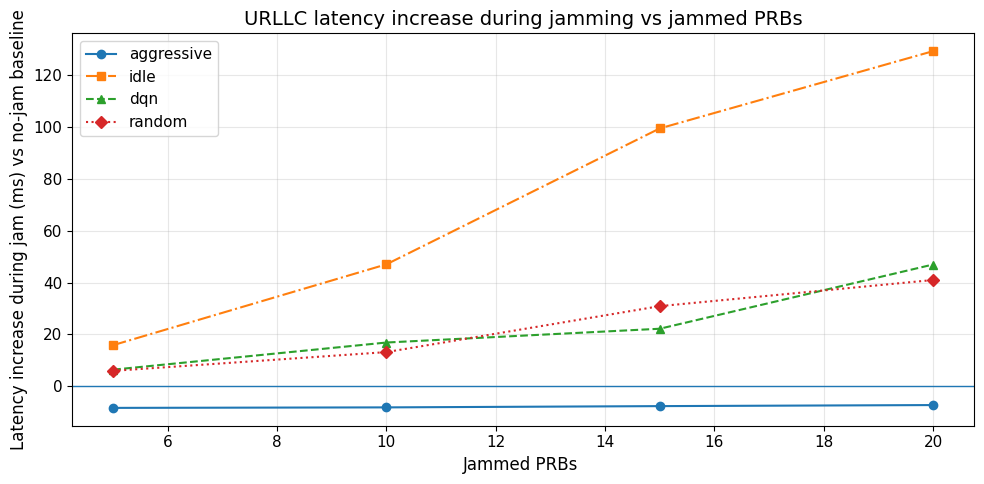

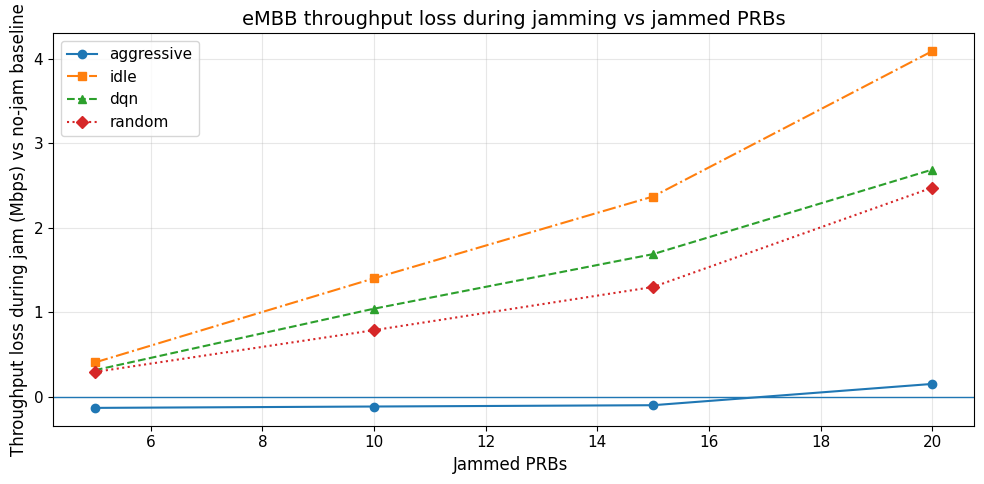

In [29]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# ----------------------------
# EDIT THESE
# ----------------------------
#TB_ROOT = Path("../../tb_logs/res_validator")
TB_ROOT = Path("../../tb_logs/23_jan")

POLICIES  = ["aggressive", "idle", "dqn", "random"]
SEVERITY  = [5, 10, 15, 20]  # your jam_fixed_5/10/15/20

BASELINE_FOLDER_REGEX = re.compile(r"jam_fixed_baseline_0$", re.IGNORECASE)
FIXED_FOLDER_REGEX    = re.compile(r"jam_fixed_(\d+)$", re.IGNORECASE)

EFF_TAG = "prb/effective_ratio"
LAT_TAG = "latency/urllc"          # assumed seconds -> ms
THR_TAG = "throughput/embb_mbps"  # change to throughput/embb_mbps if needed

# Jam detection
JAM_THRESH = 0.999   # jam ON if effective_ratio < this
WARMUP_STEPS = 0     # ignore first N steps if you want (e.g., 10)

# Stats
USE_MEDIAN = False   # True uses median instead of mean
LAT_IN_SECONDS = True  # set False if latency already in ms in TB

# ----------------------------
# Helpers
# ----------------------------
def event_dirs_under(run_root: Path):
    """Return all directories that directly contain events.out.tfevents.* under this run_root."""
    evs = list(run_root.rglob("events.out.tfevents.*"))
    return sorted({p.parent for p in evs})

def load_series(event_dir: Path, tag: str):
    ea = EventAccumulator(str(event_dir), size_guidance={"scalars": 0})
    ea.Reload()
    if tag not in ea.Tags().get("scalars", []):
        return None
    evs = ea.Scalars(tag)
    steps = np.array([e.step for e in evs], dtype=int)
    vals  = np.array([e.value for e in evs], dtype=float)
    m = steps >= WARMUP_STEPS
    return steps[m], vals[m]

def align_on_steps(series_dict):
    """series_dict: {col: (steps, vals)} -> dataframe joined on common steps."""
    dfs = []
    for col, sv in series_dict.items():
        if sv is None:
            return None
        s, v = sv
        dfs.append(pd.DataFrame({"step": s, col: v}).set_index("step"))
    df = pd.concat(dfs, axis=1, join="inner").sort_index()
    return df if not df.empty else None

def agg_stat(x):
    return float(np.nanmedian(x) if USE_MEDIAN else np.nanmean(x))

def mean_metrics_in_window(event_dir: Path, jam_only: bool):
    """
    Returns (lat_ms, thr) averaged either during jam_only or over all samples.
    Jam is detected using effective_ratio < JAM_THRESH.
    """
    s_eff = load_series(event_dir, EFF_TAG)
    s_lat = load_series(event_dir, LAT_TAG)
    s_thr = load_series(event_dir, THR_TAG)
    df = align_on_steps({"eff": s_eff, "lat": s_lat, "thr": s_thr})
    if df is None:
        return np.nan, np.nan

    if LAT_IN_SECONDS:
        df["lat_ms"] = df["lat"] * 1000.0
    else:
        df["lat_ms"] = df["lat"]

    if jam_only:
        mask = df["eff"].values < JAM_THRESH
        if mask.sum() == 0:
            return np.nan, np.nan
        lat_ms = agg_stat(df.loc[mask, "lat_ms"].values)
        thr    = agg_stat(df.loc[mask, "thr"].values)
    else:
        lat_ms = agg_stat(df["lat_ms"].values)
        thr    = agg_stat(df["thr"].values)

    return lat_ms, thr

def collect_run_stats(run_root: Path, jam_only: bool):
    """
    A run_root can contain multiple event dirs (subruns). Compute metric per event_dir then average.
    """
    edirs = event_dirs_under(run_root)
    if not edirs:
        return np.nan, np.nan

    lats, thrs = [], []
    for ed in edirs:
        lat_ms, thr = mean_metrics_in_window(ed, jam_only=jam_only)
        if not np.isnan(lat_ms):
            lats.append(lat_ms)
        if not np.isnan(thr):
            thrs.append(thr)

    if len(lats) == 0 or len(thrs) == 0:
        return np.nan, np.nan

    return float(np.mean(lats)), float(np.mean(thrs))

# ----------------------------
# Main: per policy baseline + severity metrics
# ----------------------------
rows = []

for policy in POLICIES:
    pol_dir = TB_ROOT / policy
    if not pol_dir.exists():
        continue

    # find baseline folder inside policy dir
    baseline_folders = [p for p in pol_dir.iterdir() if p.is_dir() and BASELINE_FOLDER_REGEX.search(p.name)]
    if len(baseline_folders) == 0:
        print(f"[WARN] No baseline folder found for policy={policy}")
        continue
    baseline_root = baseline_folders[0]

    # baseline metrics (no-jam): average over all samples
    base_lat_ms, base_thr = collect_run_stats(baseline_root, jam_only=False)
    if np.isnan(base_lat_ms) or np.isnan(base_thr):
        print(f"[WARN] Baseline metrics missing for policy={policy} in {baseline_root.name}")
        continue

    print(f"policy={policy} baseline: latency={base_lat_ms:.3f} ms, thr={base_thr:.3f} ({THR_TAG})")

    # severity folders: jam_fixed_5/10/15/20
    for p in pol_dir.iterdir():
        if not p.is_dir():
            continue
        m = FIXED_FOLDER_REGEX.search(p.name)
        if not m:
            continue
        sev = int(m.group(1))
        if sev not in SEVERITY:
            continue

        jam_lat_ms, jam_thr = collect_run_stats(p, jam_only=True)
        if np.isnan(jam_lat_ms) or np.isnan(jam_thr):
            continue

        rows.append({
            "policy": policy,
            "severity": sev,
            "baseline_lat_ms": base_lat_ms,
            "baseline_thr": base_thr,
            "jam_lat_ms": jam_lat_ms,
            "jam_thr": jam_thr,
            "delta_L_jam_ms": jam_lat_ms - base_lat_ms,      # higher = worse
            "delta_T_drop": base_thr - jam_thr,              # higher = worse
            "run_folder": p.name,
        })

df = pd.DataFrame(rows)
display(df.sort_values(["policy","severity"]))

# Aggregate in case multiple runs exist per point
agg = (df.groupby(["policy","severity"], as_index=False)
         .agg(delta_L_jam_ms=("delta_L_jam_ms","mean"),
              delta_T_drop=("delta_T_drop","mean"),
              n=("run_folder","count")))
display(agg.sort_values(["policy","severity"]))


# ---- Plot styling per policy (marker + line style) ----
STYLE = {
    "aggressive": dict(marker="o", linestyle="-"),    # circle + solid
    "dqn":        dict(marker="^", linestyle="--"),   # triangle + dashed
    "idle":       dict(marker="s", linestyle="-."),   # square + dash-dot
    "random":     dict(marker="D", linestyle=":"),    # diamond + dotted
}



# ----------------------------
# Plots: mean ΔL_jam and mean ΔT_drop vs severity
# ----------------------------
plt.figure(figsize=(10,5))
for policy in POLICIES:
    sub = agg[agg["policy"] == policy].sort_values("severity")
    if sub.empty:
        continue
    #plt.plot(sub["severity"], sub["delta_L_jam_ms"], marker="o", label=policy)
    st = STYLE.get(policy, dict(marker="o", linestyle="-"))
    plt.plot(sub["severity"], sub["delta_L_jam_ms"],
         label=policy, marker=st["marker"], linestyle=st["linestyle"])

plt.axhline(0.0, linewidth=1)
# plt.title("Mean ΔL_jam vs severity (Δ = jam_window − baseline, per-policy baseline)")
# plt.xlabel("Severity (X in jam_fixed_X)")
# plt.ylabel("Δ URLLC latency during jam (ms)")
plt.title("URLLC latency increase during jamming vs jammed PRBs")
plt.xlabel("Jammed PRBs ")
plt.ylabel("Latency increase during jam (ms) vs no-jam baseline")# (same policy)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("Latency increase during jam (ms) vs no-jam baseline"+".png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10,5))
for policy in POLICIES:
    sub = agg[agg["policy"] == policy].sort_values("severity")
    if sub.empty:
        continue
    #plt.plot(sub["severity"], sub["delta_T_drop"], marker="o", label=policy)
    st = STYLE.get(policy, dict(marker="o", linestyle="-"))
    plt.plot(sub["severity"], sub["delta_T_drop"],
         label=policy, marker=st["marker"], linestyle=st["linestyle"])

plt.axhline(0.0, linewidth=1)
# plt.title("Mean ΔT_drop vs severity (Δ = baseline − jam_window, per-policy baseline)")
# plt.xlabel("Severity (X in jam_fixed_X)")
# plt.ylabel(f"Throughput drop during jam ({THR_TAG} units)")
plt.title("eMBB throughput loss during jamming vs jammed PRBs")
plt.xlabel("Jammed PRBs ")
plt.ylabel("Throughput loss during jam (Mbps) vs no-jam baseline")# (same policy)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("Throughput loss during jam (Mbps) vs no-jam baseline"+".png", dpi=300, bbox_inches="tight")
plt.show()


Total jam cycles: 3200


,policy,power,run_id,episode_idx,jam_idx_global,jam_start_step,jam_end_step,on_len_samples,auc_on,mitigated_on,t_mitigate_on_sim_steps,mitigate_value,mean_reserve_used_on,max_reserve_used_on,sum_reserve_used_on,impacted_on,n_jams_in_episode
0,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,0,10.0,1240.0,124,0.000499,True,330.0,0.000008,4.951613,5.0,614.0,True,4
1,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,1,2500.0,3740.0,125,0.000893,False,inf,NaN,4.952000,5.0,619.0,True,4
2,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,2,5000.0,6240.0,125,0.000672,False,inf,NaN,4.952000,5.0,619.0,True,4
3,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,3,7500.0,8740.0,125,0.000485,False,inf,NaN,4.952000,5.0,619.0,True,4
4,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,4,10010.0,11240.0,124,0.000008,True,20.0,0.000000,4.951613,5.0,614.0,True,4
5,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,5,12500.0,13740.0,125,0.000005,True,20.0,0.000000,4.952000,5.0,619.0,True,4
6,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,6,15000.0,16240.0,125,0.000005,True,20.0,0.000000,4.952000,5.0,619.0,True,4
7,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,7,17500.0,18740.0,125,0.000005,True,20.0,0.000000,4.952000,5.0,619.0,True,4
8,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,2,8,20010.0,21240.0,124,0.000000,True,0.0,0.000000,4.951613,5.0,614.0,False,4
9,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,2,9,22500.0,23740.0,125,0.000000,True,0.0,0.000000,4.952000,5.0,619.0,False,4



Episodes per (policy,power) (expect 50):


policy      power
aggressive  5        50
            10       50
            15       50
            20       50
dqn         5        50
            10       50
            15       50
            20       50
idle        5        50
            10       50
            15       50
            20       50
random      5        50
            10       50
            15       50
            20       50
Name: episode_idx, dtype: int64


Cycles per (policy,power) (expect 200):


policy      power
aggressive  5        200
            10       200
            15       200
            20       200
dqn         5        200
            10       200
            15       200
            20       200
idle        5        200
            10       200
            15       200
            20       200
random      5        200
            10       200
            15       200
            20       200
Name: jam_idx_global, dtype: int64


Jam runs per episode distribution (expect all 4):


n_jams_in_episode
4    800
Name: count, dtype: int64

/tmp/ipykernel_1173802/46274402.py:314: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: np.nanmedian(g.loc[(g["impacted_on"]) & (g["mitigated_on"]), "t_mit_clean"])
/tmp/ipykernel_1173802/46274402.py:344: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tmp.groupby(["policy","power"]).apply(rate_on_impacted).values


,policy,power,n_cycles,n_episodes,median_auc_on,mean_auc_on,mitigation_rate,mitigation_rate_impacted,impact_rate,median_t_mitigate_on,median_reserve_on,mean_reserve_on,median_max_reserve_on,mean_sum_reserve_on,median_t_mitigate_impacted_mitigated
0,aggressive,5,200,50,0.008078,1.095927,0.370,0.125000,0.720,0.0,4.952000,4.951903,5.0,617.750,20.0
1,aggressive,10,200,50,0.008462,1.120070,0.360,0.238095,0.840,0.0,9.936000,9.935871,12.0,1239.500,20.0
2,aggressive,15,200,50,0.014394,1.180886,0.325,0.262295,0.915,20.0,14.848000,14.847694,15.0,1852.250,20.0
3,aggressive,20,200,50,0.022451,1.231551,0.320,0.276596,0.940,30.0,17.792000,17.791581,18.0,2219.500,30.0
4,dqn,5,200,50,0.004510,1.169473,0.410,0.174825,0.715,0.0,2.205097,5.803420,18.0,724.030,60.0
5,dqn,10,200,50,0.010269,2.364001,0.440,0.317073,0.820,10.0,5.440000,6.684958,18.0,834.015,90.0
6,dqn,15,200,50,0.059993,3.013973,0.415,0.323699,0.865,50.0,9.340000,8.761397,18.0,1093.080,170.0
7,dqn,20,200,50,0.088054,6.089649,0.375,0.324324,0.925,210.0,11.606484,10.511213,18.0,1311.315,340.0
8,idle,5,200,50,0.022335,4.113811,0.270,0.026667,0.750,0.0,0.000000,0.000000,0.0,0.000,0.0
9,idle,10,200,50,1.265975,8.002309,0.135,0.017045,0.880,0.0,0.000000,0.000000,0.0,0.000,0.0


       reserve_used_prb
count      49950.000000
mean          11.702783
std            4.448525
min            0.000000
25%            8.000000
50%           12.000000
75%           15.000000
max           18.000000
reserve tag rows: 49950
reserve min/max: 0.0 18.0


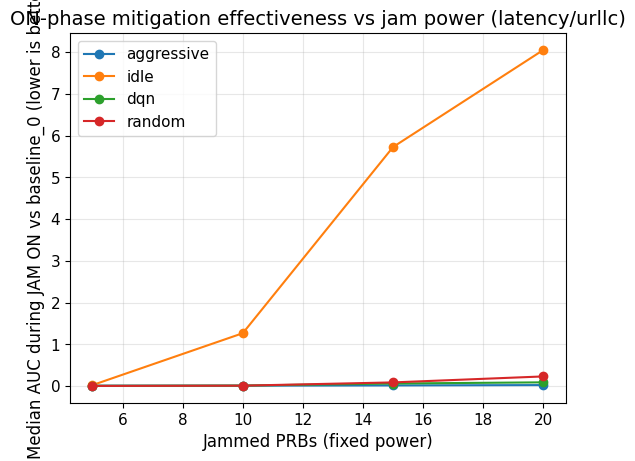

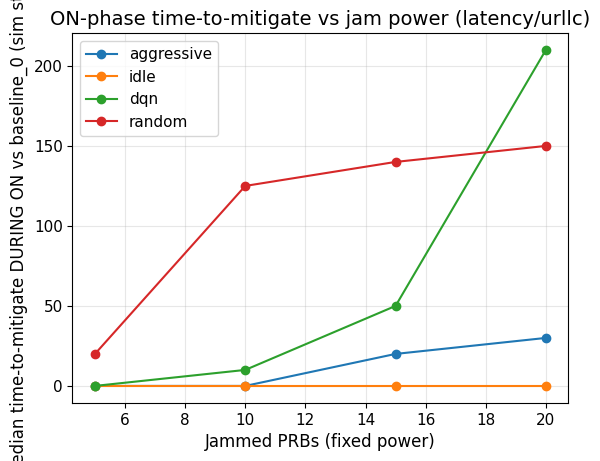

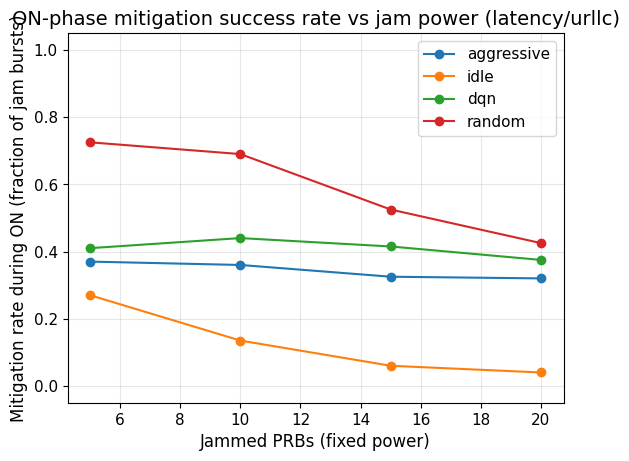

In [64]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

# =========================
# USER CONFIG
# =========================
ROOT = Path("../../tb_logs/23_jan")   # .../backend/tb_logs/res_validator
POLICIES = ["aggressive", "idle", "dqn", "random"]
POWERS = [5, 10, 15, 20]

RESERVE_TAG = "obs/reserve_used_prb"
METRIC_TAG = "latency/urllc"                # or "throughput/embb_mbps"
JAM_TAG = "prb/effective_ratio"

EP_LEN_SIM = 10000                          # sim steps per episode
JAM_THRESHOLD = 0.999

#ABS_TOLERANCE = 0.001


# Baseline folder suffix (per policy)
BASELINE_SUFFIX = "_jam_fixed_baseline_0"

# Mitigation definition (baseline-relative, during ON)
K_CONSEC = 10         # 5 samples ≈ 50 sim steps (since you log every 10)
EPS = 0.01           # 5% tolerance vs baseline

LOWER_IS_BETTER = True   # True for latency, False for throughput

# =========================
# TB reader
# =========================
def read_tb_scalar(event_file: Path, tags):
    tags = set(tags)
    out = {t: [] for t in tags}

    for rec in tf_record.tf_record_iterator(str(event_file)):
        e = Event.FromString(rec)
        if not e.summary.value:
            continue
        step = int(e.step)
        for v in e.summary.value:
            if v.tag in tags:
                out[v.tag].append((step, float(v.simple_value)))

    dfs = {}
    for t, rows in out.items():
        if not rows:
            dfs[t] = pd.DataFrame(columns=["step", "value"])
        else:
            df = pd.DataFrame(rows, columns=["step", "value"]).dropna()
            df = df.sort_values("step").drop_duplicates("step", keep="last").reset_index(drop=True)
            dfs[t] = df
    return dfs

# =========================
# Helpers
# =========================
def segment_bool_runs(is_true: np.ndarray):
    """Return list of (start_idx, end_idx_exclusive) for True-runs."""
    if len(is_true) == 0:
        return []
    x = is_true.astype(np.int8)
    d = np.diff(x, prepend=0, append=0)
    starts = np.where(d == 1)[0]
    ends   = np.where(d == -1)[0]
    return list(zip(starts, ends))

def first_k_consecutive_true(mask: np.ndarray, k: int):
    """First index i such that mask[i:i+k] are all True. None if not found."""
    if k <= 1:
        idx = np.where(mask)[0]
        return int(idx[0]) if len(idx) else None
    if len(mask) < k:
        return None
    s = np.convolve(mask.astype(np.int32), np.ones(k, dtype=np.int32), mode="valid")
    hits = np.where(s == k)[0]
    return int(hits[0]) if len(hits) else None

def find_event_file_under_test_folder(test_folder: Path):
    """
    test_folder: .../policy/gym_from_testing_config_... (test)
    Inside it, one run subfolder exists, and then events.out.tfevents.*
    """
    evs = sorted(test_folder.rglob("events.out.tfevents.*"))
    if not evs:
        return None
    evs = sorted(evs, key=lambda p: (p.stat().st_mtime, p.stat().st_size))
    return evs[-1]

def pick_test_folder(policy_dir: Path, suffix: str):
    matches = sorted([p for p in policy_dir.iterdir() if p.is_dir() and p.name.endswith(suffix)])
    return matches[0] if matches else None

# =========================
# Build aligned tables
# =========================
# def build_jam_table(dfs):
#     """Return df with columns: step, metric, eff"""
#     df_metric = dfs[METRIC_TAG].rename(columns={"value":"metric"})
#     df_jam    = dfs[JAM_TAG].rename(columns={"value":"eff"})
#     df = df_metric.merge(df_jam, on="step", how="inner").sort_values("step").reset_index(drop=True)
#     return df

def build_jam_table(dfs):
    """Return df with: step, metric, eff, reserve_used_prb."""
    df_metric = dfs[METRIC_TAG].rename(columns={"value": "metric"})
    df_jam    = dfs[JAM_TAG].rename(columns={"value": "eff"})
    df_res    = dfs[RESERVE_TAG].rename(columns={"value": "reserve_used_prb"})

    df = df_metric.merge(df_jam, on="step", how="inner")
    df = df.merge(df_res, on="step", how="left")  # left in case some steps missing
    return df.sort_values("step").reset_index(drop=True)

def build_baseline_metric_table(dfs_base):
    """Return df with columns: step, base_metric"""
    dfb = dfs_base[METRIC_TAG].rename(columns={"value":"base_metric"})
    dfb = dfb.sort_values("step").drop_duplicates("step", keep="last").reset_index(drop=True)
    return dfb

# =========================
# Core computation: ON-phase vs baseline_0
# =========================
def compute_on_metrics_vs_baseline(df_jam, df_base_metric, policy, power, run_id):
    """
    df_jam: step, metric, eff  (jam run)
    df_base_metric: step, base_metric (baseline run, same policy)
    We align by step (your logs match perfectly).
    """
    # Merge baseline metric onto jam timeline
    df = df_jam.merge(df_base_metric, on="step", how="inner").sort_values("step").reset_index(drop=True)
    if df.empty:
        return pd.DataFrame()

    step0 = int(df["step"].iloc[0])
    df["episode_idx"] = ((df["step"] - step0) // EP_LEN_SIM).astype(int)

    steps = df["step"].to_numpy()
    m_jam = df["metric"].to_numpy()
    m_base = df["base_metric"].to_numpy()
    eff   = df["eff"].to_numpy()
    reserve = df["reserve_used_prb"].to_numpy() if "reserve_used_prb" in df.columns else None


    is_jam = eff < JAM_THRESHOLD
    jam_runs = segment_bool_runs(is_jam)

    rows = []

    # Count jam bursts per episode (for sanity)
    ep_idx_arr = df["episode_idx"].to_numpy()
    jam_count_per_ep = {}
    for (s_idx, e_idx) in jam_runs:
        ep = int(ep_idx_arr[s_idx])
        jam_count_per_ep[ep] = jam_count_per_ep.get(ep, 0) + 1

    for j, (s_idx, e_idx) in enumerate(jam_runs):
        if e_idx <= s_idx:
            continue

        on_steps = steps[s_idx:e_idx]
        on_jam = m_jam[s_idx:e_idx]
        on_base = m_base[s_idx:e_idx]
        
        mean_reserve_on = np.nan
        max_reserve_on = np.nan
        sum_reserve_on = np.nan

        if reserve is not None:
            r_on = reserve[s_idx:e_idx]
            mean_reserve_on = float(np.nanmean(r_on))
            max_reserve_on  = float(np.nanmax(r_on))
            sum_reserve_on  = float(np.nansum(r_on))


        if len(on_jam) == 0:
            continue

        # -------- AUC_on (baseline-relative, additive) --------
        if LOWER_IS_BETTER:
            harm = np.maximum(0.0, on_jam - on_base)
            auc_on = float(np.nansum(harm))
            good_on = on_jam <= (1.0 + EPS) * (on_base + 1e-12)
            impacted = np.any(on_jam > (1.0 + EPS) * (on_base + 1e-12))
        else:
            harm = np.maximum(0.0, on_base - on_jam)
            auc_on = float(np.nansum(harm))
            good_on = on_jam >= (1.0 - EPS) * (on_base + 1e-12)
            impacted = np.any(on_jam < (1.0 - EPS) * (on_base + 1e-12))

        # -------- time-to-mitigate during ON (baseline-relative) --------
        mit_offset = first_k_consecutive_true(good_on, K_CONSEC)
        if mit_offset is None:
            mitigated_on = False
            t_mit_on = np.inf
            mit_value = np.nan
        else:
            mitigated_on = True
            t_mit_on = float(on_steps[mit_offset] - on_steps[0])
            mit_value = float(on_jam[mit_offset])

        ep = int(ep_idx_arr[s_idx])
        rows.append({
            "policy": policy,
            "power": power,
            "run_id": run_id,
            "episode_idx": ep,
            "jam_idx_global": int(j),

            "jam_start_step": float(steps[s_idx]),
            "jam_end_step": float(steps[e_idx - 1]),
            "on_len_samples": int(e_idx - s_idx),

            "auc_on": auc_on,
            "mitigated_on": mitigated_on,
            "t_mitigate_on_sim_steps": t_mit_on,
            "mitigate_value": mit_value,
            "mean_reserve_used_on": mean_reserve_on,
            "max_reserve_used_on": max_reserve_on,
            "sum_reserve_used_on": sum_reserve_on,
            "impacted_on": bool(impacted),

        })

    out = pd.DataFrame(rows)

    # Attach jams-per-episode sanity info
    if not out.empty:
        out["n_jams_in_episode"] = out["episode_idx"].map(jam_count_per_ep).fillna(0).astype(int)

    return out

# =========================
# MAIN: load baseline per policy, then jam runs per power
# =========================
all_cycles = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    if not policy_dir.exists():
        print(f"[WARN] policy folder missing: {policy_dir}")
        continue

    # ----- load baseline_0 once per policy -----
    base_folder = pick_test_folder(policy_dir, BASELINE_SUFFIX)
    if base_folder is None:
        print(f"[WARN] missing baseline folder for policy={policy} suffix={BASELINE_SUFFIX}")
        continue

    base_ev = find_event_file_under_test_folder(base_folder)
    if base_ev is None:
        print(f"[WARN] no event file in baseline folder: {base_folder}")
        continue

    dfs_base = read_tb_scalar(base_ev, tags=[METRIC_TAG])
    df_base_metric = build_baseline_metric_table(dfs_base)

    # ----- iterate jam powers -----
    for pwr in POWERS:
        jam_folder = pick_test_folder(policy_dir, f"_jam_fixed_{pwr}")
        if jam_folder is None:
            print(f"[WARN] missing jam folder for {policy} power={pwr}")
            continue

        jam_ev = find_event_file_under_test_folder(jam_folder)
        if jam_ev is None:
            print(f"[WARN] no event file in jam folder: {jam_folder}")
            continue

        #dfs_jam = read_tb_scalar(jam_ev, tags=[METRIC_TAG, JAM_TAG])
        dfs_jam = read_tb_scalar(jam_ev, tags=[METRIC_TAG, JAM_TAG, RESERVE_TAG])

        df_jam = build_jam_table(dfs_jam)

        df_cycles = compute_on_metrics_vs_baseline(df_jam, df_base_metric, policy, pwr, str(jam_folder))
        if not df_cycles.empty:
            all_cycles.append(df_cycles)

df_cycles_all = pd.concat(all_cycles, ignore_index=True) if all_cycles else pd.DataFrame()
print("Total jam cycles:", len(df_cycles_all))
display(df_cycles_all.head(10))

# =========================
# SANITY CHECKS
# =========================
if not df_cycles_all.empty:
    print("\nEpisodes per (policy,power) (expect 50):")
    display(df_cycles_all.groupby(["policy","power"])["episode_idx"].nunique())

    print("\nCycles per (policy,power) (expect 200):")
    display(df_cycles_all.groupby(["policy","power"])["jam_idx_global"].count())

    print("\nJam runs per episode distribution (expect all 4):")
    display(
        df_cycles_all.groupby(["policy","power","episode_idx"])["n_jams_in_episode"]
        .first().value_counts().sort_index()
    )

# =========================
# AGGREGATE + PLOTS
# =========================
if not df_cycles_all.empty:
    tmp = df_cycles_all.copy()
    tmp["t_mit_clean"] = tmp["t_mitigate_on_sim_steps"].replace([np.inf, -np.inf], np.nan)


    tmit_impacted_mitigated = (
    tmp.groupby(["policy","power"])
       .apply(lambda g: np.nanmedian(g.loc[(g["impacted_on"]) & (g["mitigated_on"]), "t_mit_clean"])
              if ((g["impacted_on"]) & (g["mitigated_on"])).any() else np.nan)
       .reset_index(name="median_t_mitigate_impacted_mitigated")
        )
    df_agg = (
        tmp.groupby(["policy","power"])
           .agg(
               n_cycles=("jam_idx_global", "count"),
               n_episodes=("episode_idx", "nunique"),
               median_auc_on=("auc_on", "median"),
               mean_auc_on=("auc_on", "mean"),
               mitigation_rate=("mitigated_on", "mean"),
               mitigation_rate_impacted=("mitigated_on", lambda s: np.nan), 
               impact_rate=("impacted_on", "mean"),

               median_t_mitigate_on=("t_mit_clean", "median"),
               median_reserve_on=("mean_reserve_used_on", "median"),
               mean_reserve_on=("mean_reserve_used_on", "mean"),
               median_max_reserve_on=("max_reserve_used_on", "median"),
               mean_sum_reserve_on=("sum_reserve_used_on", "mean"),
           )
           .reset_index()
           .sort_values(["policy","power"])
    )
    def rate_on_impacted(g):
        imp = g["impacted_on"].to_numpy()
        mit = g["mitigated_on"].to_numpy()
        return np.nan if imp.sum()==0 else mit[imp].mean()

    df_agg["mitigation_rate_impacted"] = (
        tmp.groupby(["policy","power"]).apply(rate_on_impacted).values
    )
    df_agg = df_agg.merge(tmit_impacted_mitigated, on=["policy","power"], how="left")


    display(df_agg)
    print(df_jam[["reserve_used_prb"]].describe())
    print("reserve tag rows:", len(dfs_jam[RESERVE_TAG]))
    print("reserve min/max:", dfs_jam[RESERVE_TAG]["value"].min(), dfs_jam[RESERVE_TAG]["value"].max())


    # 1) AUC_on vs power
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_auc_on"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median AUC during JAM ON vs baseline_0 (lower is better)")
    plt.title(f"ON-phase mitigation effectiveness vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # 2) Time-to-mitigate during ON
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_t_mitigate_on"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median time-to-mitigate DURING ON vs baseline_0 (sim steps)")
    plt.title(f"ON-phase time-to-mitigate vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # 3) Mitigation rate during ON
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["mitigation_rate"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Mitigation rate during ON (fraction of jam bursts)")
    plt.title(f"ON-phase mitigation success rate vs jam power ({METRIC_TAG})")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


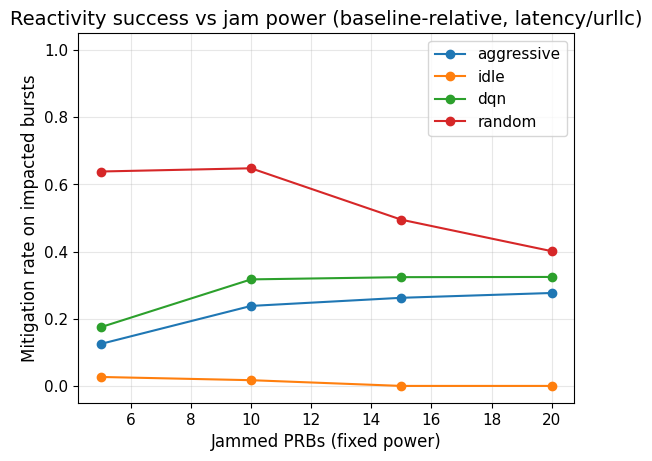

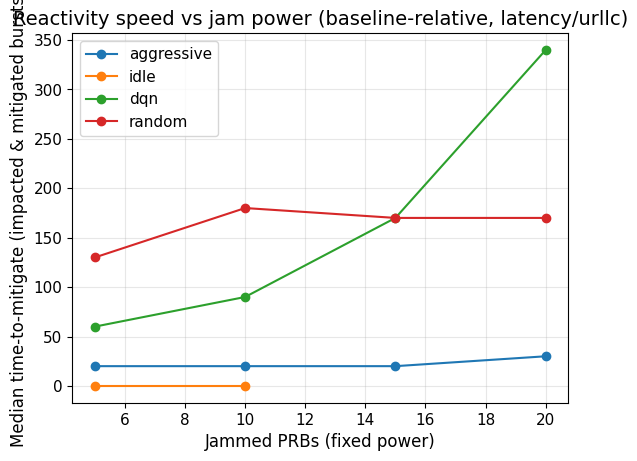

In [65]:
# 4) Mitigation rate (impacted only)
plt.figure()
for pol in POLICIES:
    sub = df_agg[df_agg["policy"] == pol].sort_values("power")
    if len(sub) == 0:
        continue
    plt.plot(sub["power"], sub["mitigation_rate_impacted"], marker="o", label=pol)
plt.xlabel("Jammed PRBs (fixed power)")
plt.ylabel("Mitigation rate on impacted bursts")
plt.title(f"Reactivity success vs jam power (baseline-relative, {METRIC_TAG})")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 5) Time-to-mitigate (impacted & mitigated only)
plt.figure()
for pol in POLICIES:
    sub = df_agg[df_agg["policy"] == pol].sort_values("power")
    if len(sub) == 0:
        continue
    plt.plot(sub["power"], sub["median_t_mitigate_impacted_mitigated"], marker="o", label=pol)
plt.xlabel("Jammed PRBs (fixed power)")
plt.ylabel("Median time-to-mitigate (impacted & mitigated bursts)")
plt.title(f"Reactivity speed vs jam power (baseline-relative, {METRIC_TAG})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Total jam cycles: 3200


,policy,power,run_id,episode_idx,jam_idx_global,jam_start_step,jam_end_step,on_len_samples,auc_on,mitigated_on,t_mitigate_on_sim_steps,mitigate_value,mean_reserve_used_on,max_reserve_used_on,sum_reserve_used_on,impacted_on,n_jams_in_episode
0,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,0,10.0,1240.0,124,0.143997,True,0.0,95.856003,4.951613,5.0,614.0,False,4
1,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,1,2500.0,3740.0,125,0.287994,True,0.0,95.856003,4.952000,5.0,619.0,False,4
2,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,2,5000.0,6240.0,125,0.287994,True,0.0,95.856003,4.952000,5.0,619.0,False,4
3,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,3,7500.0,8740.0,125,0.287994,True,0.0,95.856003,4.952000,5.0,619.0,False,4
4,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,4,10010.0,11240.0,124,0.000000,True,0.0,96.000000,4.951613,5.0,614.0,False,4
5,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,5,12500.0,13740.0,125,0.000000,True,0.0,96.000000,4.952000,5.0,619.0,False,4
6,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,6,15000.0,16240.0,125,0.000000,True,0.0,96.000000,4.952000,5.0,619.0,False,4
7,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,7,17500.0,18740.0,125,0.000000,True,0.0,96.000000,4.952000,5.0,619.0,False,4
8,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,2,8,20010.0,21240.0,124,0.000000,True,0.0,96.000000,4.951613,5.0,614.0,False,4
9,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,2,9,22500.0,23740.0,125,0.000000,True,0.0,96.000000,4.952000,5.0,619.0,False,4



Episodes per (policy,power) (expect 50):


policy      power
aggressive  5        50
            10       50
            15       50
            20       50
dqn         5        50
            10       50
            15       50
            20       50
idle        5        50
            10       50
            15       50
            20       50
random      5        50
            10       50
            15       50
            20       50
Name: episode_idx, dtype: int64


Cycles per (policy,power) (expect 200):


policy      power
aggressive  5        200
            10       200
            15       200
            20       200
dqn         5        200
            10       200
            15       200
            20       200
idle        5        200
            10       200
            15       200
            20       200
random      5        200
            10       200
            15       200
            20       200
Name: jam_idx_global, dtype: int64


Jam runs per episode distribution (expect all 4):


n_jams_in_episode
4    800
Name: count, dtype: int64

/tmp/ipykernel_1173802/1047964738.py:314: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: np.nanmedian(g.loc[(g["impacted_on"]) & (g["mitigated_on"]), "t_mit_clean"])
/tmp/ipykernel_1173802/1047964738.py:344: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tmp.groupby(["policy","power"]).apply(rate_on_impacted).values


,policy,power,n_cycles,n_episodes,median_auc_on,mean_auc_on,mitigation_rate,mitigation_rate_impacted,impact_rate,median_t_mitigate_on,median_reserve_on,mean_reserve_on,median_max_reserve_on,mean_sum_reserve_on,median_t_mitigate_impacted_mitigated
0,aggressive,5,200,50,0.000000,6.350762,0.995,0.972973,0.185,0.0,4.952000,4.951903,5.0,617.750,20.0
1,aggressive,10,200,50,0.000000,8.178481,0.995,0.988372,0.430,0.0,9.936000,9.935871,12.0,1239.500,20.0
2,aggressive,15,200,50,0.760002,10.585560,0.995,0.989583,0.480,0.0,14.848000,14.847694,15.0,1852.250,20.0
3,aggressive,20,200,50,7.552002,26.891238,0.910,0.857143,0.630,20.0,17.792000,17.791581,18.0,2219.500,20.0
4,dqn,5,200,50,0.000000,57.016580,0.820,0.181818,0.220,0.0,2.205097,5.803420,18.0,724.030,145.0
5,dqn,10,200,50,0.000000,144.417032,0.655,0.250000,0.460,0.0,5.440000,6.684958,18.0,834.015,130.0
6,dqn,15,200,50,15.263702,226.266719,0.605,0.168421,0.475,0.0,9.340000,8.761397,18.0,1093.080,415.0
7,dqn,20,200,50,237.647942,351.838607,0.440,0.096774,0.620,0.0,11.606484,10.511213,18.0,1311.315,240.0
8,idle,5,200,50,0.000000,54.360927,0.825,0.204545,0.220,0.0,0.000000,0.000000,0.0,0.000,460.0
9,idle,10,200,50,3.023941,177.604236,0.575,0.114583,0.480,0.0,0.000000,0.000000,0.0,0.000,170.0


       reserve_used_prb
count      49950.000000
mean          11.702783
std            4.448525
min            0.000000
25%            8.000000
50%           12.000000
75%           15.000000
max           18.000000
reserve tag rows: 49950
reserve min/max: 0.0 18.0


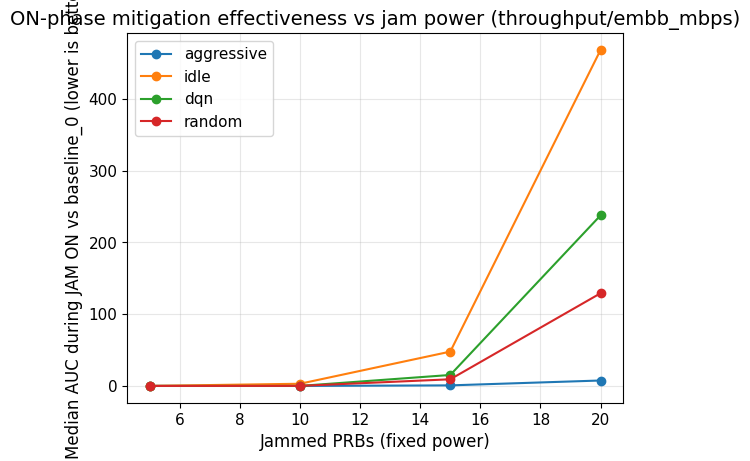

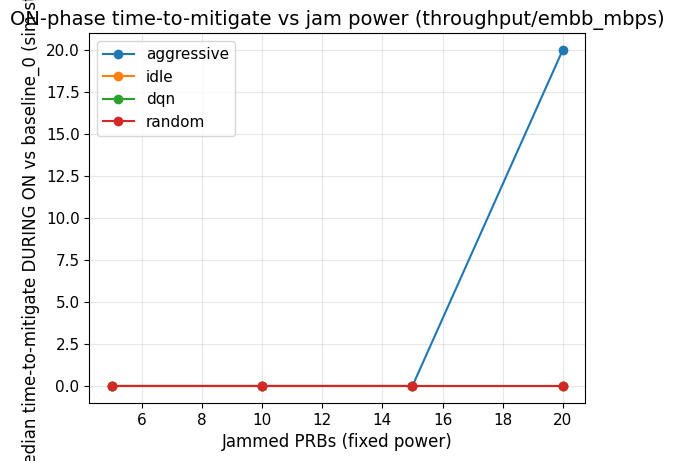

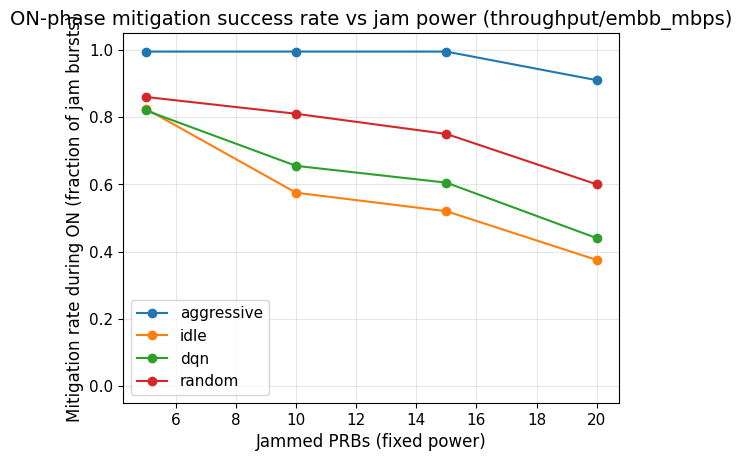

In [69]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

# =========================
# USER CONFIG
# =========================
ROOT = Path("../../tb_logs/23_jan")   # .../backend/tb_logs/res_validator
POLICIES = ["aggressive", "idle", "dqn", "random"]
POWERS = [5, 10, 15, 20]

RESERVE_TAG = "obs/reserve_used_prb"
METRIC_TAG = "throughput/embb_mbps"                # or "throughput/embb_mbps"
JAM_TAG = "prb/effective_ratio"

EP_LEN_SIM = 10000                          # sim steps per episode
JAM_THRESHOLD = 0.999

#ABS_TOLERANCE = 0.001


# Baseline folder suffix (per policy)
BASELINE_SUFFIX = "_jam_fixed_baseline_0"

# Mitigation definition (baseline-relative, during ON)
K_CONSEC = 10         # 5 samples ≈ 50 sim steps (since you log every 10)
EPS = 0.01           # 5% tolerance vs baseline

LOWER_IS_BETTER = False   # True for latency, False for throughput

# =========================
# TB reader
# =========================
def read_tb_scalar(event_file: Path, tags):
    tags = set(tags)
    out = {t: [] for t in tags}

    for rec in tf_record.tf_record_iterator(str(event_file)):
        e = Event.FromString(rec)
        if not e.summary.value:
            continue
        step = int(e.step)
        for v in e.summary.value:
            if v.tag in tags:
                out[v.tag].append((step, float(v.simple_value)))

    dfs = {}
    for t, rows in out.items():
        if not rows:
            dfs[t] = pd.DataFrame(columns=["step", "value"])
        else:
            df = pd.DataFrame(rows, columns=["step", "value"]).dropna()
            df = df.sort_values("step").drop_duplicates("step", keep="last").reset_index(drop=True)
            dfs[t] = df
    return dfs

# =========================
# Helpers
# =========================
def segment_bool_runs(is_true: np.ndarray):
    """Return list of (start_idx, end_idx_exclusive) for True-runs."""
    if len(is_true) == 0:
        return []
    x = is_true.astype(np.int8)
    d = np.diff(x, prepend=0, append=0)
    starts = np.where(d == 1)[0]
    ends   = np.where(d == -1)[0]
    return list(zip(starts, ends))

def first_k_consecutive_true(mask: np.ndarray, k: int):
    """First index i such that mask[i:i+k] are all True. None if not found."""
    if k <= 1:
        idx = np.where(mask)[0]
        return int(idx[0]) if len(idx) else None
    if len(mask) < k:
        return None
    s = np.convolve(mask.astype(np.int32), np.ones(k, dtype=np.int32), mode="valid")
    hits = np.where(s == k)[0]
    return int(hits[0]) if len(hits) else None

def find_event_file_under_test_folder(test_folder: Path):
    """
    test_folder: .../policy/gym_from_testing_config_... (test)
    Inside it, one run subfolder exists, and then events.out.tfevents.*
    """
    evs = sorted(test_folder.rglob("events.out.tfevents.*"))
    if not evs:
        return None
    evs = sorted(evs, key=lambda p: (p.stat().st_mtime, p.stat().st_size))
    return evs[-1]

def pick_test_folder(policy_dir: Path, suffix: str):
    matches = sorted([p for p in policy_dir.iterdir() if p.is_dir() and p.name.endswith(suffix)])
    return matches[0] if matches else None

# =========================
# Build aligned tables
# =========================
# def build_jam_table(dfs):
#     """Return df with columns: step, metric, eff"""
#     df_metric = dfs[METRIC_TAG].rename(columns={"value":"metric"})
#     df_jam    = dfs[JAM_TAG].rename(columns={"value":"eff"})
#     df = df_metric.merge(df_jam, on="step", how="inner").sort_values("step").reset_index(drop=True)
#     return df

def build_jam_table(dfs):
    """Return df with: step, metric, eff, reserve_used_prb."""
    df_metric = dfs[METRIC_TAG].rename(columns={"value": "metric"})
    df_jam    = dfs[JAM_TAG].rename(columns={"value": "eff"})
    df_res    = dfs[RESERVE_TAG].rename(columns={"value": "reserve_used_prb"})

    df = df_metric.merge(df_jam, on="step", how="inner")
    df = df.merge(df_res, on="step", how="left")  # left in case some steps missing
    return df.sort_values("step").reset_index(drop=True)

def build_baseline_metric_table(dfs_base):
    """Return df with columns: step, base_metric"""
    dfb = dfs_base[METRIC_TAG].rename(columns={"value":"base_metric"})
    dfb = dfb.sort_values("step").drop_duplicates("step", keep="last").reset_index(drop=True)
    return dfb

# =========================
# Core computation: ON-phase vs baseline_0
# =========================
def compute_on_metrics_vs_baseline(df_jam, df_base_metric, policy, power, run_id):
    """
    df_jam: step, metric, eff  (jam run)
    df_base_metric: step, base_metric (baseline run, same policy)
    We align by step (your logs match perfectly).
    """
    # Merge baseline metric onto jam timeline
    df = df_jam.merge(df_base_metric, on="step", how="inner").sort_values("step").reset_index(drop=True)
    if df.empty:
        return pd.DataFrame()

    step0 = int(df["step"].iloc[0])
    df["episode_idx"] = ((df["step"] - step0) // EP_LEN_SIM).astype(int)

    steps = df["step"].to_numpy()
    m_jam = df["metric"].to_numpy()
    m_base = df["base_metric"].to_numpy()
    eff   = df["eff"].to_numpy()
    reserve = df["reserve_used_prb"].to_numpy() if "reserve_used_prb" in df.columns else None


    is_jam = eff < JAM_THRESHOLD
    jam_runs = segment_bool_runs(is_jam)

    rows = []

    # Count jam bursts per episode (for sanity)
    ep_idx_arr = df["episode_idx"].to_numpy()
    jam_count_per_ep = {}
    for (s_idx, e_idx) in jam_runs:
        ep = int(ep_idx_arr[s_idx])
        jam_count_per_ep[ep] = jam_count_per_ep.get(ep, 0) + 1

    for j, (s_idx, e_idx) in enumerate(jam_runs):
        if e_idx <= s_idx:
            continue

        on_steps = steps[s_idx:e_idx]
        on_jam = m_jam[s_idx:e_idx]
        on_base = m_base[s_idx:e_idx]
        
        mean_reserve_on = np.nan
        max_reserve_on = np.nan
        sum_reserve_on = np.nan

        if reserve is not None:
            r_on = reserve[s_idx:e_idx]
            mean_reserve_on = float(np.nanmean(r_on))
            max_reserve_on  = float(np.nanmax(r_on))
            sum_reserve_on  = float(np.nansum(r_on))


        if len(on_jam) == 0:
            continue

        # -------- AUC_on (baseline-relative, additive) --------
        if LOWER_IS_BETTER:
            harm = np.maximum(0.0, on_jam - on_base)
            auc_on = float(np.nansum(harm))
            good_on = on_jam <= (1.0 + EPS) * (on_base + 1e-12)
            impacted = np.any(on_jam > (1.0 + EPS) * (on_base + 1e-12))
        else:
            harm = np.maximum(0.0, on_base - on_jam)
            auc_on = float(np.nansum(harm))
            good_on = on_jam >= (1.0 - EPS) * (on_base + 1e-12)
            impacted = np.any(on_jam < (1.0 - EPS) * (on_base + 1e-12))

        # -------- time-to-mitigate during ON (baseline-relative) --------
        mit_offset = first_k_consecutive_true(good_on, K_CONSEC)
        if mit_offset is None:
            mitigated_on = False
            t_mit_on = np.inf
            mit_value = np.nan
        else:
            mitigated_on = True
            t_mit_on = float(on_steps[mit_offset] - on_steps[0])
            mit_value = float(on_jam[mit_offset])

        ep = int(ep_idx_arr[s_idx])
        rows.append({
            "policy": policy,
            "power": power,
            "run_id": run_id,
            "episode_idx": ep,
            "jam_idx_global": int(j),

            "jam_start_step": float(steps[s_idx]),
            "jam_end_step": float(steps[e_idx - 1]),
            "on_len_samples": int(e_idx - s_idx),

            "auc_on": auc_on,
            "mitigated_on": mitigated_on,
            "t_mitigate_on_sim_steps": t_mit_on,
            "mitigate_value": mit_value,
            "mean_reserve_used_on": mean_reserve_on,
            "max_reserve_used_on": max_reserve_on,
            "sum_reserve_used_on": sum_reserve_on,
            "impacted_on": bool(impacted),

        })

    out = pd.DataFrame(rows)

    # Attach jams-per-episode sanity info
    if not out.empty:
        out["n_jams_in_episode"] = out["episode_idx"].map(jam_count_per_ep).fillna(0).astype(int)

    return out

# =========================
# MAIN: load baseline per policy, then jam runs per power
# =========================
all_cycles = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    if not policy_dir.exists():
        print(f"[WARN] policy folder missing: {policy_dir}")
        continue

    # ----- load baseline_0 once per policy -----
    base_folder = pick_test_folder(policy_dir, BASELINE_SUFFIX)
    if base_folder is None:
        print(f"[WARN] missing baseline folder for policy={policy} suffix={BASELINE_SUFFIX}")
        continue

    base_ev = find_event_file_under_test_folder(base_folder)
    if base_ev is None:
        print(f"[WARN] no event file in baseline folder: {base_folder}")
        continue

    dfs_base = read_tb_scalar(base_ev, tags=[METRIC_TAG])
    df_base_metric = build_baseline_metric_table(dfs_base)

    # ----- iterate jam powers -----
    for pwr in POWERS:
        jam_folder = pick_test_folder(policy_dir, f"_jam_fixed_{pwr}")
        if jam_folder is None:
            print(f"[WARN] missing jam folder for {policy} power={pwr}")
            continue

        jam_ev = find_event_file_under_test_folder(jam_folder)
        if jam_ev is None:
            print(f"[WARN] no event file in jam folder: {jam_folder}")
            continue

        #dfs_jam = read_tb_scalar(jam_ev, tags=[METRIC_TAG, JAM_TAG])
        dfs_jam = read_tb_scalar(jam_ev, tags=[METRIC_TAG, JAM_TAG, RESERVE_TAG])

        df_jam = build_jam_table(dfs_jam)

        df_cycles = compute_on_metrics_vs_baseline(df_jam, df_base_metric, policy, pwr, str(jam_folder))
        if not df_cycles.empty:
            all_cycles.append(df_cycles)

df_cycles_all = pd.concat(all_cycles, ignore_index=True) if all_cycles else pd.DataFrame()
print("Total jam cycles:", len(df_cycles_all))
display(df_cycles_all.head(10))

# =========================
# SANITY CHECKS
# =========================
if not df_cycles_all.empty:
    print("\nEpisodes per (policy,power) (expect 50):")
    display(df_cycles_all.groupby(["policy","power"])["episode_idx"].nunique())

    print("\nCycles per (policy,power) (expect 200):")
    display(df_cycles_all.groupby(["policy","power"])["jam_idx_global"].count())

    print("\nJam runs per episode distribution (expect all 4):")
    display(
        df_cycles_all.groupby(["policy","power","episode_idx"])["n_jams_in_episode"]
        .first().value_counts().sort_index()
    )

# =========================
# AGGREGATE + PLOTS
# =========================
if not df_cycles_all.empty:
    tmp = df_cycles_all.copy()
    tmp["t_mit_clean"] = tmp["t_mitigate_on_sim_steps"].replace([np.inf, -np.inf], np.nan)


    tmit_impacted_mitigated = (
    tmp.groupby(["policy","power"])
       .apply(lambda g: np.nanmedian(g.loc[(g["impacted_on"]) & (g["mitigated_on"]), "t_mit_clean"])
              if ((g["impacted_on"]) & (g["mitigated_on"])).any() else np.nan)
       .reset_index(name="median_t_mitigate_impacted_mitigated")
        )
    df_agg = (
        tmp.groupby(["policy","power"])
           .agg(
               n_cycles=("jam_idx_global", "count"),
               n_episodes=("episode_idx", "nunique"),
               median_auc_on=("auc_on", "median"),
               mean_auc_on=("auc_on", "mean"),
               mitigation_rate=("mitigated_on", "mean"),
               mitigation_rate_impacted=("mitigated_on", lambda s: np.nan), 
               impact_rate=("impacted_on", "mean"),

               median_t_mitigate_on=("t_mit_clean", "median"),
               median_reserve_on=("mean_reserve_used_on", "median"),
               mean_reserve_on=("mean_reserve_used_on", "mean"),
               median_max_reserve_on=("max_reserve_used_on", "median"),
               mean_sum_reserve_on=("sum_reserve_used_on", "mean"),
           )
           .reset_index()
           .sort_values(["policy","power"])
    )
    def rate_on_impacted(g):
        imp = g["impacted_on"].to_numpy()
        mit = g["mitigated_on"].to_numpy()
        return np.nan if imp.sum()==0 else mit[imp].mean()

    df_agg["mitigation_rate_impacted"] = (
        tmp.groupby(["policy","power"]).apply(rate_on_impacted).values
    )
    df_agg = df_agg.merge(tmit_impacted_mitigated, on=["policy","power"], how="left")


    display(df_agg)
    print(df_jam[["reserve_used_prb"]].describe())
    print("reserve tag rows:", len(dfs_jam[RESERVE_TAG]))
    print("reserve min/max:", dfs_jam[RESERVE_TAG]["value"].min(), dfs_jam[RESERVE_TAG]["value"].max())


    # 1) AUC_on vs power
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_auc_on"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median AUC during JAM ON vs baseline_0 (lower is better)")
    plt.title(f"ON-phase mitigation effectiveness vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # 2) Time-to-mitigate during ON
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_t_mitigate_on"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median time-to-mitigate DURING ON vs baseline_0 (sim steps)")
    plt.title(f"ON-phase time-to-mitigate vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # 3) Mitigation rate during ON
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["mitigation_rate"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Mitigation rate during ON (fraction of jam bursts)")
    plt.title(f"ON-phase mitigation success rate vs jam power ({METRIC_TAG})")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


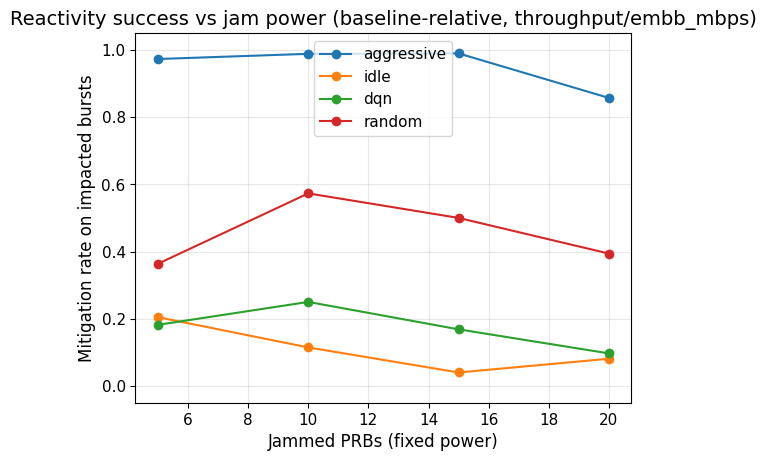

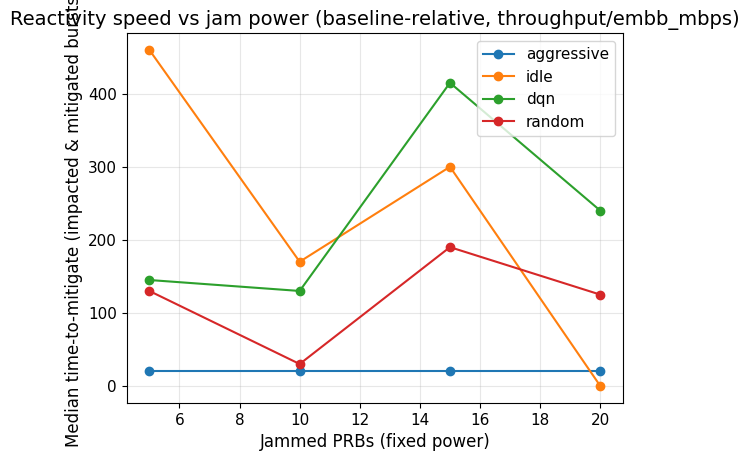

In [70]:
# 4) Mitigation rate (impacted only)
plt.figure()
for pol in POLICIES:
    sub = df_agg[df_agg["policy"] == pol].sort_values("power")
    if len(sub) == 0:
        continue
    plt.plot(sub["power"], sub["mitigation_rate_impacted"], marker="o", label=pol)
plt.xlabel("Jammed PRBs (fixed power)")
plt.ylabel("Mitigation rate on impacted bursts")
plt.title(f"Reactivity success vs jam power (baseline-relative, {METRIC_TAG})")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 5) Time-to-mitigate (impacted & mitigated only)
plt.figure()
for pol in POLICIES:
    sub = df_agg[df_agg["policy"] == pol].sort_values("power")
    if len(sub) == 0:
        continue
    plt.plot(sub["power"], sub["median_t_mitigate_impacted_mitigated"], marker="o", label=pol)
plt.xlabel("Jammed PRBs (fixed power)")
plt.ylabel("Median time-to-mitigate (impacted & mitigated bursts)")
plt.title(f"Reactivity speed vs jam power (baseline-relative, {METRIC_TAG})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Total jam cycles: 3200


,policy,power,run_id,episode_idx,jam_idx_global,jam_start_step,jam_end_step,on_len_samples,auc_on,impacted_on,mitigation_rate_time_on,mitigation_rate_time_on_after_impact,mitigated_on_any,t_mitigate_from_jamstart_sim_steps,mitigated_on_after_impact,t_mitigate_from_impact_sim_steps,mean_reserve_used_on,max_reserve_used_on,sum_reserve_used_on,n_jams_in_episode
0,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,0,10.0,1240.0,124,0.000980,True,0.266129,0.266129,False,NaN,False,NaN,4.951613,5.0,614.0,4
1,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,1,2500.0,3740.0,125,0.001133,True,0.264000,0.258065,False,NaN,False,NaN,4.952000,5.0,619.0,4
2,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,2,5000.0,6240.0,125,0.001051,True,0.272000,0.266129,False,NaN,False,NaN,4.952000,5.0,619.0,4
3,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,3,7500.0,8740.0,125,0.000923,True,0.304000,0.298387,False,NaN,False,NaN,4.952000,5.0,619.0,4
4,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,4,10010.0,11240.0,124,0.000000,False,1.000000,NaN,True,0.0,False,NaN,4.951613,5.0,614.0,4
5,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,5,12500.0,13740.0,125,0.000000,False,1.000000,NaN,True,0.0,False,NaN,4.952000,5.0,619.0,4
6,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,6,15000.0,16240.0,125,0.000000,False,1.000000,NaN,True,0.0,False,NaN,4.952000,5.0,619.0,4
7,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,7,17500.0,18740.0,125,0.000000,False,1.000000,NaN,True,0.0,False,NaN,4.952000,5.0,619.0,4
8,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,2,8,20010.0,21240.0,124,0.000000,False,1.000000,NaN,True,0.0,False,NaN,4.951613,5.0,614.0,4
9,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,2,9,22500.0,23740.0,125,0.000000,False,1.000000,NaN,True,0.0,False,NaN,4.952000,5.0,619.0,4



Episodes per (policy,power) (expect ~50):


policy      power
aggressive  5        50
            10       50
            15       50
            20       50
dqn         5        50
            10       50
            15       50
            20       50
idle        5        50
            10       50
            15       50
            20       50
random      5        50
            10       50
            15       50
            20       50
Name: episode_idx, dtype: int64


Cycles per (policy,power) (expect ~200 if 4 jams/episode x 50 eps):


policy      power
aggressive  5        200
            10       200
            15       200
            20       200
dqn         5        200
            10       200
            15       200
            20       200
idle        5        200
            10       200
            15       200
            20       200
random      5        200
            10       200
            15       200
            20       200
Name: jam_idx_global, dtype: int64


Jam runs per episode distribution (often expect all 4):


n_jams_in_episode
4    800
Name: count, dtype: int64

,policy,power,n_cycles,n_episodes,median_auc_on,mean_auc_on,impact_rate,mitigation_time_rate,mitigation_time_rate_after_impact,mitigation_success_burst,mitigation_success_after_impact,median_t_from_impact,median_reserve_on,mean_reserve_on,median_max_reserve_on,mean_sum_reserve_on
0,aggressive,5,200,50,0.006840,16.141079,0.690,0.370389,0.086055,0.345,0.035,10.0,4.952000,4.951903,5.0,617.750
1,aggressive,10,200,50,0.007336,16.165204,0.710,0.360168,0.097634,0.320,0.030,180.0,9.936000,9.935871,12.0,1239.500
2,aggressive,15,200,50,0.014614,16.226020,0.910,0.363560,0.299727,0.345,0.255,10.0,14.848000,14.847694,15.0,1852.250
3,aggressive,20,200,50,0.021622,16.276683,0.955,0.366519,0.335664,0.340,0.295,20.0,17.792000,17.791581,18.0,2219.500
4,dqn,5,200,50,0.005521,3.152132,0.720,0.340843,0.074993,0.330,0.040,45.0,2.205097,5.803420,18.0,724.030
5,dqn,10,200,50,0.012232,4.458271,0.825,0.335184,0.190329,0.325,0.150,50.0,5.440000,6.684958,18.0,834.015
6,dqn,15,200,50,0.086694,5.121042,0.865,0.314345,0.205209,0.340,0.205,250.0,9.340000,8.761397,18.0,1093.080
7,dqn,20,200,50,0.105643,8.210046,0.925,0.275159,0.212786,0.330,0.245,360.0,11.606484,10.511213,18.0,1311.315
8,idle,5,200,50,0.021666,19.158901,0.700,0.340645,0.056425,0.320,0.020,10.0,0.000000,0.000000,0.0,0.000
9,idle,10,200,50,2.478648,23.047203,0.750,0.281327,0.040285,0.260,0.010,10.0,0.000000,0.000000,0.0,0.000


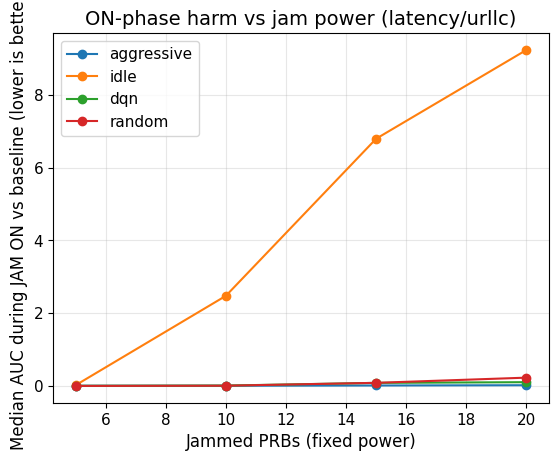

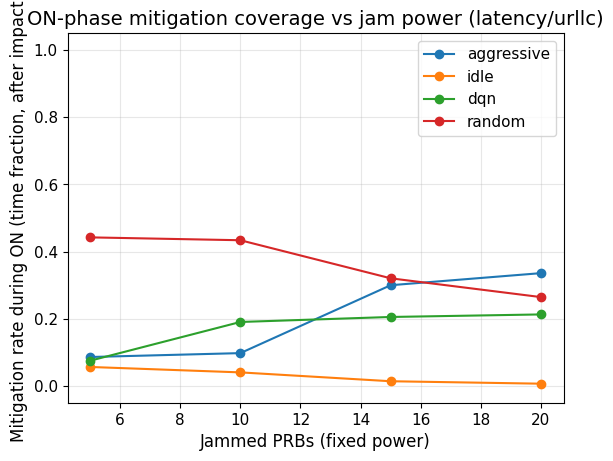

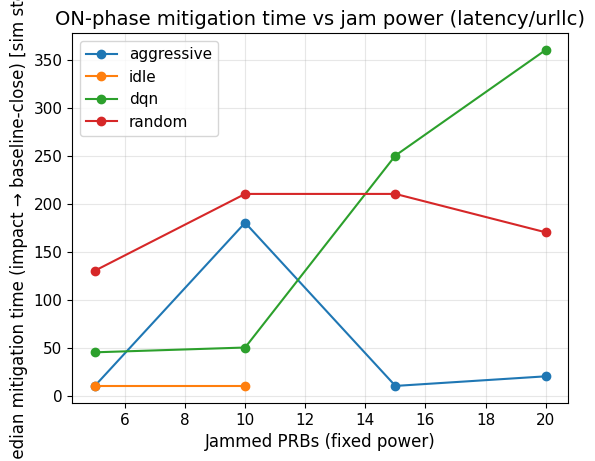

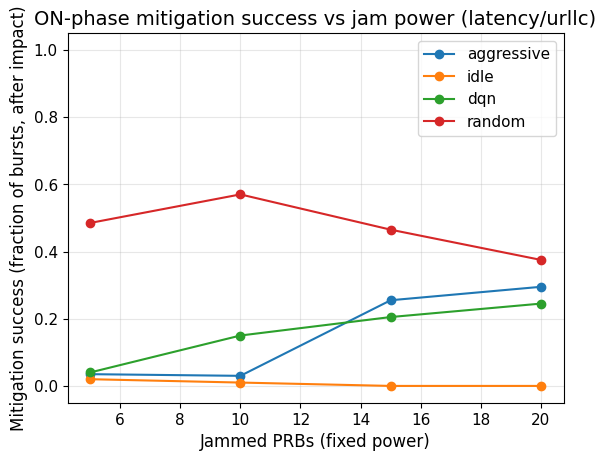

In [77]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

# ============================================================
# USER CONFIG
# ============================================================
ROOT = Path("../../tb_logs/23_jan")
POLICIES = ["aggressive", "idle", "dqn", "random"]
POWERS = [5, 10, 15, 20]

# TensorBoard tags
RESERVE_TAG = "obs/reserve_used_prb"
METRIC_TAG  = "latency/urllc"          # or "throughput/embb_mbps"
JAM_TAG     = "prb/effective_ratio"

# Episode & jam detection
EP_LEN_SIM     = 10000                 # sim steps per episode (as in your logs)
JAM_THRESHOLD  = 0.999                 # eff < threshold means jam ON

# Baseline folder suffix (per policy)
BASELINE_SUFFIX = "_jam_fixed_baseline_0"

# Mitigation definition (baseline-relative, during ON)
K_CONSEC = 10          # consecutive samples that must be "good" to declare mitigation
EPS      = 0.01        # tolerance vs baseline (e.g., 0.01 = within 1%)
LOWER_IS_BETTER = True # True for latency, False for throughput

# Alignment mode (IMPORTANT)
# - "within_episode": compares jam run to baseline profile by within-episode step (robust).
# - "absolute_step": compares by exact TB step values (works only if steps align perfectly).
BASELINE_ALIGN_MODE = "within_episode"  # recommended

# ============================================================
# TB reader
# ============================================================
def read_tb_scalar(event_file: Path, tags):
    tags = set(tags)
    out = {t: [] for t in tags}

    for rec in tf_record.tf_record_iterator(str(event_file)):
        e = Event.FromString(rec)
        if not e.summary.value:
            continue
        step = int(e.step)
        for v in e.summary.value:
            if v.tag in tags:
                out[v.tag].append((step, float(v.simple_value)))

    dfs = {}
    for t, rows in out.items():
        if not rows:
            dfs[t] = pd.DataFrame(columns=["step", "value"])
        else:
            df = pd.DataFrame(rows, columns=["step", "value"]).dropna()
            df = (
                df.sort_values("step")
                  .drop_duplicates("step", keep="last")
                  .reset_index(drop=True)
            )
            dfs[t] = df
    return dfs

# ============================================================
# Helpers
# ============================================================
def segment_bool_runs(is_true: np.ndarray):
    """Return list of (start_idx, end_idx_exclusive) for True-runs."""
    if len(is_true) == 0:
        return []
    x = is_true.astype(np.int8)
    d = np.diff(x, prepend=0, append=0)
    starts = np.where(d == 1)[0]
    ends   = np.where(d == -1)[0]
    return list(zip(starts, ends))

def first_k_consecutive_true(mask: np.ndarray, k: int):
    """First index i such that mask[i:i+k] are all True. None if not found."""
    if k <= 1:
        idx = np.where(mask)[0]
        return int(idx[0]) if len(idx) else None
    if len(mask) < k:
        return None
    s = np.convolve(mask.astype(np.int32), np.ones(k, dtype=np.int32), mode="valid")
    hits = np.where(s == k)[0]
    return int(hits[0]) if len(hits) else None

def find_event_file_under_test_folder(test_folder: Path):
    evs = sorted(test_folder.rglob("events.out.tfevents.*"))
    if not evs:
        return None
    evs = sorted(evs, key=lambda p: (p.stat().st_mtime, p.stat().st_size))
    return evs[-1]

def pick_test_folder(policy_dir: Path, suffix: str):
    matches = sorted([p for p in policy_dir.iterdir() if p.is_dir() and p.name.endswith(suffix)])
    return matches[0] if matches else None

# ============================================================
# Build aligned tables
# ============================================================
def build_jam_table(dfs):
    """Return df with: step, metric, eff, reserve_used_prb."""
    df_metric = dfs[METRIC_TAG].rename(columns={"value": "metric"})
    df_jam    = dfs[JAM_TAG].rename(columns={"value": "eff"})
    df_res    = dfs[RESERVE_TAG].rename(columns={"value": "reserve_used_prb"})

    df = df_metric.merge(df_jam, on="step", how="inner")
    df = df.merge(df_res, on="step", how="left")  # left: reserve may miss some steps
    return df.sort_values("step").reset_index(drop=True)

def add_episode_columns(df: pd.DataFrame, ep_len: int):
    """Adds episode_idx and within_ep_step (0..ep_len-1) based on first step in file."""
    if df.empty:
        return df.copy()
    df = df.copy()
    step0 = int(df["step"].iloc[0])
    df["episode_idx"]     = ((df["step"] - step0) // ep_len).astype(int)
    df["within_ep_step"]  = ((df["step"] - step0) % ep_len).astype(int)
    return df

def build_baseline_profile(dfs_base):
    """
    Robust baseline: build a profile of baseline metric vs within-episode step.
    We take median across baseline episodes for each within_ep_step.
    """
    dfb = dfs_base[METRIC_TAG].rename(columns={"value": "base_metric"}).sort_values("step")
    dfb = dfb.drop_duplicates("step", keep="last").reset_index(drop=True)
    dfb = add_episode_columns(dfb, EP_LEN_SIM)

    prof = (
        dfb.groupby("within_ep_step")["base_metric"]
           .median()
           .reset_index()
           .sort_values("within_ep_step")
           .reset_index(drop=True)
    )
    return prof  # columns: within_ep_step, base_metric

def build_baseline_metric_absolute(dfs_base):
    """Baseline table keyed by absolute TB step (only safe if steps align perfectly)."""
    dfb = dfs_base[METRIC_TAG].rename(columns={"value":"base_metric"}).sort_values("step")
    dfb = dfb.drop_duplicates("step", keep="last").reset_index(drop=True)
    return dfb  # columns: step, base_metric

# ============================================================
# Core computation
# ============================================================
def compute_on_metrics(df_jam_raw: pd.DataFrame,
                       baseline_obj: pd.DataFrame,
                       policy: str,
                       power: int,
                       run_id: str,
                       align_mode: str = "within_episode"):
    """
    Computes mitigation metrics per jam-ON burst:
      - burst success (ever reaches good for K_CONSEC)
      - time coverage during ON (fraction good samples)
      - time coverage after impact
      - mitigation time from impact -> first K_CONSEC good (during ON)
      - also keeps your AUC harm measure for reference
    """
    if df_jam_raw.empty:
        return pd.DataFrame()

    df_jam = add_episode_columns(df_jam_raw, EP_LEN_SIM)

    # Attach baseline metric
    if align_mode == "within_episode":
        # merge on within_ep_step
        df = df_jam.merge(baseline_obj, on="within_ep_step", how="left")
    elif align_mode == "absolute_step":
        df = df_jam.merge(baseline_obj, on="step", how="inner")
    else:
        raise ValueError("align_mode must be 'within_episode' or 'absolute_step'")

    df = df.sort_values("step").reset_index(drop=True)
    df = df.dropna(subset=["base_metric"])  # if baseline missing, drop those points
    if df.empty:
        return pd.DataFrame()

    steps   = df["step"].to_numpy()
    m_jam   = df["metric"].to_numpy()
    m_base  = df["base_metric"].to_numpy()
    eff     = df["eff"].to_numpy()
    reserve = df["reserve_used_prb"].to_numpy()

    ep_idx_arr = df["episode_idx"].to_numpy()

    is_jam = eff < JAM_THRESHOLD
    jam_runs = segment_bool_runs(is_jam)

    # count jam bursts per episode for sanity
    jam_count_per_ep = {}
    for (s_idx, e_idx) in jam_runs:
        ep = int(ep_idx_arr[s_idx])
        jam_count_per_ep[ep] = jam_count_per_ep.get(ep, 0) + 1

    rows = []
    for j, (s_idx, e_idx) in enumerate(jam_runs):
        if e_idx <= s_idx:
            continue

        on_steps = steps[s_idx:e_idx]
        on_jam   = m_jam[s_idx:e_idx]
        on_base  = m_base[s_idx:e_idx]
        r_on     = reserve[s_idx:e_idx]

        if len(on_jam) == 0:
            continue

        # Reserve summaries during ON
        mean_reserve_on = float(np.nanmean(r_on)) if len(r_on) else np.nan
        max_reserve_on  = float(np.nanmax(r_on))  if len(r_on) else np.nan
        sum_reserve_on  = float(np.nansum(r_on))  if len(r_on) else np.nan

        # "good" definition vs baseline
        base_safe = on_base + 1e-12

        if LOWER_IS_BETTER:
            # harm is how much worse than baseline (only positive)
            harm  = np.maximum(0.0, on_jam - on_base)
            auc_on = float(np.nansum(harm))
            good_on = on_jam <= (1.0 + EPS) * base_safe
            impacted = np.any(on_jam > (1.0 + EPS) * base_safe)
        else:
            harm  = np.maximum(0.0, on_base - on_jam)
            auc_on = float(np.nansum(harm))
            good_on = on_jam >= (1.0 - EPS) * base_safe
            impacted = np.any(on_jam < (1.0 - EPS) * base_safe)

        bad_on = ~good_on

        # (Q1) time-based mitigation rate (coverage) inside ON
        mitigation_rate_time_on = float(np.mean(good_on)) if len(good_on) else np.nan

        # impact index = first "bad" sample during ON
        impact_idxs = np.where(bad_on)[0]
        impact_idx = int(impact_idxs[0]) if len(impact_idxs) else None

        if impact_idx is None:
            mitigation_rate_time_on_after_impact = np.nan
        else:
            mitigation_rate_time_on_after_impact = float(np.mean(good_on[impact_idx:]))

        # (burst-level) "did we ever mitigate during ON?"
        mit_offset_any = first_k_consecutive_true(good_on, K_CONSEC)
        mitigated_on_any = mit_offset_any is not None
        t_mitigate_from_jamstart = (
            float(on_steps[mit_offset_any] - on_steps[0]) if mitigated_on_any else np.nan
        )

        # (Q2) time-to-mitigate measured from impact (NOT from jam start)
        if impact_idx is None:
            mitigated_after_impact = False
            t_mitigate_from_impact = np.nan
        else:
            mit_offset2 = first_k_consecutive_true(good_on[impact_idx:], K_CONSEC)
            if mit_offset2 is None:
                mitigated_after_impact = False
                t_mitigate_from_impact = np.nan
            else:
                mitigated_after_impact = True
                idx_mit = impact_idx + mit_offset2
                t_mitigate_from_impact = float(on_steps[idx_mit] - on_steps[impact_idx])

        ep = int(ep_idx_arr[s_idx])

        rows.append({
            "policy": policy,
            "power": power,
            "run_id": run_id,
            "episode_idx": ep,
            "jam_idx_global": int(j),

            "jam_start_step": float(on_steps[0]),
            "jam_end_step": float(on_steps[-1]),
            "on_len_samples": int(e_idx - s_idx),

            # Effectiveness (harm) and whether jam actually hurt metric
            "auc_on": auc_on,
            "impacted_on": bool(impacted),

            # Q1: time-based mitigation rates (coverage)
            "mitigation_rate_time_on": mitigation_rate_time_on,
            "mitigation_rate_time_on_after_impact": mitigation_rate_time_on_after_impact,

            # Burst-level success (your previous mitigation_rate concept)
            "mitigated_on_any": bool(mitigated_on_any),
            "t_mitigate_from_jamstart_sim_steps": t_mitigate_from_jamstart,

            # Q2: time to mitigate measured from impact
            "mitigated_on_after_impact": bool(mitigated_after_impact),
            "t_mitigate_from_impact_sim_steps": t_mitigate_from_impact,

            # Reserve usage summaries during ON
            "mean_reserve_used_on": mean_reserve_on,
            "max_reserve_used_on": max_reserve_on,
            "sum_reserve_used_on": sum_reserve_on,
        })

    out = pd.DataFrame(rows)
    if not out.empty:
        out["n_jams_in_episode"] = out["episode_idx"].map(jam_count_per_ep).fillna(0).astype(int)
    return out

# ============================================================
# MAIN: load baseline per policy, then jam runs per power
# ============================================================
all_cycles = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    if not policy_dir.exists():
        print(f"[WARN] policy folder missing: {policy_dir}")
        continue

    # ----- baseline folder per policy -----
    base_folder = pick_test_folder(policy_dir, BASELINE_SUFFIX)
    if base_folder is None:
        print(f"[WARN] missing baseline folder for policy={policy} suffix={BASELINE_SUFFIX}")
        continue

    base_ev = find_event_file_under_test_folder(base_folder)
    if base_ev is None:
        print(f"[WARN] no event file in baseline folder: {base_folder}")
        continue

    dfs_base = read_tb_scalar(base_ev, tags=[METRIC_TAG])

    # Build baseline object depending on alignment mode
    if BASELINE_ALIGN_MODE == "within_episode":
        baseline_obj = build_baseline_profile(dfs_base)     # within_ep_step -> base_metric (median)
    else:
        baseline_obj = build_baseline_metric_absolute(dfs_base)  # step -> base_metric

    # ----- iterate jam powers -----
    for pwr in POWERS:
        jam_folder = pick_test_folder(policy_dir, f"_jam_fixed_{pwr}")
        if jam_folder is None:
            print(f"[WARN] missing jam folder for {policy} power={pwr}")
            continue

        jam_ev = find_event_file_under_test_folder(jam_folder)
        if jam_ev is None:
            print(f"[WARN] no event file in jam folder: {jam_folder}")
            continue

        dfs_jam = read_tb_scalar(jam_ev, tags=[METRIC_TAG, JAM_TAG, RESERVE_TAG])
        df_jam  = build_jam_table(dfs_jam)

        df_cycles = compute_on_metrics(
            df_jam_raw=df_jam,
            baseline_obj=baseline_obj,
            policy=policy,
            power=pwr,
            run_id=str(jam_folder),
            align_mode=BASELINE_ALIGN_MODE,
        )
        if not df_cycles.empty:
            all_cycles.append(df_cycles)

df_cycles_all = pd.concat(all_cycles, ignore_index=True) if all_cycles else pd.DataFrame()
print("Total jam cycles:", len(df_cycles_all))
try:
    display(df_cycles_all.head(10))
except NameError:
    print(df_cycles_all.head(10))

# ============================================================
# SANITY CHECKS
# ============================================================
if not df_cycles_all.empty:
    print("\nEpisodes per (policy,power) (expect ~50):")
    try:
        display(df_cycles_all.groupby(["policy","power"])["episode_idx"].nunique())
    except NameError:
        print(df_cycles_all.groupby(["policy","power"])["episode_idx"].nunique())

    print("\nCycles per (policy,power) (expect ~200 if 4 jams/episode x 50 eps):")
    try:
        display(df_cycles_all.groupby(["policy","power"])["jam_idx_global"].count())
    except NameError:
        print(df_cycles_all.groupby(["policy","power"])["jam_idx_global"].count())

    print("\nJam runs per episode distribution (often expect all 4):")
    dist = (
        df_cycles_all.groupby(["policy","power","episode_idx"])["n_jams_in_episode"]
        .first().value_counts().sort_index()
    )
    try:
        display(dist)
    except NameError:
        print(dist)

# ============================================================
# AGGREGATE + PLOTS
# ============================================================
if not df_cycles_all.empty:
    tmp = df_cycles_all.copy()

    def median_if_any(series):
        series = series.dropna()
        return float(series.median()) if len(series) else np.nan

    # Aggregate by policy/power
    df_agg = (
        tmp.groupby(["policy","power"])
           .agg(
               n_cycles=("jam_idx_global", "count"),
               n_episodes=("episode_idx", "nunique"),

               # Effect/harm
               median_auc_on=("auc_on", "median"),
               mean_auc_on=("auc_on", "mean"),
               impact_rate=("impacted_on", "mean"),

               # Q1: time-based mitigation rate (coverage)
               mitigation_time_rate=("mitigation_rate_time_on", "mean"),
               mitigation_time_rate_after_impact=("mitigation_rate_time_on_after_impact", "mean"),

               # Burst-level success rate (old “mitigation_rate” concept)
               mitigation_success_burst=("mitigated_on_any", "mean"),
               mitigation_success_after_impact=("mitigated_on_after_impact", "mean"),

               # Q2: mitigation time (median), from impact only
               median_t_from_impact=("t_mitigate_from_impact_sim_steps", lambda s: median_if_any(s)),

               # Reserve usage
               median_reserve_on=("mean_reserve_used_on", "median"),
               mean_reserve_on=("mean_reserve_used_on", "mean"),
               median_max_reserve_on=("max_reserve_used_on", "median"),
               mean_sum_reserve_on=("sum_reserve_used_on", "mean"),
           )
           .reset_index()
           .sort_values(["policy","power"])
    )

    try:
        display(df_agg)
    except NameError:
        print(df_agg)

    # -------------------------
    # Plot 1: Harm (AUC_on) vs power
    # -------------------------
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_auc_on"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median AUC during JAM ON vs baseline (lower is better)")
    plt.title(f"ON-phase harm vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # -------------------------
    # Plot 2 (Q1): time-based mitigation rate DURING ON (after impact)
    # -------------------------
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["mitigation_time_rate_after_impact"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Mitigation rate during ON (time fraction, after impact)")
    plt.title(f"ON-phase mitigation coverage vs jam power ({METRIC_TAG})")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # -------------------------
    # Plot 3 (Q2): mitigation time (impact -> baseline-close), during ON
    # -------------------------
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_t_from_impact"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median mitigation time (impact → baseline-close) [sim steps]")
    plt.title(f"ON-phase mitigation time vs jam power ({METRIC_TAG})")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # -------------------------
    # Plot 4 (optional): burst-level success rate (old metric)
    # -------------------------
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["mitigation_success_after_impact"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Mitigation success (fraction of bursts, after impact)")
    plt.title(f"ON-phase mitigation success vs jam power ({METRIC_TAG})")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


In [78]:
# df_agg must exist from the updated code
tbl_rate = (
    df_agg.pivot(index="policy", columns="power", values="mitigation_time_rate_after_impact")
          .sort_index()
)

# Pretty formatting (percent)
tbl_rate_fmt = tbl_rate.applymap(lambda x: "" if pd.isna(x) else f"{100*x:.1f}%")

display(tbl_rate_fmt)
# Optional: save
tbl_rate_fmt.to_csv("table_mitigation_rate_after_impact.csv")

tbl_time = (
    df_agg.pivot(index="policy", columns="power", values="median_t_from_impact")
          .sort_index()
)

# Format (sim steps). If you later convert steps->ms, update formatting here.
tbl_time_fmt = tbl_time.applymap(lambda x: "" if pd.isna(x) else f"{x:.0f}")

display(tbl_time_fmt)
tbl_time_fmt.to_csv("table_mitigation_time_from_impact_steps.csv")


/tmp/ipykernel_1173802/713567465.py:8: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  tbl_rate_fmt = tbl_rate.applymap(lambda x: "" if pd.isna(x) else f"{100*x:.1f}%")


power,5,10,15,20
policy,,,,
aggressive,8.6%,9.8%,30.0%,33.6%
dqn,7.5%,19.0%,20.5%,21.3%
idle,5.6%,4.0%,1.4%,0.7%
random,44.2%,43.4%,32.0%,26.4%


/tmp/ipykernel_1173802/713567465.py:20: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  tbl_time_fmt = tbl_time.applymap(lambda x: "" if pd.isna(x) else f"{x:.0f}")


power,5,10,15,20
policy,,,,
aggressive,10,180,10,20
dqn,45,50,250,360
idle,10,10,,
random,130,210,210,170


In [79]:
rate = df_agg.pivot(index="policy", columns="power", values="mitigation_time_rate_after_impact")
timp = df_agg.pivot(index="policy", columns="power", values="median_t_from_impact")

tbl_combo = rate.copy()

for pol in tbl_combo.index:
    for pwr in tbl_combo.columns:
        r = rate.loc[pol, pwr]
        t = timp.loc[pol, pwr]
        if pd.isna(r) and pd.isna(t):
            tbl_combo.loc[pol, pwr] = ""
        elif pd.isna(t):
            tbl_combo.loc[pol, pwr] = f"{100*r:.1f}% / –"
        else:
            tbl_combo.loc[pol, pwr] = f"{100*r:.1f}% / {t:.0f}"

display(tbl_combo)
tbl_combo.to_csv("table_mitigation_rate_and_time.csv")


/tmp/ipykernel_1173802/3655388580.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '8.6% / 10' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  tbl_combo.loc[pol, pwr] = f"{100*r:.1f}% / {t:.0f}"
/tmp/ipykernel_1173802/3655388580.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '9.8% / 180' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  tbl_combo.loc[pol, pwr] = f"{100*r:.1f}% / {t:.0f}"
/tmp/ipykernel_1173802/3655388580.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '30.0% / 10' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  tbl_combo.loc[pol, pwr] = f"{100*r:.1f}% / {t:.0f}"
/tmp/ipykernel_1173802/365

power,5,10,15,20
policy,,,,
aggressive,8.6% / 10,9.8% / 180,30.0% / 10,33.6% / 20
dqn,7.5% / 45,19.0% / 50,20.5% / 250,21.3% / 360
idle,5.6% / 10,4.0% / 10,1.4% / –,0.7% / –
random,44.2% / 130,43.4% / 210,32.0% / 210,26.4% / 170


In [80]:
tbl_impact = (
    df_agg.pivot(index="policy", columns="power", values="impact_rate")
          .sort_index()
)
tbl_impact_fmt = tbl_impact.applymap(lambda x: "" if pd.isna(x) else f"{100*x:.1f}%")
display(tbl_impact_fmt)
tbl_impact_fmt.to_csv("table_impact_rate.csv")


/tmp/ipykernel_1173802/2938521084.py:5: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  tbl_impact_fmt = tbl_impact.applymap(lambda x: "" if pd.isna(x) else f"{100*x:.1f}%")


power,5,10,15,20
policy,,,,
aggressive,69.0%,71.0%,91.0%,95.5%
dqn,72.0%,82.5%,86.5%,92.5%
idle,70.0%,75.0%,92.0%,96.0%
random,76.0%,88.0%,94.0%,96.0%


In [81]:
print(tbl_combo.to_latex(index=True, escape=False))

\begin{tabular}{lllll}
\toprule
power & 5 & 10 & 15 & 20 \\
policy &  &  &  &  \\
\midrule
aggressive & 8.6% / 10 & 9.8% / 180 & 30.0% / 10 & 33.6% / 20 \\
dqn & 7.5% / 45 & 19.0% / 50 & 20.5% / 250 & 21.3% / 360 \\
idle & 5.6% / 10 & 4.0% / 10 & 1.4% / – & 0.7% / – \\
random & 44.2% / 130 & 43.4% / 210 & 32.0% / 210 & 26.4% / 170 \\
\bottomrule
\end{tabular}



Total jam cycles: 3200


,policy,power,run_id,episode_idx,jam_idx_global,jam_start_step,jam_end_step,on_len_samples,auc_on,impacted_on,impact_start_offset_samples,mitigation_rate_time_on,mitigation_rate_time_on_after_impact,mitigated_on_after_impact,t_mitigate_from_impact_sim_steps,mitigated_on_any,mean_reserve_used_on,max_reserve_used_on,sum_reserve_used_on,n_jams_in_episode
0,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,0,10.0,1240.0,124,0.000980,True,40.0,0.266129,0.261905,False,NaN,False,4.951613,5.0,614.0,4
1,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,1,2500.0,3740.0,125,0.001133,True,1.0,0.264000,0.258065,False,NaN,False,4.952000,5.0,619.0,4
2,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,2,5000.0,6240.0,125,0.001051,True,17.0,0.272000,0.259259,False,NaN,False,4.952000,5.0,619.0,4
3,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,0,3,7500.0,8740.0,125,0.000923,True,1.0,0.304000,0.298387,False,NaN,False,4.952000,5.0,619.0,4
4,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,4,10010.0,11240.0,124,0.000000,False,NaN,1.000000,NaN,False,NaN,True,4.951613,5.0,614.0,4
5,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,5,12500.0,13740.0,125,0.000000,False,NaN,1.000000,NaN,False,NaN,True,4.952000,5.0,619.0,4
6,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,6,15000.0,16240.0,125,0.000000,False,NaN,1.000000,NaN,False,NaN,True,4.952000,5.0,619.0,4
7,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,1,7,17500.0,18740.0,125,0.000000,False,NaN,1.000000,NaN,False,NaN,True,4.952000,5.0,619.0,4
8,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,2,8,20010.0,21240.0,124,0.000000,False,NaN,1.000000,NaN,False,NaN,True,4.951613,5.0,614.0,4
9,aggressive,5,../../tb_logs/23_jan/aggressive/gym_from_testi...,2,9,22500.0,23740.0,125,0.000000,False,NaN,1.000000,NaN,False,NaN,True,4.952000,5.0,619.0,4



Episodes per (policy,power) (expect ~50):


policy      power
aggressive  5        50
            10       50
            15       50
            20       50
dqn         5        50
            10       50
            15       50
            20       50
idle        5        50
            10       50
            15       50
            20       50
random      5        50
            10       50
            15       50
            20       50
Name: episode_idx, dtype: int64


Cycles per (policy,power) (expect ~200 if 4 jams/episode x 50 eps):


policy      power
aggressive  5        200
            10       200
            15       200
            20       200
dqn         5        200
            10       200
            15       200
            20       200
idle        5        200
            10       200
            15       200
            20       200
random      5        200
            10       200
            15       200
            20       200
Name: jam_idx_global, dtype: int64

... (7 outputs left out)

/tmp/ipykernel_1173802/608978097.py:492: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  tbl_time_fmt = tbl_time.applymap(lambda x: "" if pd.isna(x) else f"{x:.0f}")


power,5,10,15,20
policy,,,,
aggressive,,,,50
dqn,60,95,270,360
idle,,,,
random,230,270,295,290


/tmp/ipykernel_1173802/608978097.py:503: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  tbl_gain_fmt = tbl_gain.applymap(lambda x: "" if pd.isna(x) else f"{100*x:+.1f} pp")


power,5,10,15,20
policy,,,,
aggressive,+1.4 pp,+1.7 pp,+2.5 pp,+4.5 pp
dqn,+3.4 pp,+10.7 pp,+14.6 pp,+16.7 pp
idle,+0.0 pp,+0.0 pp,+0.0 pp,+0.0 pp
random,+33.8 pp,+33.6 pp,+25.0 pp,+22.4 pp


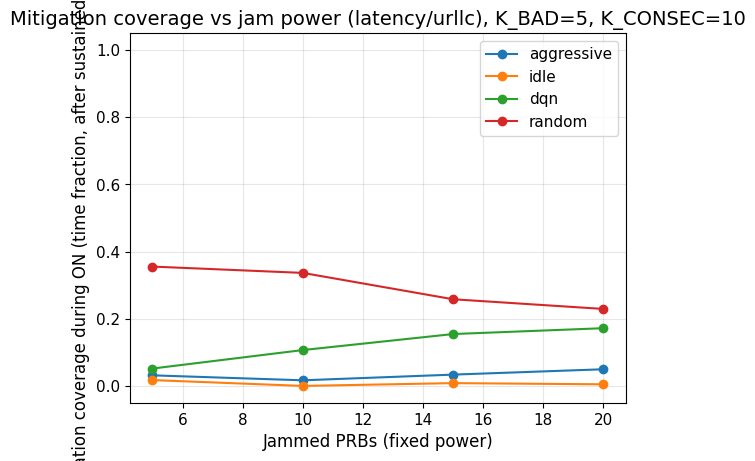

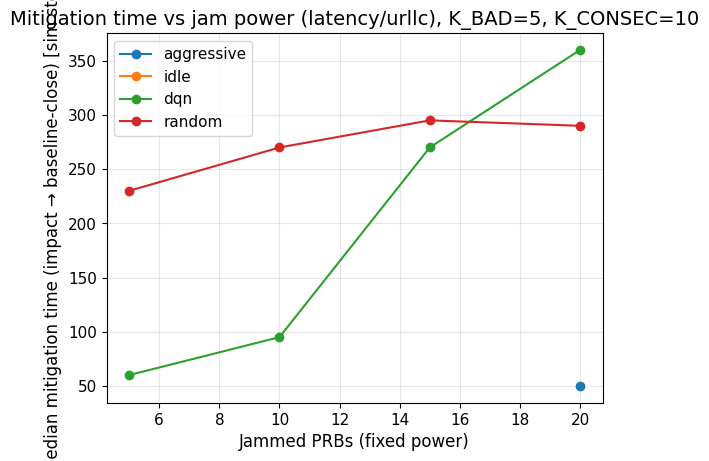

In [86]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.python.lib.io import tf_record
from tensorboard.compat.proto.event_pb2 import Event

# ============================================================
# USER CONFIG
# ============================================================
ROOT = Path("../../tb_logs/23_jan")
POLICIES = ["aggressive", "idle", "dqn", "random"]
POWERS = [5, 10, 15, 20]

# TensorBoard tags
RESERVE_TAG = "obs/reserve_used_prb"
METRIC_TAG  = "latency/urllc"          # or "throughput/embb_mbps"
JAM_TAG     = "prb/effective_ratio"

# Episode & jam detection
EP_LEN_SIM     = 10000                 # sim steps per episode (as in your logs)
JAM_THRESHOLD  = 0.999                 # eff < threshold means jam ON

# Baseline folder suffix (per policy)
BASELINE_SUFFIX = "_jam_fixed_baseline_0"

# Baseline alignment (recommended)
# - "within_episode": baseline profile by within-episode step (robust)
# - "absolute_step": merge by absolute TB step (only if steps align perfectly)
BASELINE_ALIGN_MODE = "within_episode"

# Mitigation definition (baseline-relative, during ON)
K_CONSEC = 10          # how long must stay "good" to count as mitigated (reduces noise)
EPS      = 0.01        # tolerance vs baseline (0.01 = within 1%)
LOWER_IS_BETTER = True # True for latency, False for throughput

# NEW: sustained impact definition (prevents "impact" triggered by 1 spike)
K_BAD = 5             # require K_BAD consecutive "bad" samples to declare impacted
# (good default: K_BAD = K_CONSEC; you can try 5, 10, 15)

# Optional: trim ON-burst edges (helps if ON/OFF boundaries inflate "good")
TRIM_EDGE = 0          # set to 5 or 10 if needed (samples trimmed from start/end of each ON burst)

# ============================================================
# TB reader
# ============================================================
def read_tb_scalar(event_file: Path, tags):
    tags = set(tags)
    out = {t: [] for t in tags}

    for rec in tf_record.tf_record_iterator(str(event_file)):
        e = Event.FromString(rec)
        if not e.summary.value:
            continue
        step = int(e.step)
        for v in e.summary.value:
            if v.tag in tags:
                out[v.tag].append((step, float(v.simple_value)))

    dfs = {}
    for t, rows in out.items():
        if not rows:
            dfs[t] = pd.DataFrame(columns=["step", "value"])
        else:
            df = pd.DataFrame(rows, columns=["step", "value"]).dropna()
            df = (
                df.sort_values("step")
                  .drop_duplicates("step", keep="last")
                  .reset_index(drop=True)
            )
            dfs[t] = df
    return dfs

# ============================================================
# Helpers
# ============================================================
def segment_bool_runs(is_true: np.ndarray):
    """Return list of (start_idx, end_idx_exclusive) for True-runs."""
    if len(is_true) == 0:
        return []
    x = is_true.astype(np.int8)
    d = np.diff(x, prepend=0, append=0)
    starts = np.where(d == 1)[0]
    ends   = np.where(d == -1)[0]
    return list(zip(starts, ends))

def first_k_consecutive_true(mask: np.ndarray, k: int):
    """First index i such that mask[i:i+k] are all True. None if not found."""
    if k <= 1:
        idx = np.where(mask)[0]
        return int(idx[0]) if len(idx) else None
    if len(mask) < k:
        return None
    s = np.convolve(mask.astype(np.int32), np.ones(k, dtype=np.int32), mode="valid")
    hits = np.where(s == k)[0]
    return int(hits[0]) if len(hits) else None

def find_event_file_under_test_folder(test_folder: Path):
    evs = sorted(test_folder.rglob("events.out.tfevents.*"))
    if not evs:
        return None
    evs = sorted(evs, key=lambda p: (p.stat().st_mtime, p.stat().st_size))
    return evs[-1]

def pick_test_folder(policy_dir: Path, suffix: str):
    matches = sorted([p for p in policy_dir.iterdir() if p.is_dir() and p.name.endswith(suffix)])
    return matches[0] if matches else None

# ============================================================
# Build aligned tables
# ============================================================
def build_jam_table(dfs):
    """Return df with: step, metric, eff, reserve_used_prb."""
    df_metric = dfs[METRIC_TAG].rename(columns={"value": "metric"})
    df_jam    = dfs[JAM_TAG].rename(columns={"value": "eff"})
    df_res    = dfs[RESERVE_TAG].rename(columns={"value": "reserve_used_prb"})

    df = df_metric.merge(df_jam, on="step", how="inner")
    df = df.merge(df_res, on="step", how="left")  # left: reserve may miss some steps
    return df.sort_values("step").reset_index(drop=True)

def add_episode_columns(df: pd.DataFrame, ep_len: int):
    """Adds episode_idx and within_ep_step (0..ep_len-1) based on first step in file."""
    if df.empty:
        return df.copy()
    df = df.copy()
    step0 = int(df["step"].iloc[0])
    df["episode_idx"]     = ((df["step"] - step0) // ep_len).astype(int)
    df["within_ep_step"]  = ((df["step"] - step0) % ep_len).astype(int)
    return df

def build_baseline_profile(dfs_base):
    """
    Robust baseline: baseline metric profile vs within-episode step.
    Uses median across baseline episodes for each within_ep_step.
    """
    dfb = dfs_base[METRIC_TAG].rename(columns={"value": "base_metric"}).sort_values("step")
    dfb = dfb.drop_duplicates("step", keep="last").reset_index(drop=True)
    dfb = add_episode_columns(dfb, EP_LEN_SIM)

    prof = (
        dfb.groupby("within_ep_step")["base_metric"]
           .median()
           .reset_index()
           .sort_values("within_ep_step")
           .reset_index(drop=True)
    )
    return prof  # columns: within_ep_step, base_metric

def build_baseline_metric_absolute(dfs_base):
    """Baseline table keyed by absolute TB step (only safe if steps align perfectly)."""
    dfb = dfs_base[METRIC_TAG].rename(columns={"value":"base_metric"}).sort_values("step")
    dfb = dfb.drop_duplicates("step", keep="last").reset_index(drop=True)
    return dfb  # columns: step, base_metric

# ============================================================
# Core computation (per jam ON burst)
# ============================================================
def compute_on_metrics(df_jam_raw: pd.DataFrame,
                       baseline_obj: pd.DataFrame,
                       policy: str,
                       power: int,
                       run_id: str,
                       align_mode: str = "within_episode"):
    """
    Computes per-burst metrics:
      - impacted_on: sustained impact (K_BAD consecutive bad)
      - impact_start_idx: where sustained impact begins
      - mitigation coverage during ON (after impact)
      - time-to-mitigate from impact (K_CONSEC good)
      - burst-level success rates (optional)
      - AUC harm during ON
    """
    if df_jam_raw.empty:
        return pd.DataFrame()

    df_jam = add_episode_columns(df_jam_raw, EP_LEN_SIM)

    # Attach baseline metric
    if align_mode == "within_episode":
        df = df_jam.merge(baseline_obj, on="within_ep_step", how="left")
    elif align_mode == "absolute_step":
        df = df_jam.merge(baseline_obj, on="step", how="inner")
    else:
        raise ValueError("align_mode must be 'within_episode' or 'absolute_step'")

    df = df.sort_values("step").reset_index(drop=True)
    df = df.dropna(subset=["base_metric"])
    if df.empty:
        return pd.DataFrame()

    steps   = df["step"].to_numpy()
    m_jam   = df["metric"].to_numpy()
    m_base  = df["base_metric"].to_numpy()
    eff     = df["eff"].to_numpy()
    reserve = df["reserve_used_prb"].to_numpy()

    ep_idx_arr = df["episode_idx"].to_numpy()

    # Jam ON mask and segments
    is_jam = eff < JAM_THRESHOLD
    jam_runs = segment_bool_runs(is_jam)

    # Count bursts per episode (sanity)
    jam_count_per_ep = {}
    for (s_idx, e_idx) in jam_runs:
        ep = int(ep_idx_arr[s_idx])
        jam_count_per_ep[ep] = jam_count_per_ep.get(ep, 0) + 1

    rows = []
    for j, (s_idx, e_idx) in enumerate(jam_runs):
        if e_idx <= s_idx:
            continue

        # Optional edge trimming
        s2 = s_idx + TRIM_EDGE
        e2 = e_idx - TRIM_EDGE
        if e2 <= s2:
            continue

        on_steps = steps[s2:e2]
        on_jam   = m_jam[s2:e2]
        on_base  = m_base[s2:e2]
        r_on     = reserve[s2:e2]

        if len(on_jam) == 0:
            continue

        # Reserve summaries during ON
        mean_reserve_on = float(np.nanmean(r_on)) if len(r_on) else np.nan
        max_reserve_on  = float(np.nanmax(r_on))  if len(r_on) else np.nan
        sum_reserve_on  = float(np.nansum(r_on))  if len(r_on) else np.nan

        base_safe = on_base + 1e-12

        # Define GOOD and HARM
        if LOWER_IS_BETTER:
            harm   = np.maximum(0.0, on_jam - on_base)
            good_on = on_jam <= (1.0 + EPS) * base_safe
        else:
            harm   = np.maximum(0.0, on_base - on_jam)
            good_on = on_jam >= (1.0 - EPS) * base_safe

        auc_on = float(np.nansum(harm))
        bad_on = ~good_on

        # ----------------------------------------------------
        # NEW: sustained impact definition
        # impacted_on=True if there exists K_BAD consecutive BAD samples
        # impact_start_idx = first index where such a run begins
        # ----------------------------------------------------
        impact_start_idx = first_k_consecutive_true(bad_on, K_BAD)
        impacted_on = impact_start_idx is not None

        # ----------------------------------------------------
        # Q1: time-based mitigation coverage during ON
        # - overall coverage during ON
        # - after sustained impact starts (matches your intent)
        # ----------------------------------------------------
        mitigation_rate_time_on = float(np.mean(good_on))

        if not impacted_on:
            mitigation_rate_time_on_after_impact = np.nan
        else:
            mitigation_rate_time_on_after_impact = float(np.mean(good_on[impact_start_idx:]))

        # ----------------------------------------------------
        # Burst-level success (optional)
        # did it ever become good for K_CONSEC (anywhere)
        # ----------------------------------------------------
        mit_offset_any = first_k_consecutive_true(good_on, K_CONSEC)
        mitigated_on_any = mit_offset_any is not None

        # ----------------------------------------------------
        # Q2: mitigation time from sustained impact -> K_CONSEC good
        # Only meaningful if impacted_on=True
        # ----------------------------------------------------
        if not impacted_on:
            mitigated_on_after_impact = False
            t_mitigate_from_impact = np.nan
        else:
            mit_offset2 = first_k_consecutive_true(good_on[impact_start_idx:], K_CONSEC)
            if mit_offset2 is None:
                mitigated_on_after_impact = False
                t_mitigate_from_impact = np.nan
            else:
                mitigated_on_after_impact = True
                idx_mit = impact_start_idx + mit_offset2
                t_mitigate_from_impact = float(on_steps[idx_mit] - on_steps[impact_start_idx])

        ep = int(ep_idx_arr[s_idx])

        rows.append({
            "policy": policy,
            "power": power,
            "run_id": run_id,
            "episode_idx": ep,
            "jam_idx_global": int(j),

            "jam_start_step": float(on_steps[0]),
            "jam_end_step": float(on_steps[-1]),
            "on_len_samples": int(len(on_steps)),

            # Effectiveness / harm
            "auc_on": auc_on,

            # NEW impact definition
            "impacted_on": bool(impacted_on),
            "impact_start_offset_samples": (int(impact_start_idx) if impacted_on else np.nan),

            # Q1: time coverage
            "mitigation_rate_time_on": mitigation_rate_time_on,
            "mitigation_rate_time_on_after_impact": mitigation_rate_time_on_after_impact,

            # Q2: time to mitigate from impact
            "mitigated_on_after_impact": bool(mitigated_on_after_impact),
            "t_mitigate_from_impact_sim_steps": t_mitigate_from_impact,

            # Old/burst-level (optional)
            "mitigated_on_any": bool(mitigated_on_any),

            # Reserve
            "mean_reserve_used_on": mean_reserve_on,
            "max_reserve_used_on": max_reserve_on,
            "sum_reserve_used_on": sum_reserve_on,
        })

    out = pd.DataFrame(rows)
    if not out.empty:
        out["n_jams_in_episode"] = out["episode_idx"].map(jam_count_per_ep).fillna(0).astype(int)
    return out

# ============================================================
# MAIN: load baseline per policy, then jam runs per power
# ============================================================
all_cycles = []

for policy in POLICIES:
    policy_dir = ROOT / policy
    if not policy_dir.exists():
        print(f"[WARN] policy folder missing: {policy_dir}")
        continue

    # baseline folder per policy
    base_folder = pick_test_folder(policy_dir, BASELINE_SUFFIX)
    if base_folder is None:
        print(f"[WARN] missing baseline folder for policy={policy} suffix={BASELINE_SUFFIX}")
        continue

    base_ev = find_event_file_under_test_folder(base_folder)
    if base_ev is None:
        print(f"[WARN] no event file in baseline folder: {base_folder}")
        continue

    dfs_base = read_tb_scalar(base_ev, tags=[METRIC_TAG])

    # Build baseline object depending on alignment mode
    if BASELINE_ALIGN_MODE == "within_episode":
        baseline_obj = build_baseline_profile(dfs_base)
    else:
        baseline_obj = build_baseline_metric_absolute(dfs_base)

    # iterate jam powers
    for pwr in POWERS:
        jam_folder = pick_test_folder(policy_dir, f"_jam_fixed_{pwr}")
        if jam_folder is None:
            print(f"[WARN] missing jam folder for {policy} power={pwr}")
            continue

        jam_ev = find_event_file_under_test_folder(jam_folder)
        if jam_ev is None:
            print(f"[WARN] no event file in jam folder: {jam_folder}")
            continue

        dfs_jam = read_tb_scalar(jam_ev, tags=[METRIC_TAG, JAM_TAG, RESERVE_TAG])
        df_jam  = build_jam_table(dfs_jam)

        df_cycles = compute_on_metrics(
            df_jam_raw=df_jam,
            baseline_obj=baseline_obj,
            policy=policy,
            power=pwr,
            run_id=str(jam_folder),
            align_mode=BASELINE_ALIGN_MODE,
        )
        if not df_cycles.empty:
            all_cycles.append(df_cycles)

df_cycles_all = pd.concat(all_cycles, ignore_index=True) if all_cycles else pd.DataFrame()
print("Total jam cycles:", len(df_cycles_all))
try:
    display(df_cycles_all.head(10))
except NameError:
    print(df_cycles_all.head(10))

# ============================================================
# SANITY CHECKS
# ============================================================
if not df_cycles_all.empty:
    print("\nEpisodes per (policy,power) (expect ~50):")
    grp = df_cycles_all.groupby(["policy","power"])["episode_idx"].nunique()
    try:
        display(grp)
    except NameError:
        print(grp)

    print("\nCycles per (policy,power) (expect ~200 if 4 jams/episode x 50 eps):")
    grp2 = df_cycles_all.groupby(["policy","power"])["jam_idx_global"].count()
    try:
        display(grp2)
    except NameError:
        print(grp2)

    print("\nJam runs per episode distribution:")
    dist = (
        df_cycles_all.groupby(["policy","power","episode_idx"])["n_jams_in_episode"]
        .first().value_counts().sort_index()
    )
    try:
        display(dist)
    except NameError:
        print(dist)

# ============================================================
# AGGREGATE + TABLES (+ optional plots)
# ============================================================
if not df_cycles_all.empty:
    tmp = df_cycles_all.copy()

    def median_if_any(series):
        s = series.dropna()
        return float(s.median()) if len(s) else np.nan

    df_agg = (
        tmp.groupby(["policy","power"])
           .agg(
               n_cycles=("jam_idx_global", "count"),
               n_episodes=("episode_idx", "nunique"),

               # Harm
               median_auc_on=("auc_on", "median"),
               mean_auc_on=("auc_on", "mean"),

               # NEW sustained impact rate
               impact_rate=("impacted_on", "mean"),

               # Q1: mitigation coverage (time fraction)
               mitigation_time_rate=("mitigation_rate_time_on", "mean"),
               mitigation_time_rate_after_impact=("mitigation_rate_time_on_after_impact", "mean"),

               # Q2: time to mitigate (impact->good)
               mitigation_success_after_impact=("mitigated_on_after_impact", "mean"),
               median_t_from_impact=("t_mitigate_from_impact_sim_steps", lambda s: median_if_any(s)),

               # Reserve
               median_reserve_on=("mean_reserve_used_on", "median"),
               mean_reserve_on=("mean_reserve_used_on", "mean"),
           )
           .reset_index()
           .sort_values(["policy","power"])
    )

    try:
        display(df_agg)
    except NameError:
        print(df_agg)

    # -------------------------
    # Paper-ready TABLES (CSV exports)
    # -------------------------
    # 1) Impact rate table (%)
    tbl_impact = df_agg.pivot(index="policy", columns="power", values="impact_rate").sort_index()
    tbl_impact_fmt = tbl_impact.applymap(lambda x: "" if pd.isna(x) else f"{100*x:.1f}%")
    try:
        display(tbl_impact_fmt)
    except NameError:
        print(tbl_impact_fmt)
    tbl_impact_fmt.to_csv("table_impact_rate_sustained.csv")

    # 2) Mitigation coverage (after impact) table (%)
    tbl_cov = df_agg.pivot(index="policy", columns="power", values="mitigation_time_rate_after_impact").sort_index()
    tbl_cov_fmt = tbl_cov.applymap(lambda x: "" if pd.isna(x) else f"{100*x:.1f}%")
    try:
        display(tbl_cov_fmt)
    except NameError:
        print(tbl_cov_fmt)
    tbl_cov_fmt.to_csv("table_mitigation_coverage_after_impact.csv")

    # 3) Mitigation time table (median steps)
    tbl_time = df_agg.pivot(index="policy", columns="power", values="median_t_from_impact").sort_index()
    tbl_time_fmt = tbl_time.applymap(lambda x: "" if pd.isna(x) else f"{x:.0f}")
    try:
        display(tbl_time_fmt)
    except NameError:
        print(tbl_time_fmt)
    tbl_time_fmt.to_csv("table_mitigation_time_from_impact_steps.csv")

    # 4) Relative mitigation coverage vs idle (percentage points)  <-- makes idle = 0 reference
    if "idle" in tbl_cov.index:
        idle_cov = tbl_cov.loc["idle"]
        tbl_gain = tbl_cov.sub(idle_cov, axis=1)
        tbl_gain_fmt = tbl_gain.applymap(lambda x: "" if pd.isna(x) else f"{100*x:+.1f} pp")
        try:
            display(tbl_gain_fmt)
        except NameError:
            print(tbl_gain_fmt)
        tbl_gain_fmt.to_csv("table_relative_mitigation_gain_vs_idle.csv")

    # -------------------------
    # OPTIONAL PLOTS (keep if you still want visuals)
    # -------------------------
    # Plot A: mitigation coverage after impact
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["mitigation_time_rate_after_impact"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Mitigation coverage during ON (time fraction, after sustained impact)")
    plt.title(f"Mitigation coverage vs jam power ({METRIC_TAG}), K_BAD={K_BAD}, K_CONSEC={K_CONSEC}")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    # Plot B: mitigation time from impact
    plt.figure()
    for pol in POLICIES:
        sub = df_agg[df_agg["policy"] == pol].sort_values("power")
        if len(sub) == 0:
            continue
        plt.plot(sub["power"], sub["median_t_from_impact"], marker="o", label=pol)
    plt.xlabel("Jammed PRBs (fixed power)")
    plt.ylabel("Median mitigation time (impact → baseline-close) [sim steps]")
    plt.title(f"Mitigation time vs jam power ({METRIC_TAG}), K_BAD={K_BAD}, K_CONSEC={K_CONSEC}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


In [43]:
import numpy as np
import pandas as pd

# tmp is your per-burst dataframe (df_cycles_all copy)
# Must contain: auc_on, on_len_samples, mitigated_on, t_mitigate_on_sim_steps (or t_mit_clean),
# mean_reserve_used_on, max_reserve_used_on, sum_reserve_used_on, episode_idx, jam_idx_global

tmp = df_cycles_all.copy()

# ---- 1) Normalize AUC by ON length (recommended) ----
tmp["auc_on_norm"] = tmp["auc_on"] / tmp["on_len_samples"].clip(lower=1)

# ---- 2) Clean times: keep only finite ----
tmp["t_mit_clean"] = tmp["t_mitigate_on_sim_steps"].replace([np.inf, -np.inf], np.nan)

def p90(x):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    return np.nan if len(x) == 0 else float(np.quantile(x, 0.90))

def median_over_success(x, success_mask):
    # median only over successful bursts
    x = np.asarray(x, dtype=float)
    m = np.asarray(success_mask, dtype=bool)
    xs = x[m]
    xs = xs[np.isfinite(xs)]
    return np.nan if len(xs) == 0 else float(np.nanmedian(xs))

# =========================
# A) Per-(policy, power) table for plots
# =========================
g = tmp.groupby(["policy", "power"], as_index=False)

df_agg = g.agg(
    n_cycles=("jam_idx_global", "count"),
    n_episodes=("episode_idx", "nunique"),

    # MAIN effectiveness metric (normalized)
    median_auc_on_norm=("auc_on_norm", "median"),
    mean_auc_on_norm=("auc_on_norm", "mean"),
    p90_auc_on_norm=("auc_on_norm", p90),

    # Mitigation metrics
    mitigation_rate=("mitigated_on", "mean"),

    # Cost metrics (during ON)
    median_reserve_on=("mean_reserve_used_on", "median"),
    median_max_reserve_on=("max_reserve_used_on", "median"),
    mean_sum_reserve_on=("sum_reserve_used_on", "mean"),
).sort_values(["policy", "power"])

# Add "median time-to-mitigate among successes only"
df_tmit = []
for (pol, pwr), sub in tmp.groupby(["policy", "power"]):
    df_tmit.append({
        "policy": pol,
        "power": pwr,
        "median_t_mitigate_on_success": median_over_success(
            sub["t_mit_clean"].values, sub["mitigated_on"].values
        )
    })
df_tmit = pd.DataFrame(df_tmit)
df_agg = df_agg.merge(df_tmit, on=["policy", "power"], how="left")

display(df_agg)

# =========================
# B) Paper Table 1 (compact summary across powers)
# Option 1: aggregate across all powers (one row per policy)
# =========================
df_table1 = (
    tmp.groupby(["policy"], as_index=False)
       .agg(
           # effectiveness (normalized)
           median_auc_on_norm=("auc_on_norm", "median"),
           p90_auc_on_norm=("auc_on_norm", p90),

           # mitigation
           mitigation_rate=("mitigated_on", "mean"),

           # cost
           median_reserve_on=("mean_reserve_used_on", "median"),
           median_max_reserve_on=("max_reserve_used_on", "median"),
       )
       .sort_values("policy")
)

# Add time-to-mitigate among successes (policy-level)
rows = []
for pol, sub in tmp.groupby("policy"):
    rows.append({
        "policy": pol,
        "median_t_mitigate_on_success": median_over_success(
            sub["t_mit_clean"].values, sub["mitigated_on"].values
        )
    })
df_table1 = df_table1.merge(pd.DataFrame(rows), on="policy", how="left")

display(df_table1)

# =========================
# Option 2 (sometimes nicer): show worst-case at power=20 only
# =========================
df_worst = (
    df_agg[df_agg["power"] == 20][[
        "policy", "power",
        "median_auc_on_norm", "p90_auc_on_norm",
        "mitigation_rate",
        "median_t_mitigate_on_success",
        "median_reserve_on", "median_max_reserve_on"
    ]]
    .sort_values("policy")
)
display(df_worst)


,policy,power,n_cycles,n_episodes,median_auc_on_norm,mean_auc_on_norm,p90_auc_on_norm,mitigation_rate,median_reserve_on,median_max_reserve_on,mean_sum_reserve_on,median_t_mitigate_on_success
0,aggressive,5,200,50,0.000065,0.008772,0.020478,0.465,4.952000,5.0,617.750,0.0
1,aggressive,10,200,50,0.000068,0.008966,0.020870,0.455,9.936000,12.0,1239.500,0.0
2,aggressive,15,200,50,0.000115,0.009453,0.022861,0.450,14.848000,15.0,1852.250,20.0
3,aggressive,20,200,50,0.000180,0.009859,0.023368,0.455,17.792000,18.0,2219.500,20.0
4,dqn,5,200,50,0.000036,0.009364,0.017920,0.470,2.205097,18.0,724.030,0.0
5,dqn,10,200,50,0.000082,0.018923,0.042409,0.500,5.440000,18.0,834.015,10.0
6,dqn,15,200,50,0.000480,0.024130,0.068930,0.475,9.340000,18.0,1093.080,40.0
7,dqn,20,200,50,0.000704,0.048744,0.202953,0.450,11.606484,18.0,1311.315,110.0
8,idle,5,200,50,0.000179,0.032927,0.119345,0.320,0.000000,0.0,0.000,0.0
9,idle,10,200,50,0.010168,0.064054,0.225013,0.155,0.000000,0.0,0.000,0.0


,policy,median_auc_on_norm,p90_auc_on_norm,mitigation_rate,median_reserve_on,median_max_reserve_on,median_t_mitigate_on_success
0,aggressive,0.000086,0.022799,0.45625,12.391387,13.5,0.0
1,dqn,0.000178,0.065743,0.47375,8.192710,18.0,30.0
2,idle,0.023882,0.303134,0.14375,0.000000,0.0,0.0
3,random,0.000276,0.094705,0.71625,11.690774,18.0,30.0


,policy,power,median_auc_on_norm,p90_auc_on_norm,mitigation_rate,median_t_mitigate_on_success,median_reserve_on,median_max_reserve_on
3,aggressive,20,0.000180,0.023368,0.455,20.0,17.792000,18.0
7,dqn,20,0.000704,0.202953,0.450,110.0,11.606484,18.0
11,idle,20,0.064967,0.428550,0.040,0.0,0.000000,0.0
15,random,20,0.001840,0.174309,0.615,100.0,11.690774,18.0


[INFO] Indexing event files under: /home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator
[INFO] aggressive: 9 event files found
[INFO] idle: 9 event files found
[INFO] dqn: 9 event files found
[INFO] random: 9 event files found
[1/16] policy=aggressive pattern=fixed      -> loading events.out.tfevents.1769113418.elahe-LEGION-T7-34IAS10.1104750.0
[2/16] policy=aggressive pattern=increasing -> loading events.out.tfevents.1769116561.elahe-LEGION-T7-34IAS10.1106150.0
[3/16] policy=aggressive pattern=decreasing -> loading events.out.tfevents.1769110265.elahe-LEGION-T7-34IAS10.1103158.0
[4/16] policy=aggressive pattern=random     -> loading events.out.tfevents.1769119732.elahe-LEGION-T7-34IAS10.1109338.0
[5/16] policy=idle       pattern=fixed      -> loading events.out.tfevents.1769114978.elahe-LEGION-T7-34IAS10.1105370.0
[6/16] policy=idle       pattern=increasing -> loading events.out.tfevents.1769118129.elahe-LEGION-T7-34IAS10.1107508.0
[7/16] policy=idle  

/tmp/ipykernel_1113248/2720928440.py:296: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  lat_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_lat_ms", aggfunc="mean")


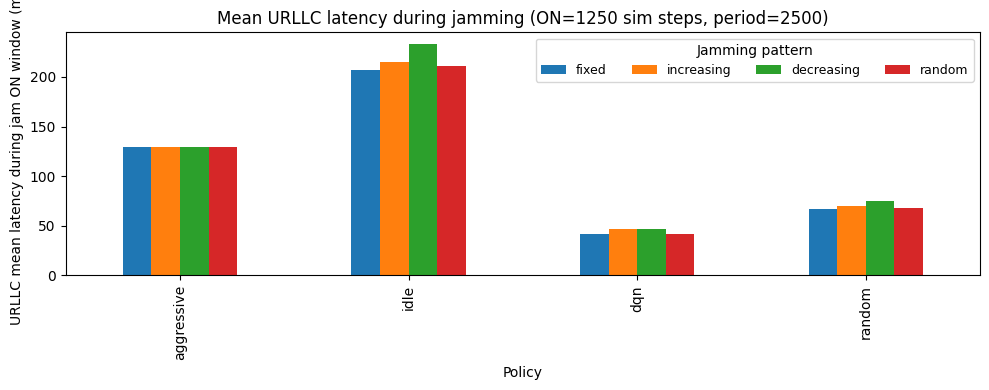

/tmp/ipykernel_1113248/2720928440.py:305: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  thr_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_thr_mbps", aggfunc="mean")


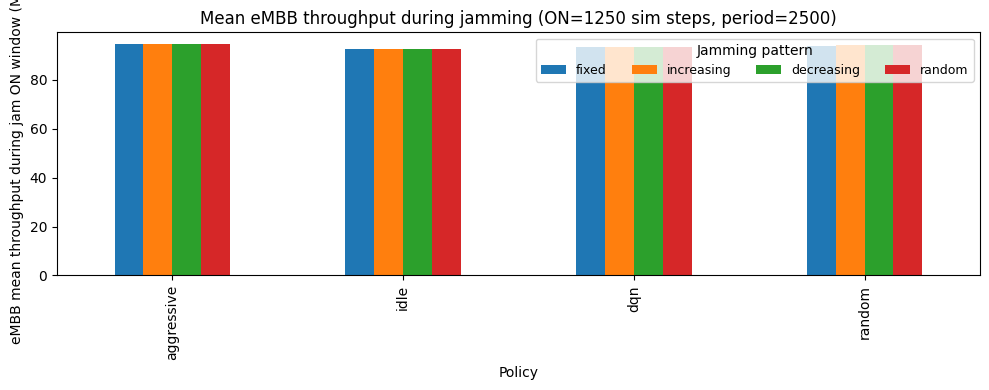


[OK] Saved CSV + plots to: /home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/tb_logs/res_validator/_plots


<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

In [11]:
#!/usr/bin/env python3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing import event_accumulator

# -----------------------------
# User settings
# -----------------------------
ROOT = Path("../../tb_logs/res_validator")  # <-- change if needed

POLICIES = ["aggressive", "idle", "dqn", "random"]#, "qrdqn"]
PATTERNS = ["fixed", "increasing", "decreasing", "random"]

JAM_THRESHOLD = 0.999
DEADLINE_MS = 1.0

# Your jammer (SIM steps)
JAM_ON_STEPS_SIM = 1250
JAM_PERIOD_STEPS_SIM = 2500

PRE_STEPS = 0
POST_EXTRA = 0

# -----------------------------
# Helpers
# -----------------------------
def infer_tb_step_stride(steps: np.ndarray) -> int:
    if steps is None or len(steps) < 3:
        return 1
    d = np.diff(np.asarray(steps, dtype=int))
    d = d[d > 0]
    if len(d) == 0:
        return 1
    return max(1, int(np.median(d)))

def sim_to_tb_steps(sim_steps: int, tb_stride: int) -> int:
    return int(np.ceil(sim_steps / float(tb_stride)))

def merge_asof_by_step(base: pd.DataFrame, other: pd.DataFrame, tolerance: int) -> pd.DataFrame:
    if other is None or other.empty:
        return base
    a = base.sort_values("step").copy()
    b = other.sort_values("step").copy()
    merged = pd.merge_asof(a, b, on="step", direction="nearest", tolerance=tolerance, suffixes=("", "_y"))
    if "wall_time_y" in merged.columns and "wall_time" in merged.columns:
        merged.drop(columns=["wall_time_y"], inplace=True)
    return merged

def detect_jam_starts(df: pd.DataFrame, min_gap_tb_steps: int) -> list[int]:
    if df.empty or "effective_prb_ratio" not in df.columns:
        return []
    steps = df["step"].to_numpy(dtype=int)
    jammed = (df["effective_prb_ratio"].to_numpy() < JAM_THRESHOLD).astype(np.int32)

    starts = []
    prev = 0
    last_start_step = -10**18
    for i in range(len(jammed)):
        if jammed[i] == 1 and prev == 0:
            s0 = int(steps[i])
            if s0 - last_start_step >= min_gap_tb_steps:
                starts.append(s0)
                last_start_step = s0
        prev = jammed[i]
    return starts

def event_aligned_mean_by_index(df: pd.DataFrame, col: str, start_steps: list[int], pre: int, post: int) -> pd.DataFrame:
    if df.empty or col not in df.columns or not start_steps:
        return pd.DataFrame(columns=["t_rel", "mean", "std", "n"])

    d = df[["step", col]].dropna().sort_values("step").reset_index(drop=True)
    if d.empty:
        return pd.DataFrame(columns=["t_rel", "mean", "std", "n"])

    steps = d["step"].to_numpy(dtype=int)
    vals = d[col].to_numpy(dtype=float)

    t_rels = np.arange(-pre, post, dtype=int)
    aligned = []

    for s0 in start_steps:
        i0 = int(np.searchsorted(steps, s0))
        if i0 >= len(steps):
            i0 = len(steps) - 1
        if i0 > 0 and abs(steps[i0] - s0) > abs(steps[i0 - 1] - s0):
            i0 -= 1

        row = []
        for tr in t_rels:
            i = i0 + tr
            row.append(vals[i] if (0 <= i < len(vals)) else np.nan)
        aligned.append(row)

    A = np.asarray(aligned, dtype=float)

    n = np.sum(np.isfinite(A), axis=0)
    mean = np.full(A.shape[1], np.nan)
    std  = np.full(A.shape[1], np.nan)

    ok = n > 0
    if np.any(ok):
        mean[ok] = np.nanmean(A[:, ok], axis=0)
        std[ok]  = np.nanstd(A[:, ok], axis=0)

    return pd.DataFrame({"t_rel": t_rels, "mean": mean, "std": std, "n": n})

# -----------------------------
# FAST: index event files once
# -----------------------------
def index_event_files_by_policy(root: Path, policies: list[str]) -> dict[str, list[Path]]:
    """
    Returns: policy -> list of event files under that policy (one rglob per policy)
    """
    out = {}
    for pol in policies:
        pdir = root / pol
        if not pdir.exists():
            out[pol] = []
            continue
        evs = list(pdir.rglob("events.out.tfevents.*"))
        # newest first
        evs.sort(key=lambda p: p.stat().st_mtime, reverse=True)
        out[pol] = evs
    return out

def find_event_file_from_index(index: dict[str, list[Path]], policy: str, test_name: str) -> Path | None:
    """
    Uses pre-indexed list. Just scans the list in memory (fast).
    """
    for ev in index.get(policy, []):
        if test_name in str(ev.parent):
            return ev
    return None

# -----------------------------
# FAST: read all tags from ONE Reload
# -----------------------------
def read_scalars_once(event_file: Path, tags: list[str]) -> dict[str, pd.DataFrame]:
    """
    One EventAccumulator Reload, then pull all requested tags.
    Returns dict tag -> DataFrame(step, wall_time, value)
    """
    ea = event_accumulator.EventAccumulator(str(event_file), size_guidance={"scalars": 0})
    ea.Reload()

    available = set(ea.Tags().get("scalars", []))
    out = {}
    for tag in tags:
        if tag not in available:
            out[tag] = pd.DataFrame(columns=["step", "wall_time", "value"])
            continue
        evs = ea.Scalars(tag)
        df = pd.DataFrame(
            {"step": [e.step for e in evs], "wall_time": [e.wall_time for e in evs], "value": [e.value for e in evs]}
        ).sort_values("step")
        out[tag] = df
    return out

def load_one_run_fast(event_file: Path) -> pd.DataFrame | None:
    tags = ["latency/urllc", "throughput/embb_mbps", "prb/effective_ratio", "obs/reserve_used_prb"]
    scal = read_scalars_once(event_file, tags)

    lat = scal["latency/urllc"].rename(columns={"value": "latency_sec"})
    thr = scal["throughput/embb_mbps"].rename(columns={"value": "embb_mbps"})
    prb = scal["prb/effective_ratio"].rename(columns={"value": "effective_prb_ratio"})
    rsv = scal["obs/reserve_used_prb"].rename(columns={"value": "reserve_used_prb"})

    if lat.empty or thr.empty or prb.empty:
        return None

    tb_stride = infer_tb_step_stride(prb["step"].to_numpy())
    tolerance = max(1, tb_stride // 2)

    df = prb.copy()
    df = merge_asof_by_step(df, lat, tolerance=tolerance)
    df = merge_asof_by_step(df, thr, tolerance=tolerance)
    if not rsv.empty:
        df = merge_asof_by_step(df, rsv, tolerance=tolerance)
    else:
        df["reserve_used_prb"] = np.nan

    df["latency_ms"] = df["latency_sec"] * 1000.0
    df["tb_stride"] = tb_stride
    return df

# -----------------------------
# Main
# -----------------------------
print(f"[INFO] Indexing event files under: {ROOT.resolve()}")
ev_index = index_event_files_by_policy(ROOT, POLICIES)
for pol in POLICIES:
    print(f"[INFO] {pol}: {len(ev_index.get(pol, []))} event files found")

aligned_lat = {}
aligned_thr = {}
aligned_eff = {}
summary_rows = []

total_jobs = len(POLICIES) * len(PATTERNS)
job_i = 0

for policy in POLICIES:
    for pat in PATTERNS:
        job_i += 1
        test_name = f"gym_from_testing_config_1ms_10s_8UE_jam_pattern_{pat}"
        ev = find_event_file_from_index(ev_index, policy, test_name)

        print(f"[{job_i}/{total_jobs}] policy={policy:<10} pattern={pat:<10} -> ", end="")
        if ev is None:
            print("NO EVENT FILE")
            summary_rows.append({
                "policy": policy, "pattern": pat, "n_jam_events": 0,
                "tb_stride": np.nan, "jam_on_tb_steps": np.nan, "period_tb_steps": np.nan,
                "jam_lat_ms": np.nan, "violation_pct": np.nan, "jam_thr_mbps": np.nan,
                "jam_reserve_used": np.nan, "event_file": None,
            })
            continue

        print(f"loading {ev.name}")

        df = load_one_run_fast(ev)
        if df is None:
            summary_rows.append({
                "policy": policy, "pattern": pat, "n_jam_events": 0,
                "tb_stride": np.nan, "jam_on_tb_steps": np.nan, "period_tb_steps": np.nan,
                "jam_lat_ms": np.nan, "violation_pct": np.nan, "jam_thr_mbps": np.nan,
                "jam_reserve_used": np.nan, "event_file": str(ev),
            })
            continue

        tb_stride = int(df["tb_stride"].iloc[0])
        jam_on_tb = sim_to_tb_steps(JAM_ON_STEPS_SIM, tb_stride)
        period_tb = sim_to_tb_steps(JAM_PERIOD_STEPS_SIM, tb_stride)

        PRE_TB = PRE_STEPS
        POST_TB = period_tb + POST_EXTRA
        MIN_GAP_TB = max(1, period_tb - 1)

        starts = detect_jam_starts(df, min_gap_tb_steps=MIN_GAP_TB)

        lat_al = event_aligned_mean_by_index(df, "latency_ms", starts, pre=PRE_TB, post=POST_TB)
        thr_al = event_aligned_mean_by_index(df, "embb_mbps", starts, pre=PRE_TB, post=POST_TB)
        eff_al = event_aligned_mean_by_index(df, "effective_prb_ratio", starts, pre=PRE_TB, post=POST_TB)

        aligned_lat[(pat, policy)] = lat_al
        aligned_thr[(pat, policy)] = thr_al
        aligned_eff[(pat, policy)] = eff_al

        # Summary during jam ON window [0, jam_on_tb)
        if not lat_al.empty:
            s = lat_al[(lat_al.t_rel >= 0) & (lat_al.t_rel < jam_on_tb)]["mean"].to_numpy()
            jam_lat_ms = float(np.nanmean(s)) if len(s) else np.nan
            violation_pct = float(np.mean(s > DEADLINE_MS) * 100.0) if len(s) else np.nan
        else:
            jam_lat_ms = np.nan
            violation_pct = np.nan

        if not thr_al.empty:
            s = thr_al[(thr_al.t_rel >= 0) & (thr_al.t_rel < jam_on_tb)]["mean"].to_numpy()
            jam_thr_mbps = float(np.nanmean(s)) if len(s) else np.nan
        else:
            jam_thr_mbps = np.nan

        df["jammed"] = df["effective_prb_ratio"] < JAM_THRESHOLD
        jam_df = df[df["jammed"]]
        jam_reserve_used = float(jam_df["reserve_used_prb"].mean()) if not jam_df.empty else np.nan

        summary_rows.append({
            "policy": policy,
            "pattern": pat,
            "n_jam_events": len(starts),
            "tb_stride": tb_stride,
            "jam_on_tb_steps": jam_on_tb,
            "period_tb_steps": period_tb,
            "jam_lat_ms": jam_lat_ms,
            "violation_pct": violation_pct,
            "jam_thr_mbps": jam_thr_mbps,
            "jam_reserve_used": jam_reserve_used,
            "event_file": str(ev),
        })

summary_df = pd.DataFrame(summary_rows)
summary_df["policy"] = pd.Categorical(summary_df["policy"], categories=POLICIES, ordered=True)
summary_df["pattern"] = pd.Categorical(summary_df["pattern"], categories=PATTERNS, ordered=True)

print("\n=== Summary (head) ===")
print(summary_df.head(10))
print("\n=== Summary (full) ===")
print(summary_df)

# -----------------------------
# Bar charts
# -----------------------------
lat_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_lat_ms", aggfunc="mean")
ax = lat_pivot.plot(kind="bar", figsize=(10, 4))
ax.set_ylabel("URLLC mean latency during jam ON window (ms)")
ax.set_xlabel("Policy")
ax.set_title("Mean URLLC latency during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.show()

thr_pivot = summary_df.pivot_table(index="policy", columns="pattern", values="jam_thr_mbps", aggfunc="mean")
ax = thr_pivot.plot(kind="bar", figsize=(10, 4))
ax.set_ylabel("eMBB mean throughput during jam ON window (Mbps)")
ax.set_xlabel("Policy")
ax.set_title("Mean eMBB throughput during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.show()

# Save outputs
OUT_DIR = ROOT / "_plots"
OUT_DIR.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(OUT_DIR / "summary_latency_throughput.csv", index=False)

plt.figure(figsize=(10, 4))
ax = lat_pivot.plot(kind="bar")
ax.set_ylabel("URLLC mean latency during jam ON window (ms)")
ax.set_xlabel("Policy")
ax.set_title("Mean URLLC latency during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "barchart_latency_ms.png", dpi=200)
plt.close()

plt.figure(figsize=(10, 4))
ax = thr_pivot.plot(kind="bar")
ax.set_ylabel("eMBB mean throughput during jam ON window (Mbps)")
ax.set_xlabel("Policy")
ax.set_title("Mean eMBB throughput during jamming (ON=1250 sim steps, period=2500)")
ax.legend(title="Jamming pattern", ncols=4, fontsize=9)
plt.tight_layout()
plt.savefig(OUT_DIR / "barchart_throughput_mbps.png", dpi=200)
plt.close()

print(f"\n[OK] Saved CSV + plots to: {OUT_DIR.resolve()}")


## Training Plots

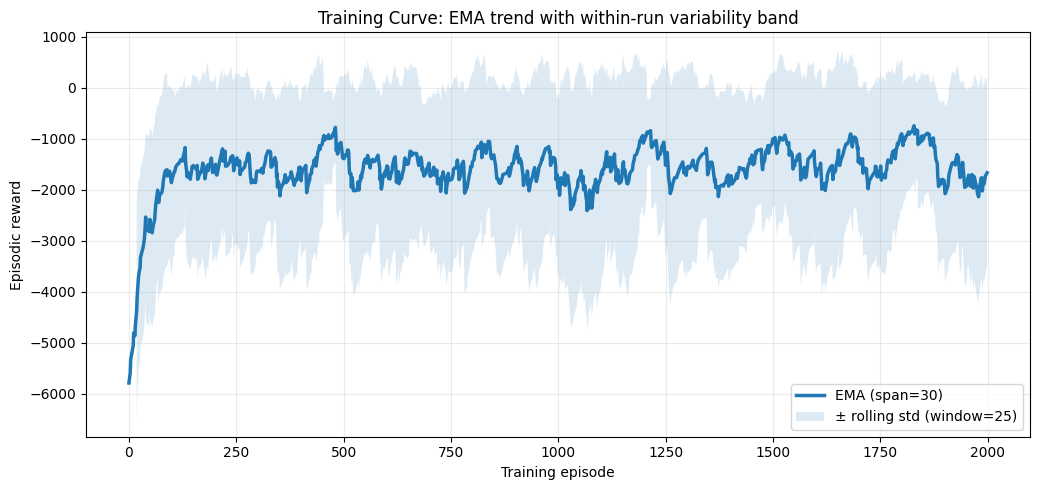

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

csv_path = Path("../../tb_logs/20260121_125953_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch64_buffer100000_total18.csv")
df = pd.read_csv(csv_path).copy()

df = df.rename(columns={"Wall time": "wall_time", "Step": "step", "Value": "reward"})
df = df.dropna(subset=["step", "reward"])
df["step"] = pd.to_numeric(df["step"], errors="coerce")
df["reward"] = pd.to_numeric(df["reward"], errors="coerce")
df = df.dropna(subset=["step", "reward"]).sort_values("step").reset_index(drop=True)

use_episode_index = False
x = np.arange(len(df)) if use_episode_index else df["step"].to_numpy()

# --- Optional: clip extreme negative spikes for visualization only
q_low = df["reward"].quantile(0.05)       # bottom 5%
r = df["reward"].clip(lower=q_low)

# --- Trend line: EMA
ema_span = max(10, int(len(df) * 0.03))
ema = r.ewm(span=ema_span, adjust=False).mean()

# --- Variability band: rolling std around the EMA (within-run volatility)
band_w = 25
roll_std = r.rolling(window=band_w, min_periods=max(5, band_w//3)).std()

# Sometimes std can be NaN at the beginning; mask those
valid = ~roll_std.isna()

plt.figure(figsize=(10.5, 5))
#plt.plot(x, r.to_numpy(), linewidth=1, alpha=0.20, label="Raw episodic reward (clipped)")
plt.plot(x, ema.to_numpy(), linewidth=2.5, label=f"EMA (span={ema_span})")

# Shaded band: EMA ± rolling std
plt.fill_between(
    x[valid.to_numpy()],
    (ema[valid] - roll_std[valid]).to_numpy(),
    (ema[valid] + roll_std[valid]).to_numpy(),
    alpha=0.15,
    label=f"± rolling std (window={band_w})"
)

plt.xlabel("Episode" if use_episode_index else "Training episode")
plt.ylabel("Episodic reward")
plt.title("Training Curve: EMA trend with within-run variability band")
plt.grid(True, alpha=0.25)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


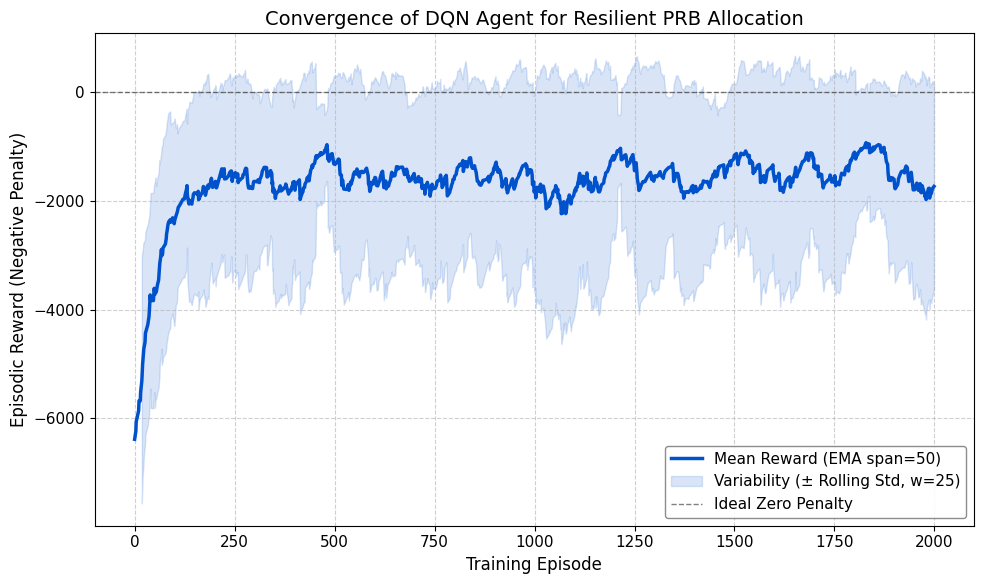

Num points in CSV: 1000
Step min/max: 0 1999
Unique steps: 1000
First 5 steps: [0, 3, 4, 10, 11]
Last 5 steps: [1991, 1992, 1993, 1995, 1999]


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# --- Load Data ---
csv_path = Path("../../tb_logs/20260121_125953_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch64_buffer100000_total18.csv")

#csv_path = Path("../../tb_logs/20260123_215932_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch64_buffer100000_total18.csv")
df = pd.read_csv(csv_path).copy()

df = df.rename(columns={"Wall time": "wall_time", "Step": "step", "Value": "reward"})
df = df.dropna(subset=["step", "reward"])
df["step"] = pd.to_numeric(df["step"], errors="coerce")
df["reward"] = pd.to_numeric(df["reward"], errors="coerce")
df = df.dropna(subset=["step", "reward"]).sort_values("step").reset_index(drop=True)

# --- X-Axis Handling ---
# Paper mentions 40,000 episodes[cite: 256]. 
# Ensure 'step' corresponds to what you want to show (Episodes vs Steps).
use_episode_index = False
x = np.arange(len(df)) if use_episode_index else df["step"].to_numpy()

# --- Data Smoothing ---
# 1. Clip extreme outliers (bottom 1%) to remove startup noise while keeping failures visible
q_low = df["reward"].quantile(0.02) 
r = df["reward"].clip(lower=q_low)

# 2. EMA Trend
# Increased span slightly to make the trend clearer for the paper
ema_span = max(10, int(len(df) * 0.05)) 
ema = r.ewm(span=ema_span, adjust=False).mean()

# 3. Variability band (Rolling STD)
band_w = 25
roll_std = r.rolling(window=band_w, min_periods=max(5, band_w//3)).std()
valid = ~roll_std.isna()

# --- Plotting Style for Paper ---
# Setting global font sizes to ensure readability when the image is resized in a PDF
plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 16
})

plt.figure(figsize=(10, 6))

# Main EMA Line (Thicker for visibility)
plt.plot(x, ema.to_numpy(), color='#0052cc', linewidth=2.5, label=f"Mean Reward (EMA span={ema_span})")

# Variability Band (Lighter blue)
plt.fill_between(
    x[valid.to_numpy()],
    (ema[valid] - roll_std[valid]).to_numpy(),
    (ema[valid] + roll_std[valid]).to_numpy(),
    color='#0052cc',
    alpha=0.15,
    label=f"Variability (± Rolling Std, w={band_w})"
)

# Optional: Add a baseline at 0 (Perfect Score)
plt.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.5, label="Ideal Zero Penalty")

# Labels and Title based on your paper context
plt.xlabel("Training Episode")
plt.ylabel("Episodic Reward (Negative Penalty)")
plt.title("Convergence of DQN Agent for Resilient PRB Allocation")

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc="lower right", frameon=True, framealpha=0.9, edgecolor='gray')
plt.tight_layout()

# Save high-res for paper
plt.savefig("training_convergence.pdf", dpi=300) 
plt.show()
print("Num points in CSV:", len(df))
print("Step min/max:", df["step"].min(), df["step"].max())
print("Unique steps:", df["step"].nunique())
print("First 5 steps:", df["step"].head().to_list())
print("Last 5 steps:", df["step"].tail().to_list())


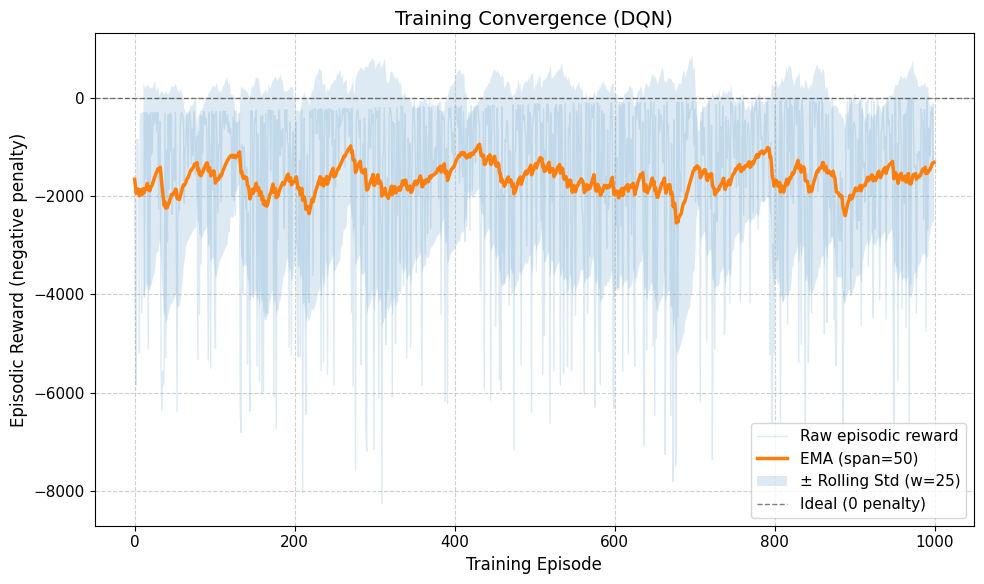

In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

csv_path = Path("../../tb_logs/20260123_215932_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch64_buffer100000_total18.csv")
df = pd.read_csv(csv_path).copy()

df = df.rename(columns={"Wall time":"wall_time", "Step":"step", "Value":"reward"})
df = df.dropna(subset=["reward"])
df["reward"] = pd.to_numeric(df["reward"], errors="coerce")
df = df.dropna(subset=["reward"]).reset_index(drop=True)

# --- X axis: episode index (safe default) ---
x = np.arange(len(df))

# --- Smooth trend (pick ONE) ---
ema_span = 50
ema = df["reward"].ewm(span=ema_span, adjust=False).mean()

# Variability band: rolling std around RAW reward (not clipped)
band_w = 25
roll_std = df["reward"].rolling(band_w, min_periods=band_w//2).std()

plt.figure(figsize=(10,6))

# Raw (light) + EMA (bold) helps readers trust the trend
plt.plot(x, df["reward"], alpha=0.15, linewidth=1, label="Raw episodic reward")
plt.plot(x, ema, linewidth=2.5, label=f"EMA (span={ema_span})")

valid = roll_std.notna()
plt.fill_between(
    x[valid],
    (ema[valid] - roll_std[valid]),
    (ema[valid] + roll_std[valid]),
    alpha=0.15,
    label=f"± Rolling Std (w={band_w})"
)

plt.axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.5, label="Ideal (0 penalty)")

plt.xlabel("Training Episode")
plt.ylabel("Episodic Reward (negative penalty)")
plt.title("Training Convergence (DQN)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [41]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
import pandas as pd
from pathlib import Path

event_file = Path("../../tb_logs/res_dqn/20260123_215007_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch64_buffer100000_total18/events.out.tfevents.1769223007.elahe-LEGION-T7-34IAS10.1224269.0")

# Load
ea = EventAccumulator(str(event_file))
ea.Reload()

# 1) See what scalar tags exist
tags = ea.Tags()
print("Scalar tags:")
for t in tags.get("scalars", []):
    print(" -", t)

# 2) Choose the correct tag name (common ones shown below)
#    Replace this with the exact one you see printed above.
TAG = "episode_return"   # e.g., "rollout/ep_rew_mean", "train/episode_return", etc.

events = ea.Scalars(TAG)  # list of ScalarEvent(wall_time, step, value)

df = pd.DataFrame({
    "wall_time": [e.wall_time for e in events],
    "step":      [e.step for e in events],
    "value":     [e.value for e in events],
}).sort_values("step").reset_index(drop=True)

print("Extracted points:", len(df))
print("Step range:", df["step"].min(), "to", df["step"].max())

out = Path("20260123_215007_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch64_buffer100000_total18_FULL.csv")
df.to_csv(out, index=False)
print("Saved:", out.resolve())


Scalar tags:
 - reward
 - reward_cumulative
 - reward_smooth
 - epsilon
 - action_idx
 - eMBB/throughput_bps
 - URLLC/throughput_bps
 - eMBB/queue_bytes
 - URLLC/queue_bytes
 - URLLC/latency_s
 - pool/effective_prb_ratio
 - loss
 - episode_return
 - episode_return_vs_step
 - episode_length
 - episode_reward_parts/reward_base
 - episode_reward_parts/penalty_embb
 - episode_reward_parts/penalty_latency
 - episode_reward_parts/penalty_reserve
 - episode/penalty_embb_mean
 - episode/penalty_latency_mean
 - episode/penalty_reserve_mean
 - episode/violation_rate_latency
 - episode/violation_rate_embb
 - episode/latency_excess_ms_p90
 - episode/latency_excess_ms_p95
 - episode/embb_gap_mbps_p90
 - episode/embb_gap_mbps_p95
 - episode/mean_effective_prb_ratio
 - episode/mean_reserve_used_ratio
Extracted points: 11
Step range: 0 to 10
Saved: /home/elahe/user/elahe/RL_work/Resilient_PRB_allocation/backend/notebooks/Resilient_validation/20260123_215007_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch6

In [45]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
from pathlib import Path

logdir = Path("../../tb_logs/res_dqn/20260123_215007_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch64_buffer100000_total18")
ea = EventAccumulator(str(logdir), size_guidance={"scalars": 0})
ea.Reload()

rows = []
for tag in ea.Tags().get("scalars", []):
    ev = ea.Scalars(tag)
    steps = [e.step for e in ev]
    rows.append((tag, len(ev), max(steps) if steps else None))

rows.sort(key=lambda x: (x[1], x[2] if x[2] is not None else -1), reverse=True)

print("--- tag | n_points | max_step ---")
for tag, n, mx in rows:
    print(f"{tag:35s} | {n:6d} | {mx}")


--- tag | n_points | max_step ---
reward                              |  11523 | 115340
reward_cumulative                   |  11523 | 115340
reward_smooth                       |  11523 | 115340
epsilon                             |  11523 | 115340
action_idx                          |  11523 | 115340
eMBB/throughput_bps                 |  11523 | 115340
URLLC/throughput_bps                |  11523 | 115340
eMBB/queue_bytes                    |  11523 | 115340
URLLC/queue_bytes                   |  11523 | 115340
URLLC/latency_s                     |  11523 | 115340
pool/effective_prb_ratio            |  11523 | 115340
loss                                |  11460 | 115340
episode_return_vs_step              |     11 | 109990
episode_return                      |     11 | 10
episode_length                      |     11 | 10
episode_reward_parts/reward_base    |     11 | 10
episode_reward_parts/penalty_embb   |     11 | 10
episode_reward_parts/penalty_latency |     11 | 10
episode_rewar

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

csv_path = Path("../../tb_logs/20260123_215932_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch64_buffer100000_total18.csv")
df = pd.read_csv(csv_path).rename(columns={"Wall time":"wall_time","Step":"step","Value":"episode_return"})
df["step"] = pd.to_numeric(df["step"], errors="coerce")
df["episode_return"] = pd.to_numeric(df["episode_return"], errors="coerce")
df = df.dropna(subset=["step","episode_return"]).sort_values("step").reset_index(drop=True)

x = np.arange(len(df))
y = df["episode_return"].to_numpy()

window = 50  # good for your file; try 25/50/100
s = pd.Series(y)

trend = s.rolling(window=window, min_periods=max(5, window//5)).mean().to_numpy()
q10   = s.rolling(window=window, min_periods=max(5, window//5)).quantile(0.10).to_numpy()
q90   = s.rolling(window=window, min_periods=max(5, window//5)).quantile(0.90).to_numpy()

plt.figure(figsize=(10,4))
#plt.plot(x, y, alpha=0.20, linewidth=1, label="raw")
plt.fill_between(x, q10, q90, alpha=0.20, label="10–90% band (rolling)")
plt.plot(x, trend, linewidth=2, label=f"rolling mean (window={window})")
plt.xlabel("Episode")
plt.ylabel("Episode return")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("training_convergence.pdf", dpi=300) 
plt.show()


KeyError: 'episode_return'

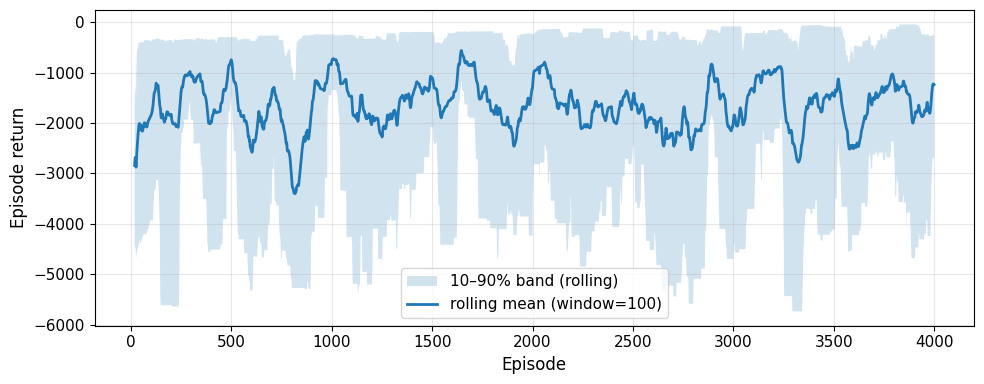

In [49]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

csv_path = Path("../../tb_logs/20260123_215932_resdqn_lr0.0001_gamma0.99_eps1.0-0.05_batch64_buffer100000_total18.csv")
df = pd.read_csv(csv_path).rename(columns={"Wall time":"wall_time","Step":"step","Value":"episode_return"})

df["step"] = pd.to_numeric(df["step"], errors="coerce")
df["episode_return"] = pd.to_numeric(df["episode_return"], errors="coerce")
df = df.dropna(subset=["step","episode_return"]).sort_values("step").reset_index(drop=True)

# ----------------------------
# Build a full 0..3999 episode grid
# ----------------------------
E = int(df["step"].max()) + 1          # should be 4000
x = np.arange(E)                       # 0..3999

# Put logged returns at their episode step, then fill gaps
s_sparse = pd.Series(df["episode_return"].to_numpy(),
                     index=df["step"].astype(int).to_numpy()).sort_index()

# Reindex to all episodes and fill missing episodes
# (linear interpolation is usually fine for convergence curves)
s_full = (s_sparse
          .reindex(x)
          .interpolate(method="linear")
          .ffill()
          .bfill())

y_full = s_full.to_numpy()

# ----------------------------
# Rolling stats on the full 4000-length series
# ----------------------------
window = 100  # in episodes
s = pd.Series(y_full)

minp = max(5, window//5)
trend = s.rolling(window=window, min_periods=minp).mean().to_numpy()
q10   = s.rolling(window=window, min_periods=minp).quantile(0.10).to_numpy()
q90   = s.rolling(window=window, min_periods=minp).quantile(0.90).to_numpy()

# ----------------------------
# Plot
# ----------------------------
plt.figure(figsize=(10,4))
plt.fill_between(x, q10, q90, alpha=0.20, label="10–90% band (rolling)")
plt.plot(x, trend, linewidth=2, label=f"rolling mean (window={window})")
plt.xlabel("Episode")
plt.ylabel("Episode return")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("training_convergence.pdf", dpi=300)
plt.show()
